# Visualize results of 20250604 NCD aster analysis
`{aduarte,gsalmon}@caltech.edu`

In [1]:
## IMPORTS
import pandas as pd
import numpy as np
import h5py
import glob
import scipy

######### gabe hacky styling to emulate some of PBoC Phillips lab style conventions, however hacky. tries to make easier for nigel++
## Styling
import matplotlib
import matplotlib.ticker as ticker
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context("poster")
# sns.set_style('ticks')

import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Set the property to save figures with text as text, not paths
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# default good PBoC colors
baseBlendColor=(224/255, 219/255, 209/255,1) # default background for plots
contrastColor=(209/255, 193/255, 171/255,1) # slightly darker tan for contrasts, e.g. in inset boxes
yellowTanHighlightBoxColor='#FEF0C6'
goodGreyGreenArrowColor='#CCD4C9'

### Griffin style invocation

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.path import Path
from matplotlib.patches import BoxStyle
from matplotlib.offsetbox import AnchoredText

def plotting_style(grid=False):
    """
    Sets the style to the publication style. To instantiate, simply call
    plotting_style() at the beginning of your script or notebook to force
    all matplotlib plots to adopt the scheme.

    Parameters
    ----------
    grid: bool
      If True, plots will have a thin, white grid in the background. Default
      is False.

    Returns
    -------
    colors: dict
      Returns a dictionary of the standard PBoC 2e color palette.
    """
    rc = {'axes.facecolor': '#E3DCD0',
#               'axes.spines.top': False,
#               'axes.spines.right': False,
#               'axes.spines.left': False,  # Ensure left spine is present
#               'axes.spines.bottom': False,  # Ensure bottom spine is present
#               'axes.spines.left': False, #{'color': '#E3DCD0', 'linewidth': 1.5},  # Set the spine color to the background color
#               'axes.spines.bottom': False, #{'color': '#E3DCD0', 'linewidth': 1.5},  # Set the spine color to the background color
          #'font.family': '/usr/share/fonts/truetype/LucidaSansOT.otf', #'LucidaSansOT.otf',
          'grid.linestyle': '-',
          'grid.linewidth': 0.5,
          'grid.alpha': 0.75,
          'grid.color': '#ffffff',
          'axes.grid': grid,
          'ytick.direction': 'in',
          'xtick.direction': 'in',
          'xtick.gridOn': grid,
          'ytick.gridOn': grid,
#               'ytick.major.width':8,
#               'xtick.major.width':8,
#               'ytick.major.size': 8,
#               'xtick.major.size': 8,
          'mathtext.fontset': 'stixsans',
          'mathtext.sf': 'sans',
          'legend.frameon': True,
          'legend.facecolor': '#FFEDCE',
          'figure.dpi': 150,
          'xtick.color': 'k',
          'ytick.color': 'k'
         }
    plt.rc('text.latex', preamble=r'\usepackage{sfmath}')
    plt.rc('mathtext', fontset='stixsans', sf='sans')
    sns.set_style('darkgrid', rc=rc)
    return color_palette()

def color_palette():
    """
    Returns a dictionary of the PBOC color palette
    """
    return {'green': '#7AA974', 'light_green': '#BFD598',
              'pale_green': '#DCECCB', 'yellow': '#EAC264',
              'light_yellow': '#F3DAA9', 'pale_yellow': '#FFEDCE',
              'blue': '#738FC1', 'light_blue': '#A9BFE3',
              'pale_blue': '#C9D7EE', 'red': '#D56C55', 'light_red': '#E8B19D',
              'pale_red': '#F1D4C9', 'purple': '#AB85AC',
              'light_purple': '#D4C2D9', 'dark_green':'#7E9D90', 'dark_brown':'#905426'}

def titlebox(
    ax, text, color, bgcolor=None, size=8, boxsize=0.1, pad=0.05, **kwargs
):
    """
    Sets a colored title box above the plot, spanning the entire plot width.

    Parameters
    ----------
    ax : matplotlib axis object
      The axis on which you want to add the titlebox.
    text: str
      The title tect
    bgcolor: str or None
      The background color of the title box. Default is no color (blank).
    size:  int
      Size of the text font
    boxsize: float [0, 1]
      Fraction of the total plot height to be occupied by the box. Default is 10% (0.1).
    pad: float
      The padding space between the title box and the top of the plot.

    """
    boxsize=str(boxsize * 100)  + '%'
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("top", size=boxsize, pad=pad)
    cax.get_xaxis().set_visible(False)
    cax.get_yaxis().set_visible(False)
    cax.spines["top"].set_visible(False)
    cax.spines["right"].set_visible(False)
#     cax.spines["bottom"].set_visible(False)
#     cax.spines["left"].set_visible(False)

#     cax.spines["bottom"].set_visible(True)
#     cax.spines["left"].set_visible(True)
#     cax.spines["left"].set_color("white")
#     cax.spines["bottom"].set_color("white")
#     cax.spines["bottom"].set_color("white")

#     cax.set_ticks_position('both')  # Adding ticks to both top and bottom
#     cax.yaxis.set_tick_params(direction='in', which='both', color='white')  # The bottom will maintain the default of 'out'


    plt.setp(cax.spines.values(), color=color)
    if bgcolor != None:
        cax.set_facecolor(bgcolor)
    else:
        cax.set_facecolor("white")
    at = AnchoredText(text, loc=10, frameon=False, prop=dict(size=size, color=color))
    cax.add_artist(at)


### Now actually call it
plotting_style()

import matplotlib.patheffects as pe
matplotlib.rcParams['axes.autolimit_mode'] = 'data'


In [2]:
import matplotlib.ticker as ticker

## Analysis-specific visualization
20241116
* [NCD dimers] (one of 0.375uM ,...)
* date (one of 12-07-2023, 12-11-2023, 12-12-2023)
* Pos (one of 0, 1, 2)

#### An analyzed_data gname directory (each position=repeat in a date) will have these fields:
'all_rATPavgs.h5', 'all_rATPbins.h5', 'all_rMotavgs.h5', 'all_rMotbins.h5', 
'timesATP.h5', 'timesMot.h5', 'mot_centCrop.h5', 'ATP_centCrop.h5', 
'imshape.h5', 'mask_coords.h5', 'mot.h5', 'ATP.h5'

In [3]:
# Place where the metadata file is found
metaDataFile='../../data/aster/20241114_footageComments_gnames.csv'
metaDF = pd.read_csv(metaDataFile)

# ## Includes
goodSubset=metaDF[metaDF['Note'].apply(lambda x: 'GOOD' in x)]#[np.isin(metaDF['Note'], "GOOD")]
gnameList=list('../../data/aster/'+goodSubset['child']+'/'+goodSubset['FILE']+'/'+goodSubset['Position'])

In [4]:
# def summarizeGname(gname,motName='_NCD_dimers_'):
#     date=gname.split('Ncd_Aster_assay_')[-1].split('/')[0]
#     position=gname.split('/')[-1].split('_Pos')[-1].split('.ome.tif')[0]
#     #motConc=gname.split(motName)[0].split('_')[-1]
#     motConc=gname.upper().split(motName.upper())[0].split('_')[-1] # THIS PRESERVES UNITS
#     motConcUM=float(motConc.strip('UM'))
#     atpConc=gname.split('ATP')[0].split('_')[-1]
#     return date+'_Pos'+position, motConcUM, atpConc

In [5]:
# allProps=np.array([summarizeGname(gname) for gname in gnameList])
# allProps

In [6]:
umperpixel = 0.59 #um # QUESTION for ANA: should this be 0.59/2?? 

In [7]:
def read_h5py(path_name, excludes=[]):
    # Glob for directory parsing to get all .h5 files in the specified path
    h5files = glob.glob(path_name + '/*.h5')
    for excl in excludes:
        h5files=[file for file in h5files if excl not in file]
        
    #print("HDF5 files found:", h5files)
    
    # Dictionary to store arrays from each file
    all_data = {}
    
    for file in h5files:
        file_data = []  # List to hold datasets for the current file
        
        with h5py.File(file, 'r') as h5file:
            def load_data(name, obj):
                if isinstance(obj, h5py.Dataset):
                    file_data.append(obj[:])  # Append dataset as a NumPy array
            
            # Visit all datasets in the file and load them into file_data
            h5file.visititems(load_data)
        
        #slice by 8 since the date has 8 didgits
        field_name = file.split('.h5')[0].split('tif')[-1][15:] #BRO, 15 is the number of digits in how we save datetime -> 20241114_201131 (formerly we had 8 since we didnt include time)
        #print(file + '\n')
        #print(field_name+ '\n')
            
        # Add this file's data to all_data with the filename as the key
        all_data[field_name] = file_data[0]
        
        
    return all_data

In [8]:
# ### ATP - HACKish but whatever
# uniqueConcs=np.unique(allProps[:,1])
# uniqueRepeats=np.unique(allProps[:,0])

# ### ATP
# fig, axs = plt.subplots(nrows=len(uniqueConcs), 
#                         ncols=len(uniqueRepeats),
#                         figsize=(32,20))
# for g in range(len(gnameList)):
#     thisConcIdx=np.where(uniqueConcs==allProps[g, 1])[0][0]
    
#     #thisSubplIdx=(np.where(uniqueConcs==allProps[g, 1])[0][0], np.where(uniqueRepeats==allProps[g, 0])[0][0])
#     axs[thisSubplIdx].set_title(allProps[g,0], fontsize=14, color='grey')#gnameList[g].split('/')[-1], fontsize=10)

#     ## get this gname's analyzed data files & parse
#     #axs[thisSubplIdx].plot(1,1, 'ro')
#     h5spath=gnameList[g].split('data')[0]+'analyzed_data'+gnameList[g].split('data')[1]+'/'
#     h5dic = read_h5py(h5spath)

#     # this is (numTimes, numRbinMidpoints)
#     rATPmids=h5dic['all_rATPbins']*umperpixel
#     rATPavgs=h5dic['all_rATPavgs']
#     for time in range(rATPmids.shape[0]):
#         axs[thisSubplIdx].plot(rATPmids[time,:],
#                                rATPavgs[time,:], alpha=0.7+((time%20)==0)*0.2, 
#                                color=sns.color_palette("flare", as_cmap=True)(time/rATPmids.shape[0]), lw=2)
    
    
    
# # # Add y-labels to the first subplot in each row
# # row_labels = [r'$'+c+' \mu$'+'M NCD' for c in uniqueConcs]
# # for ax, label in zip(axs[:, 0], row_labels):  # Iterate over rows
# #     ax.set_ylabel(label)

# # Add flush-left y-labels using fig.text()
# row_labels = [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# for row_idx, label in enumerate(row_labels):
#     fig.text(
#         -0.01,  # X position (adjust for horizontal alignment)
#         1 - (row_idx + 0.5) / len(uniqueConcs),  # Y position centered for each row
#         label,
#         ha='left',  
#         va='center', 
#         rotation=90
#     )
    
# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241116_initialMultipleAster_smlMltpls_ATP.pdf', bbox_inches='tight')

In [9]:
# ### MOTORS - hackish but whatever
# uniqueConcs=np.unique(allProps[:,1])
# uniqueRepeats=np.unique(allProps[:,0])

# ### MOTORS
# fig, axs = plt.subplots(nrows=len(uniqueConcs), 
#                         ncols=len(uniqueRepeats),
#                         figsize=(32,20))
# for g in range(len(gnameList)):
#     thisSubplIdx=(np.where(uniqueConcs==allProps[g, 1])[0][0], np.where(uniqueRepeats==allProps[g, 0])[0][0])
#     axs[thisSubplIdx].set_title(allProps[g,0], fontsize=14, color='grey')#gnameList[g].split('/')[-1], fontsize=10)

#     ## get this gname's analyzed data files & parse
#     #axs[thisSubplIdx].plot(1,1, 'ro')
#     h5spath=gnameList[g].split('data')[0]+'analyzed_data'+gnameList[g].split('data')[1]+'/'
#     h5dic = read_h5py(h5spath)

#     # this is (numTimes, numRbinMidpoints)
#     rMotmids=h5dic['all_rMotbins']*umperpixel
#     rMotavgs=h5dic['all_rMotavgs']
#     for time in range(rMotmids.shape[0]):
#         axs[thisSubplIdx].plot(rMotmids[time,:],
#                                rMotavgs[time,:], alpha=0.7+((time%20)==0)*0.2, 
#                                color=sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)
    
    
    
# # # Add y-labels to the first subplot in each row
# # row_labels = [r'$'+c+' \mu$'+'M NCD' for c in uniqueConcs]
# # for ax, label in zip(axs[:, 0], row_labels):  # Iterate over rows
# #     ax.set_ylabel(label)

# # Add flush-left y-labels using fig.text()
# row_labels = [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# for row_idx, label in enumerate(row_labels):
#     fig.text(
#         -0.01,  # X position (adjust for horizontal alignment)
#         1 - (row_idx + 0.5) / len(uniqueConcs),  # Y position centered for each row
#         label,
#         ha='left',  
#         va='center', 
#         rotation=90
#     )
    
# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241116_initialMultipleAster_smlMltpls_Motors.pdf', bbox_inches='tight')

#### CORRECTED
* RESORT the gnameList first by date, then by repeat, then by position

In [10]:
len(gnameList)

42

In [11]:
def summarizeGnameVerbose(gname,motName='_NCD_dimers_'):
    date=gname.split('Ncd_Aster_assay_')[-1].split('/')[0]
    repNum=gname.split('MMStack')[0].split('_')[-2]
    position=gname.split('/')[-1].split('_Pos')[-1].split('.ome.tif')[0]
    #motConc=gname.split(motName)[0].split('_')[-1]
    motConc=gname.upper().split(motName.upper())[0].split('_')[-1] # THIS PRESERVES UNITS
    motConcUM=float(motConc.strip('UM'))
    atpConc=gname.split('ATP')[0].split('_')[-1]
    return date+'_r'+repNum+'_Pos'+position, motConcUM, atpConc

In [12]:
allProps_verb=np.array([summarizeGnameVerbose(gname) for gname in gnameList])
allProps_verb

array([['12-12-2023_r3_Pos0', '0.2', '500uM'],
       ['12-12-2023_r3_Pos1', '0.2', '500uM'],
       ['12-12-2023_r3_Pos2', '0.2', '500uM'],
       ['12-12-2023_r2_Pos0', '0.3', '500uM'],
       ['12-12-2023_r2_Pos1', '0.3', '500uM'],
       ['12-12-2023_r2_Pos2', '0.3', '500uM'],
       ['12-12-2023_r1_Pos0', '0.6', '500uM'],
       ['12-12-2023_r1_Pos1', '0.6', '500uM'],
       ['12-12-2023_r1_Pos2', '0.6', '500uM'],
       ['12-12-2023_r2_Pos0', '0.6', '500uM'],
       ['12-12-2023_r2_Pos1', '0.6', '500uM'],
       ['12-12-2023_r2_Pos2', '0.6', '500uM'],
       ['12-07-2023_r1_Pos0', '0.2', '500uM'],
       ['12-07-2023_r1_Pos1', '0.2', '500uM'],
       ['12-07-2023_r1_Pos2', '0.2', '500uM'],
       ['12-07-2023_r1_Pos0', '0.3', '500uM'],
       ['12-07-2023_r1_Pos1', '0.3', '500uM'],
       ['12-07-2023_r1_Pos2', '0.3', '500uM'],
       ['12-07-2023_r1_Pos0', '0.5', '500uM'],
       ['12-07-2023_r1_Pos1', '0.5', '500uM'],
       ['12-07-2023_r1_Pos2', '0.5', '500uM'],
       ['12-0

In [13]:
np.sum(allProps_verb[:,1]=='0.6')

np.int64(15)

In [14]:
# Find reordering based on trivial string ascending
reorderedIdxs=np.argsort(allProps_verb[:,0])
allProps_verb=allProps_verb[reorderedIdxs,:] # reorder properties
gnameList=np.array(gnameList)[reorderedIdxs]# ALSO reorder gnameList itself

In [15]:
len(gnameList)

42

In [16]:
### ITERATE over concentrations (first) instead of iterating over data files and placing them in deterministic spots
uniqueConcs=np.unique(allProps_verb[:,1])
for ii in range(len(uniqueConcs)):
    c=uniqueConcs[ii]
    #for every repeat that matches, in sorted order:
    idxsForThisC=np.where(allProps_verb[:,1]==c)[0]
    print(len(idxsForThisC))

6
6
6
3
15
6


An acceptable compromise for this uneven distribution of repeats versus concentration in a single subplot grid is to plot every concentration's repeats as one row of up to six, except for 0.6uM which will have two rows of six plus one row of three.

In [17]:
# ### MOTORS - old internal temporal colormaps
# uniqueConcs = np.unique(allProps_verb[:, 1])
# nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
# fig, axs = plt.subplots(nrows=nrows, 
#                         ncols=ncols,
#                         figsize=(32, 32))
# rowCounter = 0  # Initialize row counter
# colCounter = 0  # Initialize column counter
# # Iterate over unique concentrations
# for ii in range(len(uniqueConcs)):
#     c = uniqueConcs[ii]
#     # Get indices for this concentration
#     idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
#     if colCounter==0:
#         axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
#     # Iterate over indices for this concentration
#     for j in range(len(idxsForThisC)):
#         # Check if we've exceeded the subplot grid
#         if rowCounter >= nrows:
#             print("Warning: Not enough subplots to display all data.")
#             break  # Exit if no more subplots are available
            
#         axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
#         # Plot data
#         #axs[rowCounter, colCounter].plot(1, 1, 'ro')
#         ## get this gname's analyzed data files & parse
#         #axs[thisSubplIdx].plot(1,1, 'ro')
#         h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
#         h5dic = read_h5py(h5spath)
    
#         # this is (numTimes, numRbinMidpoints)
#         rMotmids=h5dic['all_rMotbins']*umperpixel
#         rMotavgs=h5dic['all_rMotavgs']
#         for time in range(rMotmids.shape[0]):
#             axs[rowCounter, colCounter].plot(rMotmids[time,:],
#                                    rMotavgs[time,:], alpha=0.7+((time%20)==0)*0.2, 
#                                    color=sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        
        

        
        
#         # Move to the next column
#         colCounter += 1
#         # If we've reached the end of the columns, reset colCounter and increment rowCounter
#         if colCounter >= ncols:
#             colCounter = 0
#             rowCounter += 1

#     # After processing this concentration, move to the next row if not already at the start of a new row
#     if colCounter != 0:
#         colCounter = 0
#         rowCounter += 1


# # [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# # hack for labeling
# axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
# axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# plt.suptitle('motor distributions')
# # Add a common x-label
# fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# # Add a common y-label
# fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)


# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241117_initialMultipleAster_smlMltpls_crrctGrid_Motors.pdf', bbox_inches='tight')

In [18]:
# ### MOTORS - - old internal temporal colormaps - fixed axes limits
# uniqueConcs = np.unique(allProps_verb[:, 1])
# nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
# fig, axs = plt.subplots(nrows=nrows, 
#                         ncols=ncols,
#                         figsize=(32, 32), sharex=True, sharey=True)
# rowCounter = 0  # Initialize row counter
# colCounter = 0  # Initialize column counter
# # Iterate over unique concentrations
# for ii in range(len(uniqueConcs)):
#     c = uniqueConcs[ii]
#     # Get indices for this concentration
#     idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
#     if colCounter==0:
#         axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
#     # Iterate over indices for this concentration
#     for j in range(len(idxsForThisC)):
#         # Check if we've exceeded the subplot grid
#         if rowCounter >= nrows:
#             print("Warning: Not enough subplots to display all data.")
#             break  # Exit if no more subplots are available
            
#         axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
#         # Plot data
#         #axs[rowCounter, colCounter].plot(1, 1, 'ro')
#         ## get this gname's analyzed data files & parse
#         #axs[thisSubplIdx].plot(1,1, 'ro')
#         h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
#         h5dic = read_h5py(h5spath)
    
#         # this is (numTimes, numRbinMidpoints)
#         rMotmids=h5dic['all_rMotbins']*umperpixel
#         rMotavgs=h5dic['all_rMotavgs']
#         for time in range(rMotmids.shape[0]):
#             axs[rowCounter, colCounter].plot(rMotmids[time,:],
#                                    rMotavgs[time,:], alpha=0.7+((time%20)==0)*0.2, 
#                                    color=sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        
        

        
        
#         # Move to the next column
#         colCounter += 1
#         # If we've reached the end of the columns, reset colCounter and increment rowCounter
#         if colCounter >= ncols:
#             colCounter = 0
#             rowCounter += 1

#     # After processing this concentration, move to the next row if not already at the start of a new row
#     if colCounter != 0:
#         colCounter = 0
#         rowCounter += 1


# # [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# # hack for labeling
# axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
# axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# plt.suptitle('motor distributions')
# # Add a common x-label
# fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# # Add a common y-label
# fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)

# ### sensible global axis limits for motor
# axs[0,0].set_ylim([-0.01, 2])
# axs[0,0].set_xlim([-0.01, 175])

# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241117_initialMultipleAster_smlMltpls_crrctGrid_Motors_fixedAxLims.pdf', bbox_inches='tight')

#### Fix so that the time colormap is a GLOBAL map, NOT internal to each (differently-long-in-time) movie

In [ ]:
for gname in gnameList:
    

In [22]:
import datetime
from datetime import datetime

In [19]:
import concurrent.futures

In [83]:
def getATPandMotTimes(gname):
    h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
    h5dic = read_h5py(h5spath)
    return h5dic['timesATP'], h5dic['timesMot'], h5dic['timesPower']
print(datetime.now())
allTimes_forFiles=list(concurrent.futures.ProcessPoolExecutor().map(getATPandMotTimes, gnameList))
print(datetime.now())

2025-09-24 12:58:11.399721
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
2025-09-24 12:58:17.689941
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [84]:
atpTimes=[l[0] for l in allTimes_forFiles]
motTimes=[l[1] for l in allTimes_forFiles]
powTimes=[l[2] for l in allTimes_forFiles]
minMottime, maxMottime=min(np.concatenate(motTimes)), max(np.concatenate(motTimes))
minATPtime, maxATPtime=min(np.concatenate(atpTimes)), max(np.concatenate(atpTimes))
minpowtime, maxpowtime=min(np.concatenate(powTimes)), max(np.concatenate(powTimes))
print(minMottime, maxMottime)
print(minATPtime, maxATPtime)
print(minpowtime, maxpowtime)

0.0 3980.0
10.0 3970.0
20.0 3960.0


<>:76: SyntaxWarning: invalid escape sequence '\m'
<>:78: SyntaxWarning: invalid escape sequence '\m'
<>:76: SyntaxWarning: invalid escape sequence '\m'
<>:78: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2130840/320884341.py:76: SyntaxWarning: invalid escape sequence '\m'
  fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
/tmp/ipykernel_2130840/320884341.py:78: SyntaxWarning: invalid escape sequence '\m'
  fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)
/tmp/ipykernel_2130840/320884341.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


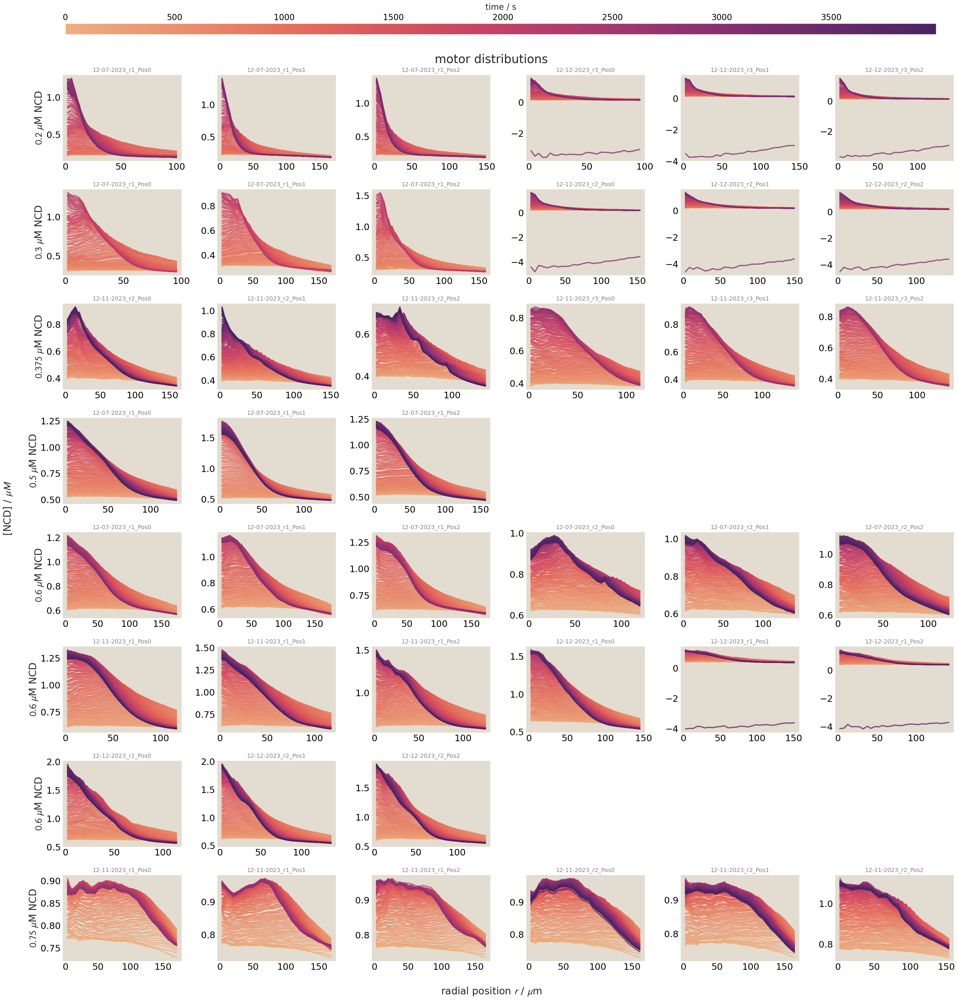

In [29]:
##### MOTORS, flexible axes limits

# define helper function that takes as input an atp time and gives color
global_timeCmap_ATP=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minATPtime, vmax=maxATPtime)(time))
global_timeCmap_Mot=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minMottime, vmax=maxMottime)(time))

### MOTORS
uniqueConcs = np.unique(allProps_verb[:, 1])
nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        figsize=(32, 32))
rowCounter = 0  # Initialize row counter
colCounter = 0  # Initialize column counter
# Iterate over unique concentrations
for ii in range(len(uniqueConcs)):
    c = uniqueConcs[ii]
    # Get indices for this concentration
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    if colCounter==0:
        axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
    # Iterate over indices for this concentration
    for j in range(len(idxsForThisC)):
        # Check if we've exceeded the subplot grid
        if rowCounter >= nrows:
            print("Warning: Not enough subplots to display all data.")
            break  # Exit if no more subplots are available
            
        axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
        # Plot data
        #axs[rowCounter, colCounter].plot(1, 1, 'ro')
        ## get this gname's analyzed data files & parse
        #axs[thisSubplIdx].plot(1,1, 'ro')
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
    
        # this is (numTimes, numRbinMidpoints)
        rMotmids=h5dic['all_rMotbins']*umperpixel
        rMotavgs=h5dic['all_rMotavgs']
        timesMot=h5dic['timesMot']
        for time in range(rMotmids.shape[0]):
            axs[rowCounter, colCounter].plot(rMotmids[time,:],
                                   rMotavgs[time,:], alpha=0.75, 
                                   color=global_timeCmap_Mot(timesMot[time]))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        
        

        
        
        # Move to the next column
        colCounter += 1
        # If we've reached the end of the columns, reset colCounter and increment rowCounter
        if colCounter >= ncols:
            colCounter = 0
            rowCounter += 1

    # After processing this concentration, move to the next row if not already at the start of a new row
    if colCounter != 0:
        colCounter = 0
        rowCounter += 1


# [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# hack for labeling
axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# Iterate through all subplots to hide empty ones
for ax in axs.flat:  # .flat iterates over all subplots in the grid
    if not ax.has_data():  # Check if the subplot has any data
        ax.set_visible(False)  # Hide the entire axis

plt.suptitle('motor distributions')
# Add a common x-label
fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)


######
# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=minMottime, vmax=maxMottime)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time / s', fontsize=20, labelpad=10)

# Adjust layout and display the plot
plt.tight_layout()

#plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_Motors_globalTimeCmap.pdf', 
#            bbox_inches='tight')

<>:77: SyntaxWarning: invalid escape sequence '\m'
<>:79: SyntaxWarning: invalid escape sequence '\m'
<>:77: SyntaxWarning: invalid escape sequence '\m'
<>:79: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2130840/3397594301.py:77: SyntaxWarning: invalid escape sequence '\m'
  fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
/tmp/ipykernel_2130840/3397594301.py:79: SyntaxWarning: invalid escape sequence '\m'
  fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)
/tmp/ipykernel_2130840/3397594301.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


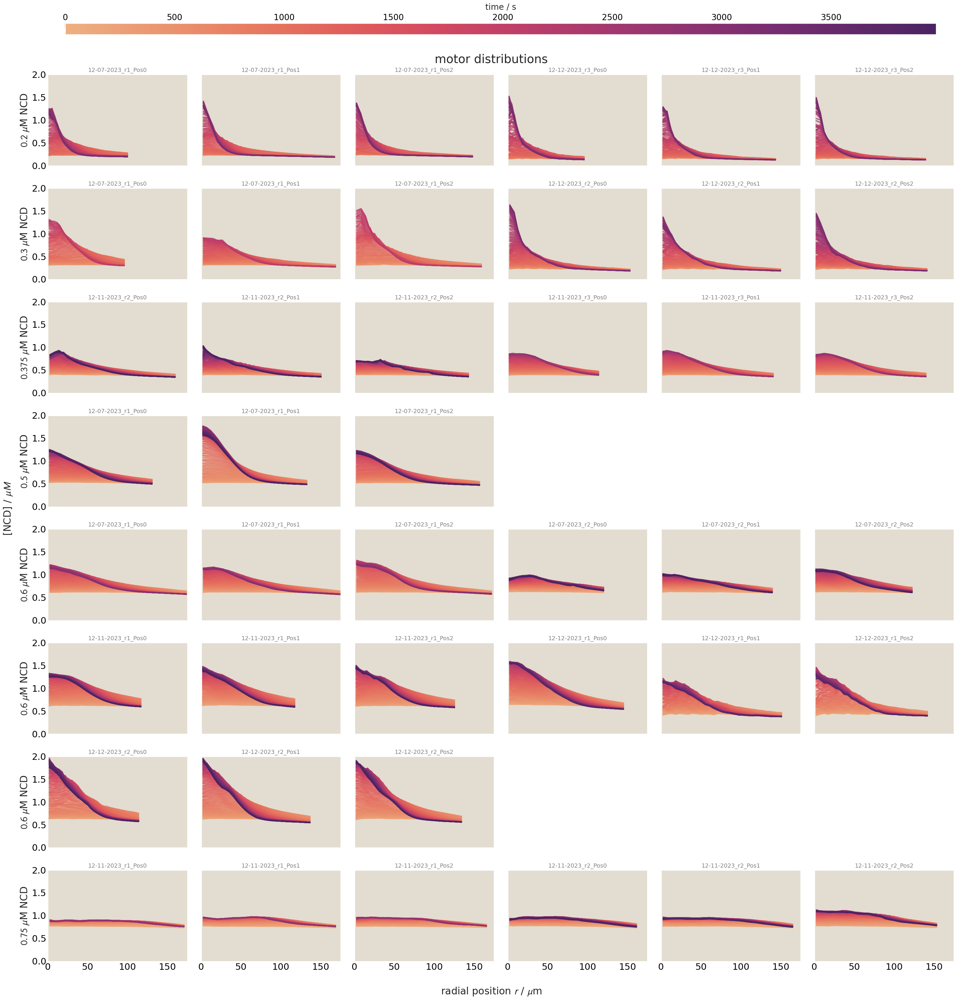

In [30]:
##### MOTORS, flexible axes limits

# define helper function that takes as input an atp time and gives color
global_timeCmap_ATP=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minATPtime, vmax=maxATPtime)(time))
global_timeCmap_Mot=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minMottime, vmax=maxMottime)(time))

### MOTORS
uniqueConcs = np.unique(allProps_verb[:, 1])
nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        figsize=(32, 32),
                       sharex=True, sharey=True)
rowCounter = 0  # Initialize row counter
colCounter = 0  # Initialize column counter
# Iterate over unique concentrations
for ii in range(len(uniqueConcs)):
    c = uniqueConcs[ii]
    # Get indices for this concentration
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    if colCounter==0:
        axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
    # Iterate over indices for this concentration
    for j in range(len(idxsForThisC)):
        # Check if we've exceeded the subplot grid
        if rowCounter >= nrows:
            print("Warning: Not enough subplots to display all data.")
            break  # Exit if no more subplots are available
            
        axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
        # Plot data
        #axs[rowCounter, colCounter].plot(1, 1, 'ro')
        ## get this gname's analyzed data files & parse
        #axs[thisSubplIdx].plot(1,1, 'ro')
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
    
        # this is (numTimes, numRbinMidpoints)
        rMotmids=h5dic['all_rMotbins']*umperpixel
        rMotavgs=h5dic['all_rMotavgs']
        timesMot=h5dic['timesMot']
        for time in range(rMotmids.shape[0]):
            axs[rowCounter, colCounter].plot(rMotmids[time,:],
                                   rMotavgs[time,:], alpha=0.75, 
                                   color=global_timeCmap_Mot(timesMot[time]))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        
        

        
        
        # Move to the next column
        colCounter += 1
        # If we've reached the end of the columns, reset colCounter and increment rowCounter
        if colCounter >= ncols:
            colCounter = 0
            rowCounter += 1

    # After processing this concentration, move to the next row if not already at the start of a new row
    if colCounter != 0:
        colCounter = 0
        rowCounter += 1


# [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# hack for labeling
axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# Iterate through all subplots to hide empty ones
for ax in axs.flat:  # .flat iterates over all subplots in the grid
    if not ax.has_data():  # Check if the subplot has any data
        ax.set_visible(False)  # Hide the entire axis

plt.suptitle('motor distributions')
# Add a common x-label
fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)


######
# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=minMottime, vmax=maxMottime)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time / s', fontsize=20, labelpad=10)

### sensible global axis limits for motor
axs[0,0].set_ylim([-0.01, 2])
axs[0,0].set_xlim([-0.01, 175])

# Adjust layout and display the plot
plt.tight_layout()

# plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_Motors_globalTimeCmap_fixedAxLim.pdf', 
#             bbox_inches='tight')

<>:76: SyntaxWarning: invalid escape sequence '\m'
<>:78: SyntaxWarning: invalid escape sequence '\m'
<>:76: SyntaxWarning: invalid escape sequence '\m'
<>:78: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2130840/1100401531.py:76: SyntaxWarning: invalid escape sequence '\m'
  fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
/tmp/ipykernel_2130840/1100401531.py:78: SyntaxWarning: invalid escape sequence '\m'
  fig.text(-0.01, 0.5, '[ATP] / $\mu M$', ha='center', va='center', rotation=90)
/tmp/ipykernel_2130840/1100401531.py:105: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


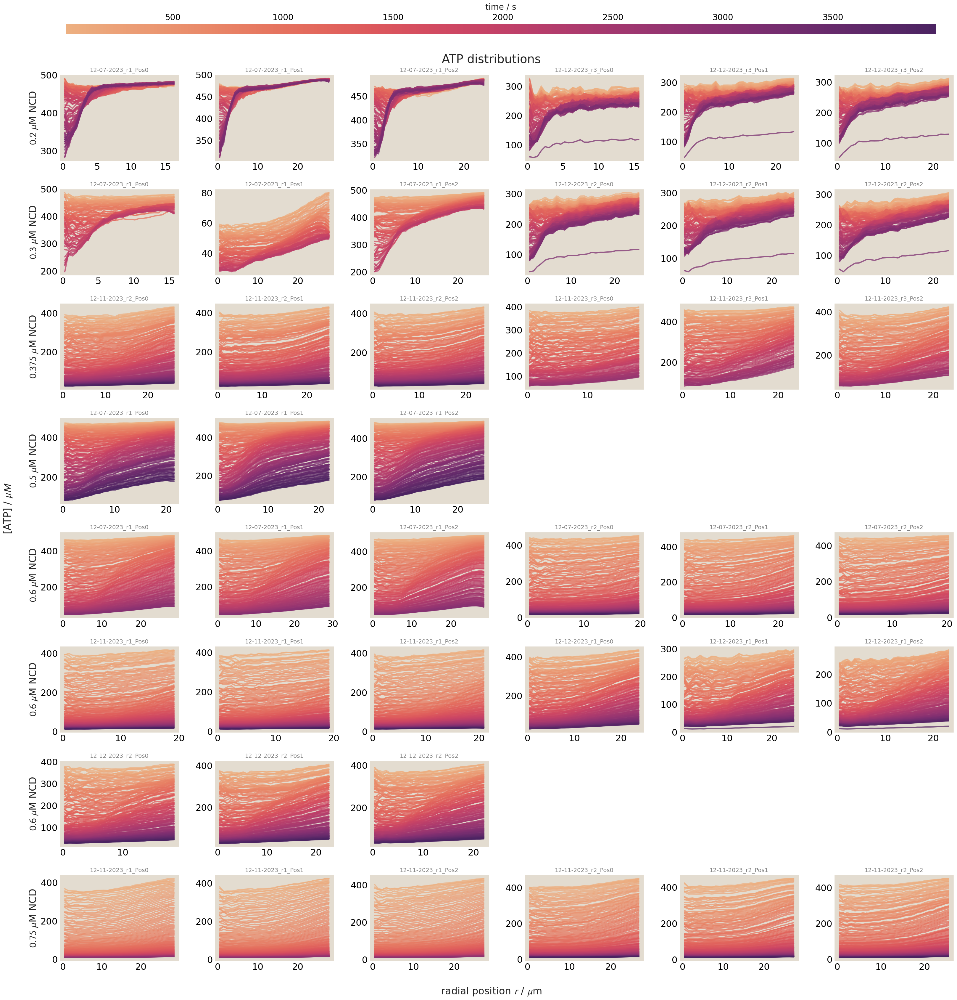

In [31]:
##### ATP, flexible axes limits

# define helper function that takes as input an atp time and gives color
global_timeCmap_ATP=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minATPtime, vmax=maxATPtime)(time))
global_timeCmap_Mot=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minMottime, vmax=maxMottime)(time))

### MOTORS
uniqueConcs = np.unique(allProps_verb[:, 1])
nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        figsize=(32, 32))
rowCounter = 0  # Initialize row counter
colCounter = 0  # Initialize column counter
# Iterate over unique concentrations
for ii in range(len(uniqueConcs)):
    c = uniqueConcs[ii]
    # Get indices for this concentration
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    if colCounter==0:
        axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
    # Iterate over indices for this concentration
    for j in range(len(idxsForThisC)):
        # Check if we've exceeded the subplot grid
        if rowCounter >= nrows:
            print("Warning: Not enough subplots to display all data.")
            break  # Exit if no more subplots are available
            
        axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
        # Plot data
        #axs[rowCounter, colCounter].plot(1, 1, 'ro')
        ## get this gname's analyzed data files & parse
        #axs[thisSubplIdx].plot(1,1, 'ro')
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
    
        # this is (numTimes, numRbinMidpoints)
        rATPmids=h5dic['all_rATPbins']*umperpixel
        rATPavgs=h5dic['all_rATPavgs']
        timesATP=h5dic['timesATP']
        for time in range(rATPmids.shape[0]):
            axs[rowCounter, colCounter].plot(rATPmids[time,:],
                                   rATPavgs[time,:], alpha=0.75, 
                                   color=global_timeCmap_ATP(timesATP[time]))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        
        

        
        
        # Move to the next column
        colCounter += 1
        # If we've reached the end of the columns, reset colCounter and increment rowCounter
        if colCounter >= ncols:
            colCounter = 0
            rowCounter += 1

    # After processing this concentration, move to the next row if not already at the start of a new row
    if colCounter != 0:
        colCounter = 0
        rowCounter += 1


# [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# hack for labeling
axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# Iterate through all subplots to hide empty ones
for ax in axs.flat:  # .flat iterates over all subplots in the grid
    if not ax.has_data():  # Check if the subplot has any data
        ax.set_visible(False)  # Hide the entire axis

plt.suptitle('ATP distributions')
# Add a common x-label
fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, '[ATP] / $\mu M$', ha='center', va='center', rotation=90)


######
# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=minATPtime, 
                                                                 vmax=maxATPtime)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time / s', fontsize=20, labelpad=10)

# GLOBAL ATP axis limits
# axs[0,0].set_ylim([-0.01, 500])
# axs[0,0].set_xlim([-0.01, 27])


# Adjust layout and display the plot
plt.tight_layout()

# plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_ATP_globalTimeCmap.pdf', 
#             bbox_inches='tight')

<>:78: SyntaxWarning: invalid escape sequence '\m'
<>:80: SyntaxWarning: invalid escape sequence '\m'
<>:78: SyntaxWarning: invalid escape sequence '\m'
<>:80: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2130840/1195194917.py:78: SyntaxWarning: invalid escape sequence '\m'
  fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
/tmp/ipykernel_2130840/1195194917.py:80: SyntaxWarning: invalid escape sequence '\m'
  fig.text(-0.01, 0.5, '[ATP] / $\mu M$', ha='center', va='center', rotation=90)
/tmp/ipykernel_2130840/1195194917.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


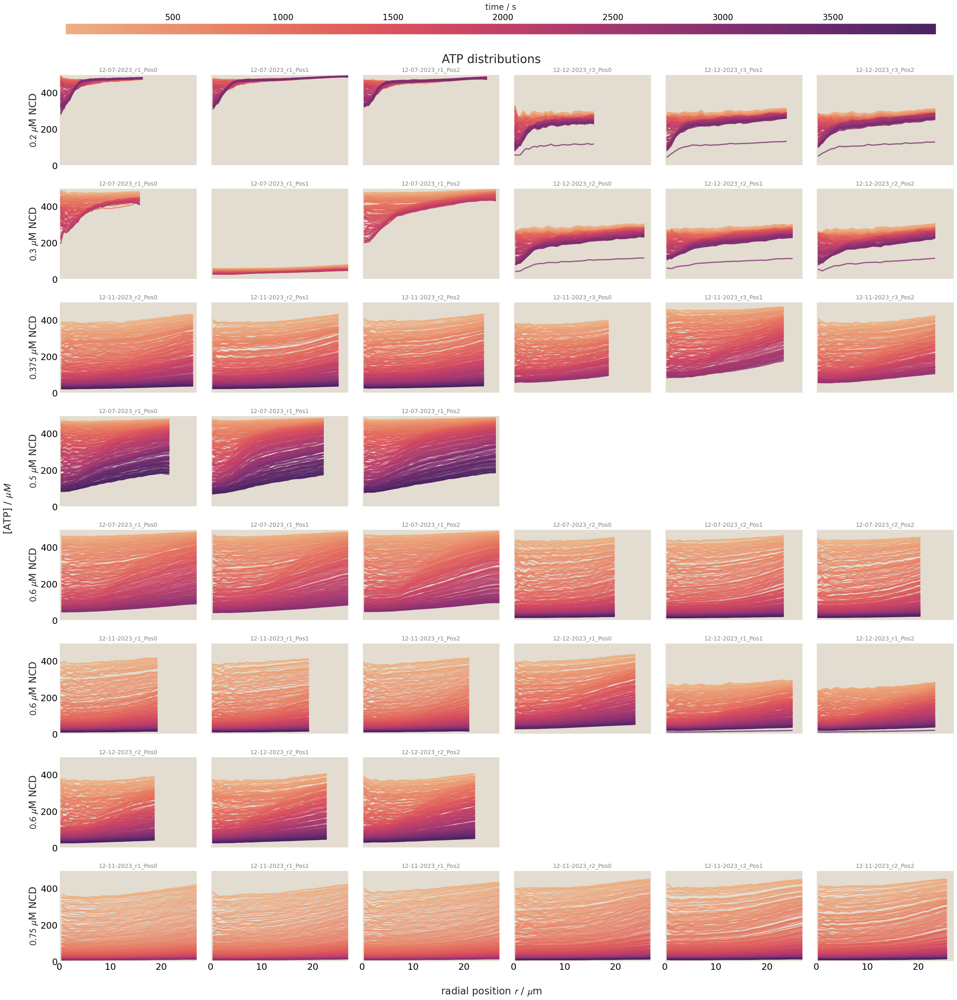

In [32]:
##### ATP, fixed axes limits

# define helper function that takes as input an atp time and gives color
global_timeCmap_ATP=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minATPtime, vmax=maxATPtime)(time))
global_timeCmap_Mot=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minMottime, vmax=maxMottime)(time))

### MOTORS
uniqueConcs = np.unique(allProps_verb[:, 1])
nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        sharex=True,
                        sharey=True,
                        figsize=(32, 32))
rowCounter = 0  # Initialize row counter
colCounter = 0  # Initialize column counter
# Iterate over unique concentrations
for ii in range(len(uniqueConcs)):
    c = uniqueConcs[ii]
    # Get indices for this concentration
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    if colCounter==0:
        axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
    # Iterate over indices for this concentration
    for j in range(len(idxsForThisC)):
        # Check if we've exceeded the subplot grid
        if rowCounter >= nrows:
            print("Warning: Not enough subplots to display all data.")
            break  # Exit if no more subplots are available
            
        axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
        # Plot data
        #axs[rowCounter, colCounter].plot(1, 1, 'ro')
        ## get this gname's analyzed data files & parse
        #axs[thisSubplIdx].plot(1,1, 'ro')
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
    
        # this is (numTimes, numRbinMidpoints)
        rATPmids=h5dic['all_rATPbins']*umperpixel
        rATPavgs=h5dic['all_rATPavgs']
        timesATP=h5dic['timesATP']
        for time in range(rATPmids.shape[0]):
            axs[rowCounter, colCounter].plot(rATPmids[time,:],
                                   rATPavgs[time,:], alpha=0.75, 
                                   color=global_timeCmap_ATP(timesATP[time]))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        
        
        

        
        
        # Move to the next column
        colCounter += 1
        # If we've reached the end of the columns, reset colCounter and increment rowCounter
        if colCounter >= ncols:
            colCounter = 0
            rowCounter += 1

    # After processing this concentration, move to the next row if not already at the start of a new row
    if colCounter != 0:
        colCounter = 0
        rowCounter += 1


# [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# hack for labeling
axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# Iterate through all subplots to hide empty ones
for ax in axs.flat:  # .flat iterates over all subplots in the grid
    if not ax.has_data():  # Check if the subplot has any data
        ax.set_visible(False)  # Hide the entire axis

plt.suptitle('ATP distributions')
# Add a common x-label
fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, '[ATP] / $\mu M$', ha='center', va='center', rotation=90)


######
# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), 
                                          norm=mcolors.Normalize(vmin=minATPtime, 
                                                                 vmax=maxATPtime)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time / s', fontsize=20, labelpad=10)

# GLOBAL ATP axis limits
axs[0,0].set_ylim([-0.01, 500])
axs[0,0].set_xlim([-0.01, 27])


# Adjust layout and display the plot
plt.tight_layout()

#plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_ATP_globalTimeCmap_fixedAxLimits.pdf', 
#            bbox_inches='tight')

### Good asters only

/tmp/ipykernel_2130840/2789712042.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


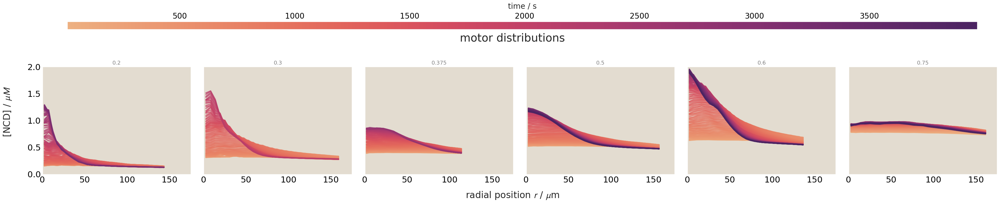

In [33]:
selectAstersAbbv = [['12-12-2023_r3_Pos1', 0.2],
                    ['12-07-2023_r1_Pos2', 0.3],
                    ['12-11-2023_r3_Pos0', 0.375],
                    ['12-07-2023_r1_Pos2', 0.5],
                    ['12-12-2023_r2_Pos1', 0.6],
                    ['12-11-2023_r2_Pos0', 0.75]]
selectAstersIdx = np.squeeze([np.intersect1d(np.where(allProps_verb[:, 0] == abbv[0])[0], np.where(allProps_verb[:, 1].astype(float) == abbv[1])) for abbv in selectAstersAbbv])

nrows, ncols = 1, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        sharex=True,
                        sharey=True,
                        figsize=(36, 6))

for i, idx in enumerate(selectAstersIdx):
    axs[i].set_title(allProps_verb[idx, 1], fontsize=14, color='grey')

    h5spath=gnameList[idx].split('data')[0]+'analyzed_data'+gnameList[idx].split('data')[1]+'/'
    h5dic = read_h5py(h5spath)
    
    # this is (numTimes, numRbinMidpoints)
    rMotmids=h5dic['all_rMotbins']*umperpixel
    rMotavgs=h5dic['all_rMotavgs']
    timesMot=h5dic['timesMot']
    for time in range(rMotmids.shape[0]):
        axs[i].plot(rMotmids[time,:],
                    rMotavgs[time,:], alpha=0.75, 
                    color=global_timeCmap_Mot(timesMot[time])) 

plt.suptitle('motor distributions')
# Add a common x-label
fig.text(0.5, -0.01, r'radial position $r$ / $\mu$m', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, r'[NCD] / $\mu M$', ha='center', va='center', rotation=90)

######
# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.05])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), 
                                          norm=mcolors.Normalize(vmin=minATPtime, 
                                                                 vmax=maxATPtime)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time / s', fontsize=20, labelpad=10)

### sensible global axis limits for motor
axs[0].set_ylim([-0.01, 2])
axs[0].set_xlim([-0.01, 175])

# Adjust layout and display the plot
plt.tight_layout()


/tmp/ipykernel_2130840/3896555406.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


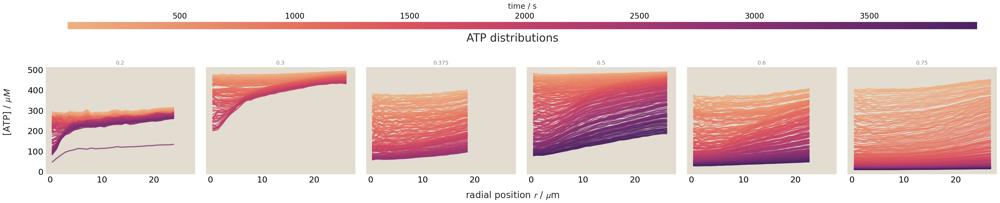

In [34]:
selectAstersAbbv = [['12-12-2023_r3_Pos1', 0.2],
                    ['12-07-2023_r1_Pos2', 0.3],
                    ['12-11-2023_r3_Pos0', 0.375],
                    ['12-07-2023_r1_Pos2', 0.5],
                    ['12-12-2023_r2_Pos1', 0.6],
                    ['12-11-2023_r2_Pos0', 0.75]]
selectAstersIdx = np.squeeze([np.intersect1d(np.where(allProps_verb[:, 0] == abbv[0])[0], np.where(allProps_verb[:, 1].astype(float) == abbv[1])) for abbv in selectAstersAbbv])

nrows, ncols = 1, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        sharex=True,
                        sharey=True,
                        figsize=(36, 6))

for i, idx in enumerate(selectAstersIdx):
    axs[i].set_title(allProps_verb[idx, 1], fontsize=14, color='grey')

    h5spath=gnameList[idx].split('data')[0]+'analyzed_data'+gnameList[idx].split('data')[1]+'/'
    h5dic = read_h5py(h5spath)

    # this is (numTimes, numRbinMidpoints)
    rATPmids=h5dic['all_rATPbins']*umperpixel
    rATPavgs=h5dic['all_rATPavgs']
    timesATP=h5dic['timesATP']
    for time in range(rATPmids.shape[0]):
        axs[i].plot(rATPmids[time,:], rATPavgs[time,:], alpha=0.75, color=global_timeCmap_ATP(timesATP[time]))#sns.color_palette("flare", as_cmap=True)(time/rMotmids.shape[0]), lw=2)        


plt.suptitle('ATP distributions')
# Add a common x-label
fig.text(0.5, -0.01, r'radial position $r$ / $\mu$m', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, r'[ATP] / $\mu M$', ha='center', va='center', rotation=90)


######
# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.05])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), 
                                          norm=mcolors.Normalize(vmin=minATPtime, 
                                                                 vmax=maxATPtime)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time / s', fontsize=20, labelpad=10)

# # GLOBAL ATP axis limits
# axs[0].set_ylim([-0.01, 500])
# axs[0].set_xlim([-0.01, 27])


# Adjust layout and display the plot
plt.tight_layout()


### Resume

In [30]:
# ### ATP - old internal temporal colormap
# uniqueConcs = np.unique(allProps_verb[:, 1])
# nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
# fig, axs = plt.subplots(nrows=nrows, 
#                         ncols=ncols,
#                         figsize=(32, 32))
# rowCounter = 0  # Initialize row counter
# colCounter = 0  # Initialize column counter
# # Iterate over unique concentrations
# for ii in range(len(uniqueConcs)):
#     c = uniqueConcs[ii]
#     # Get indices for this concentration
#     idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
#     if colCounter==0:
#         axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
#     # Iterate over indices for this concentration
#     for j in range(len(idxsForThisC)):
#         # Check if we've exceeded the subplot grid
#         if rowCounter >= nrows:
#             print("Warning: Not enough subplots to display all data.")
#             break  # Exit if no more subplots are available
            
#         axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
#         # Plot data
#         #axs[rowCounter, colCounter].plot(1, 1, 'ro')
#         ## get this gname's analyzed data files & parse
#         #axs[thisSubplIdx].plot(1,1, 'ro')
#         h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
#         h5dic = read_h5py(h5spath)
    
#         # this is (numTimes, numRbinMidpoints)
#         rATPmids=h5dic['all_rATPbins']*umperpixel
#         rATPavgs=h5dic['all_rATPavgs']
#         for time in range(rATPmids.shape[0]):
#             axs[rowCounter, colCounter].plot(rATPmids[time,:],
#                                    rATPavgs[time,:], alpha=0.7+((time%20)==0)*0.2, 
#                                    color=sns.color_palette("flare", as_cmap=True)(time/rATPmids.shape[0]), lw=2)        
        
        

        
        
#         # Move to the next column
#         colCounter += 1
#         # If we've reached the end of the columns, reset colCounter and increment rowCounter
#         if colCounter >= ncols:
#             colCounter = 0
#             rowCounter += 1

#     # After processing this concentration, move to the next row if not already at the start of a new row
#     if colCounter != 0:
#         colCounter = 0
#         rowCounter += 1


# # [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# # hack for labeling
# # axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
# # axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# plt.suptitle('ATP distributions')
# # Add a common x-label
# fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# # Add a common y-label
# fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)


# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241117_initialMultipleAster_smlMltpls_crrctGrid_ATP.pdf', bbox_inches='tight')

In [31]:
# ### ATP fixed axes limits - old internal time colormap
# uniqueConcs = np.unique(allProps_verb[:, 1])
# nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
# fig, axs = plt.subplots(nrows=nrows, 
#                         ncols=ncols,
#                         figsize=(32, 32), sharex=True, sharey=True)
# rowCounter = 0  # Initialize row counter
# colCounter = 0  # Initialize column counter
# # Iterate over unique concentrations
# for ii in range(len(uniqueConcs)):
#     c = uniqueConcs[ii]
#     # Get indices for this concentration
#     idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
#     if colCounter==0:
#         axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
#     # Iterate over indices for this concentration
#     for j in range(len(idxsForThisC)):
#         # Check if we've exceeded the subplot grid
#         if rowCounter >= nrows:
#             print("Warning: Not enough subplots to display all data.")
#             break  # Exit if no more subplots are available
            
#         axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
#         # Plot data
#         #axs[rowCounter, colCounter].plot(1, 1, 'ro')
#         ## get this gname's analyzed data files & parse
#         #axs[thisSubplIdx].plot(1,1, 'ro')
#         h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
#         h5dic = read_h5py(h5spath)
    
#         # this is (numTimes, numRbinMidpoints)
#         rATPmids=h5dic['all_rATPbins']*umperpixel
#         rATPavgs=h5dic['all_rATPavgs']
#         for time in range(rATPmids.shape[0]):
#             axs[rowCounter, colCounter].plot(rATPmids[time,:],
#                                    rATPavgs[time,:], alpha=0.7+((time%20)==0)*0.2, 
#                                    color=sns.color_palette("flare", as_cmap=True)(time/rATPmids.shape[0]), lw=2)        
        
        

        
        
#         # Move to the next column
#         colCounter += 1
#         # If we've reached the end of the columns, reset colCounter and increment rowCounter
#         if colCounter >= ncols:
#             colCounter = 0
#             rowCounter += 1

#     # After processing this concentration, move to the next row if not already at the start of a new row
#     if colCounter != 0:
#         colCounter = 0
#         rowCounter += 1


# # [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# # hack for labeling
# axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
# axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# plt.suptitle('ATP distributions')
# # Add a common x-label
# fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# # Add a common y-label
# fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)

# axs[0,0].set_ylim([-0.01, 500])
# axs[0,0].set_xlim([-0.01, 27])

# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241117_initialMultipleAster_smlMltpls_crrctGrid_ATP_fixedAxesLimits.pdf', bbox_inches='tight')

## Aster radii over time

In [32]:
# ### aster raddii fixed axes limits
# uniqueConcs = np.unique(allProps_verb[:, 1])
# nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
# fig, axs = plt.subplots(nrows=nrows, 
#                         ncols=ncols,
#                         figsize=(32, 32))#, sharex=True, sharey=True)
# rowCounter = 0  # Initialize row counter
# colCounter = 0  # Initialize column counter
# # Iterate over unique concentrations
# for ii in range(len(uniqueConcs)):
#     c = uniqueConcs[ii]
#     # Get indices for this concentration
#     idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
#     if colCounter==0:
#         axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
#     # Iterate over indices for this concentration
#     for j in range(len(idxsForThisC)):
#         # Check if we've exceeded the subplot grid
#         if rowCounter >= nrows:
#             print("Warning: Not enough subplots to display all data.")
#             break  # Exit if no more subplots are available
            
#         axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
#         # Plot data
#         #axs[rowCounter, colCounter].plot(1, 1, 'ro')
#         ## get this gname's analyzed data files & parse
#         #axs[thisSubplIdx].plot(1,1, 'ro')
#         h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
#         h5dic = read_h5py(h5spath)
    
#         # this is (numTimes, numRbinMidpoints)
#         asterRadii=h5dic['radii']*umperpixel
#         times=np.arange(len(asterRadii))*20; #20 seconds interval
        
#         for time in range(len(times)):
#             axs[rowCounter, colCounter].plot(times[time],
#                                    asterRadii[time], 'o', alpha=0.7+((time%20)==0)*0.2, 
#                                    color=sns.color_palette("flare", as_cmap=True)(time/len(times)), lw=2)        
        
        

        
        
#         # Move to the next column
#         colCounter += 1
#         # If we've reached the end of the columns, reset colCounter and increment rowCounter
#         if colCounter >= ncols:
#             colCounter = 0
#             rowCounter += 1

#     # After processing this concentration, move to the next row if not already at the start of a new row
#     if colCounter != 0:
#         colCounter = 0
#         rowCounter += 1


# # [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# # hack for labeling
# axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
# axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# plt.suptitle('ATP distributions')
# # Add a common x-label
# fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# # Add a common y-label
# fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)

# # axs[0,0].set_ylim([-0.01, 500])
# # axs[0,0].set_xlim([-0.01, 27])

# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_asterRadii.pdf', bbox_inches='tight')

In [33]:
# ### aster radii fixed axes limits
# uniqueConcs = np.unique(allProps_verb[:, 1])
# nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
# fig, axs = plt.subplots(nrows=nrows, 
#                         ncols=ncols,
#                         figsize=(32, 32))#, sharex=True, sharey=True)
# rowCounter = 0  # Initialize row counter
# colCounter = 0  # Initialize column counter
# # Iterate over unique concentrations
# for ii in range(len(uniqueConcs)):
#     c = uniqueConcs[ii]
#     # Get indices for this concentration
#     idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
#     if colCounter==0:
#         axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
#     # Iterate over indices for this concentration
#     for j in range(len(idxsForThisC)):
#         # Check if we've exceeded the subplot grid
#         if rowCounter >= nrows:
#             print("Warning: Not enough subplots to display all data.")
#             break  # Exit if no more subplots are available
            
#         axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
#         # Plot data
#         #axs[rowCounter, colCounter].plot(1, 1, 'ro')
#         ## get this gname's analyzed data files & parse
#         #axs[thisSubplIdx].plot(1,1, 'ro')
#         h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
#         h5dic = read_h5py(h5spath)
    
#         # this is (numTimes, numRbinMidpoints)
#         asterRadii=h5dic['radii']*umperpixel
#         times=np.arange(len(asterRadii))*20; #20 seconds interval
        
#         for time in range(len(times)):
#             axs[rowCounter, colCounter].plot(times[time],
#                                    asterRadii[time], 'o', alpha=0.7+((time%20)==0)*0.2, 
#                                    color=sns.color_palette("flare", as_cmap=True)(time/len(times)), lw=2)        
        
        

        
        
#         # Move to the next column
#         colCounter += 1
#         # If we've reached the end of the columns, reset colCounter and increment rowCounter
#         if colCounter >= ncols:
#             colCounter = 0
#             rowCounter += 1

#     # After processing this concentration, move to the next row if not already at the start of a new row
#     if colCounter != 0:
#         colCounter = 0
#         rowCounter += 1


# # [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# # hack for labeling
# axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
# axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# plt.suptitle('ATP distributions')
# # Add a common x-label
# fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# # Add a common y-label
# fig.text(-0.01, 0.5, '[NCD] / $\mu M$', ha='center', va='center', rotation=90)

# # axs[0,0].set_ylim([-0.01, 500])
# # axs[0,0].set_xlim([-0.01, 27])

# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_asterRadii_fixedAxesLimits.pdf', bbox_inches='tight')

### Power versus time!

In [35]:
def float_avg(array, window):
    """ 
    Smooths noisy data by replacing individual values with the average of neighboring values
    
    Params:
    array: array of data to smooth
    window: half the interval (how many points to each side) you want to average over. - note this function does something strange 
    at the end where the last point takes the interval before and averages forgetting the interval after.So if your window is 1, 
    you average over 3 points, i-1, i, i+1. For the last point in the array, you only average two i-1, and i. I don't understand 
    why it isn't throwing an error but I am going with it. Note, I am keeping the first window value of points equal to their original 
    value without averageing. So in this case i=0 stays its original value and we start averaging when i=1
    
    Returns:
    Smoothed array witht he same length as the inputted array
    
    """
    smoo_array = []
    for i in range(len(array)):
        if i<window:
            smoo_array.append(array[i])
        else:
            smoo_array.append(np.average(array[i-window:i+window+1]))
    smoo_array = np.array(smoo_array)
    return smoo_array

Cvat center xml conversion functions

In [36]:
import xml.etree.ElementTree as ET

# Load XML
annotPath = '../../data/aster/2023-12_NCD_Aster_centerInfo/annotations.xml'

def grabxml(annotPath):
    tree = ET.parse(annotPath)  # Replace with actual filename
    root = tree.getroot()
    
    # --- Step 1: Extract task info indexed by task ID ---
    task_data = {}
    for task in root.findall(".//task"):
        task_id = task.find("id").text
        task_data[task_id] = {
            "task_start_frame": int(task.find("start_frame").text),
            "task_stop_frame": int(task.find("stop_frame").text),
            "task_source": task.find("source").text
        }
    
    # --- Step 2: Extract ellipse data inside each track ---
    all_ellipses = []
    
    for track in root.findall("track"):
        track_attrs = track.attrib
        task_id = track_attrs.get("task_id")
        
        # Get task info by task_id
        task_info = task_data.get(task_id, {})
    
        for ellipse in track.findall("ellipse"):
            ellipse_attrs = ellipse.attrib
    
            row = {
                **track_attrs,
                **ellipse_attrs,
                **task_info
            }
    
            all_ellipses.append(row)
    
    # --- Step 3: Convert to DataFrame ---
    annotdf = pd.DataFrame(all_ellipses)
    
    # Optional: convert numeric columns
    for col in ['frame', 'cx', 'cy', 'rx', 'ry', 'z_order', 'task_start_frame', 'task_stop_frame']:
        if col in annotdf.columns:
            annotdf[col] = pd.to_numeric(annotdf[col], errors='coerce')

    return annotdf

# # View result
# print(annotdf.head())


def findmp4NameFromGname(gname):
    date = gname.split('assay_')[1].split('/')[0]
    rep = gname.split('/')[-1].split('_MMStack')[0].split('A81D_')[1]
    pos = gname.split('/')[-1].split('MMStack_')[1].split('.ome')[0]
    if 'uM_Ncd' in gname:
        mot = gname.split('uM_Ncd')[0].split('_')[-1]
    elif 'uM_NCD' in gname:
        mot = gname.split('uM_NCD')[0].split('_')[-1]
    atp = gname.split('ATP')[0].split('_')[-1]
    
    mp4name = date+'_r'+rep+'_'+pos+'_mot'+mot+'_atp'+atp+'.mp4'
    return mp4name


def cvatCentandRad(gname, annotPath, imshape):
    annotdf = grabxml(annotPath)
    source = findmp4NameFromGname(gname)
    annotdf_subset = annotdf[annotdf['task_source']==source]
 
    cvatframes = np.array(annotdf_subset['frame']-annotdf_subset['frame'].max() + annotdf_subset['task_stop_frame'])
    firstkeyframe = cvatframes.min()
    
    firstFramesCenters = np.array([[imshape[1]/2,imshape[0]/2]]*firstkeyframe)
    cvatCenters =  np.array([annotdf_subset['cx'], annotdf_subset['cy']]).T
    centers = np.concat((firstFramesCenters, cvatCenters))
    
    firstFramesLengths = np.array([[np.nan,np.nan]]*firstkeyframe)
    cvatAxesLengths = np.array([annotdf_subset['rx'], annotdf_subset['ry']]).T
    axesLengths = np.concat((firstFramesLengths, cvatAxesLengths))
     
    
    return centers, axesLengths

In [37]:
centers, axesLengths = cvatCentandRad(gnameList[0], 
                                              annotPath, 
                                              imshape = (1200, 1920))

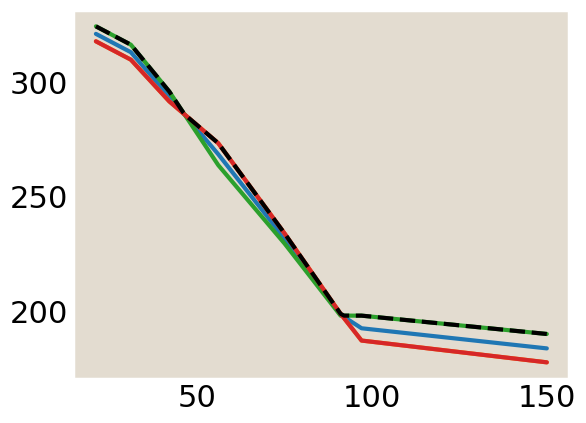

In [38]:
plt.plot(np.arange(len(axesLengths)), np.sqrt(axesLengths[:,0]*axesLengths[:,1]))
plt.plot(axesLengths[:,0])
plt.plot(axesLengths[:,1])
plt.plot(axesLengths[:,0])
plt.plot(np.max(axesLengths, axis=1), color='k', ls='--')

<>:115: SyntaxWarning: invalid escape sequence '\m'
<>:115: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2130840/1406100406.py:115: SyntaxWarning: invalid escape sequence '\m'
  fig.text(-0.01, 0.5, 'aster radius / $\mu$m', ha='center', va='center', rotation=90, color=color_palette()['green'])


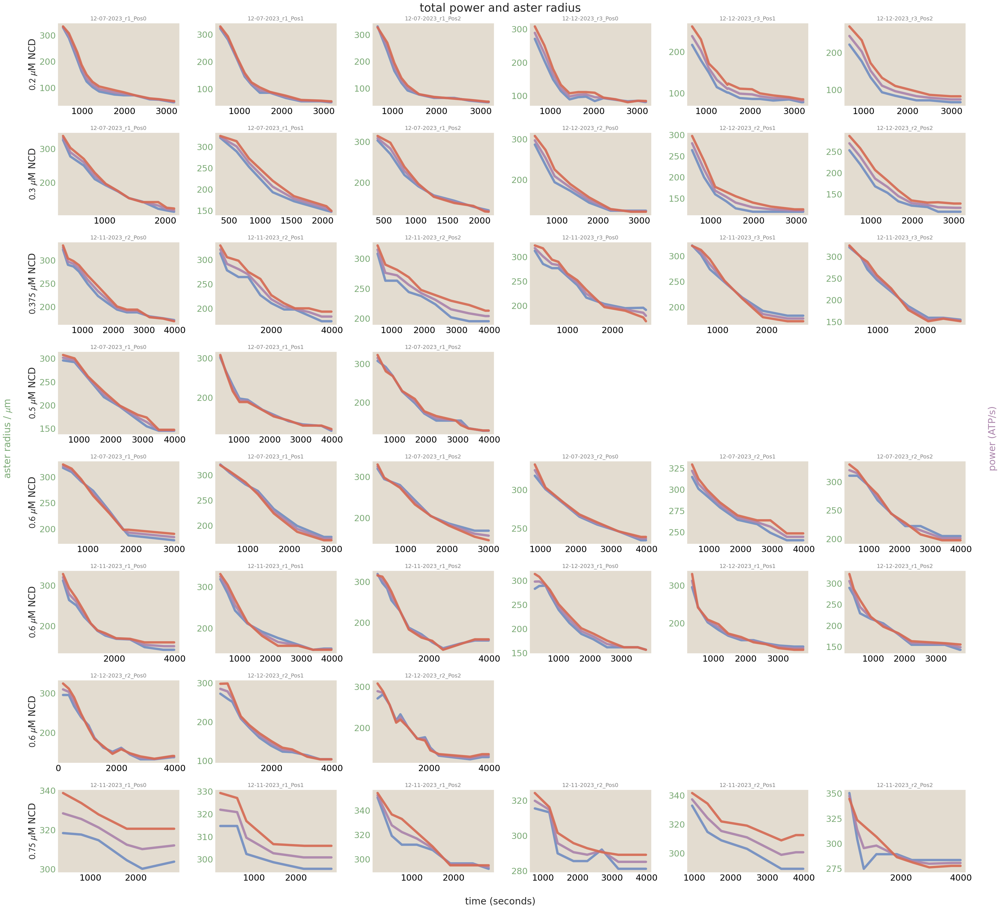

In [69]:
#check how axes lengths change over asters

uniqueConcs = np.unique(allProps_verb[:, 1])
nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        figsize=(34, 32))#, sharex=True, sharey=True)
rowCounter = 0  # Initialize row counter
colCounter = 0  # Initialize column counter
# Iterate over unique concentrations
for ii in range(len(uniqueConcs)):
    c = uniqueConcs[ii]
    # Get indices for this concentration
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    if colCounter==0:
        axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
    # Iterate over indices for this concentration
    for j in range(len(idxsForThisC)):
        # Check if we've exceeded the subplot grid
        if rowCounter >= nrows:
            print("Warning: Not enough subplots to display all data.")
            break  # Exit if no more subplots are available
            
        axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
        # Plot data
        #axs[rowCounter, colCounter].plot(1, 1, 'ro')
        ## get this gname's analyzed data files & parse
        #axs[thisSubplIdx].plot(1,1, 'ro')
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
    
        # # Pre CVAT radii: this is (numTimes, numRbinMidpoints)
        # asterRadii=h5dic['radii']*umperpixel
        # times=np.arange(len(asterRadii))*20; #20 seconds interval

        #cvat radii version
        centers, axesLengths = cvatCentandRad(gnameList[idxsForThisC[j]], 
                                              annotPath, 
                                              imshape = (1200, 1920))
        asterRadii = np.sqrt(axesLengths[:,0]*axesLengths[:,1])
        #times
        times=np.arange(len(asterRadii))*20; #20 seconds interval

        # also import power
        totalPowers=np.sum(h5dic['powerShells'], axis=1)
        smoothwindow=4
        totalPowers=float_avg(totalPowers, smoothwindow)
        times_power=h5dic['timesPower']
        
        # for time in range(len(times)):
        #     axs[rowCounter, colCounter].plot(times[time],
        #                            asterRadii[time], 'o', alpha=0.7+((time%20)==0)*0.2, 
        #                            color=sns.color_palette("flare", as_cmap=True)(time/len(times)), lw=2) 
        #     ## also plot apparent total power
        #     twin=axs[rowCounter, colCounter].twinx()
        #     twin.plot(times[time],
        #                            totalPowers[time], 'o-', alpha=0.7+((time%20)==0)*0.2, 
        #                            color=sns.color_palette("crest", as_cmap=True)(time/len(times)), lw=2)
        
        axs[rowCounter, colCounter].plot(times, axesLengths[:,0], '-', color=color_palette()['blue'], label='ax 0', lw=6, alpha=0.93)
        axs[rowCounter, colCounter].plot(times, asterRadii, '-', color=color_palette()['purple'], label='geo mean', lw=6, alpha=0.93)
        axs[rowCounter, colCounter].plot(times, axesLengths[:,1], '-', color=color_palette()['red'], label='ax 1', lw=6, alpha=0.93)
        yticklabels=axs[rowCounter, colCounter].get_yticklabels()
        for label in yticklabels:
            label.set_color(color_palette()['green']) 
        axs[rowCounter, colCounter].tick_params(axis='y', which='both', length=0)  # Set tick line length to 0

  
        # twin=axs[rowCounter, colCounter].twinx()
        # twin.plot(times_power, totalPowers, '-', color=color_palette()['purple'], label='power', lw=6, alpha=0.93)
        # yticklabels=twin.get_yticklabels()
        # for label in yticklabels:
        #     label.set_color(color_palette()['purple']) 
        #             # Define the formatter function
        # def scientific_notation_formatter(value, tick_number):
        #     return r"${:.1g} \times 10^9$".format(value / 1e9)
        
        # # Apply the formatter to the y-axis
        # twin.yaxis.set_major_formatter(ticker.FuncFormatter(scientific_notation_formatter))

        # # Remove y-axis tick lines while keeping the labels
        # twin.tick_params(axis='y', which='both', length=0)  # Set tick line length to 0


        
        
        # Move to the next column
        colCounter += 1
        # If we've reached the end of the columns, reset colCounter and increment rowCounter
        if colCounter >= ncols:
            colCounter = 0
            rowCounter += 1

    # After processing this concentration, move to the next row if not already at the start of a new row
    if colCounter != 0:
        colCounter = 0
        rowCounter += 1


# [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# hack for labeling
axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# Iterate through all subplots to hide empty ones
for ax in axs.flat:  # .flat iterates over all subplots in the grid
    if not ax.has_data():  # Check if the subplot has any data
        ax.set_visible(False)  # Hide the entire axis

plt.suptitle('total power and aster radius')
# Add a common x-label
fig.text(0.5, -0.01, 'time (seconds)', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, 'aster radius / $\mu$m', ha='center', va='center', rotation=90, color=color_palette()['green'])
fig.text(1+0.01, 0.5, 'power (ATP/s)', ha='center', va='center', rotation=90, color=color_palette()['purple'])


# axs[0,0].set_ylim([-0.01, 500])
# axs[0,0].set_xlim([-0.01, 27])

# Adjust layout and display the plot
plt.tight_layout()

#plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_power_asterRadii_smooth4power.pdf', bbox_inches='tight')

adjust axis and start time after 250s

<>:120: SyntaxWarning: invalid escape sequence '\m'
<>:120: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2130840/1074869246.py:120: SyntaxWarning: invalid escape sequence '\m'
  fig.text(-0.01, 0.5, 'aster radius / $\mu$m', ha='center', va='center', rotation=90, color=color_palette()['green'])


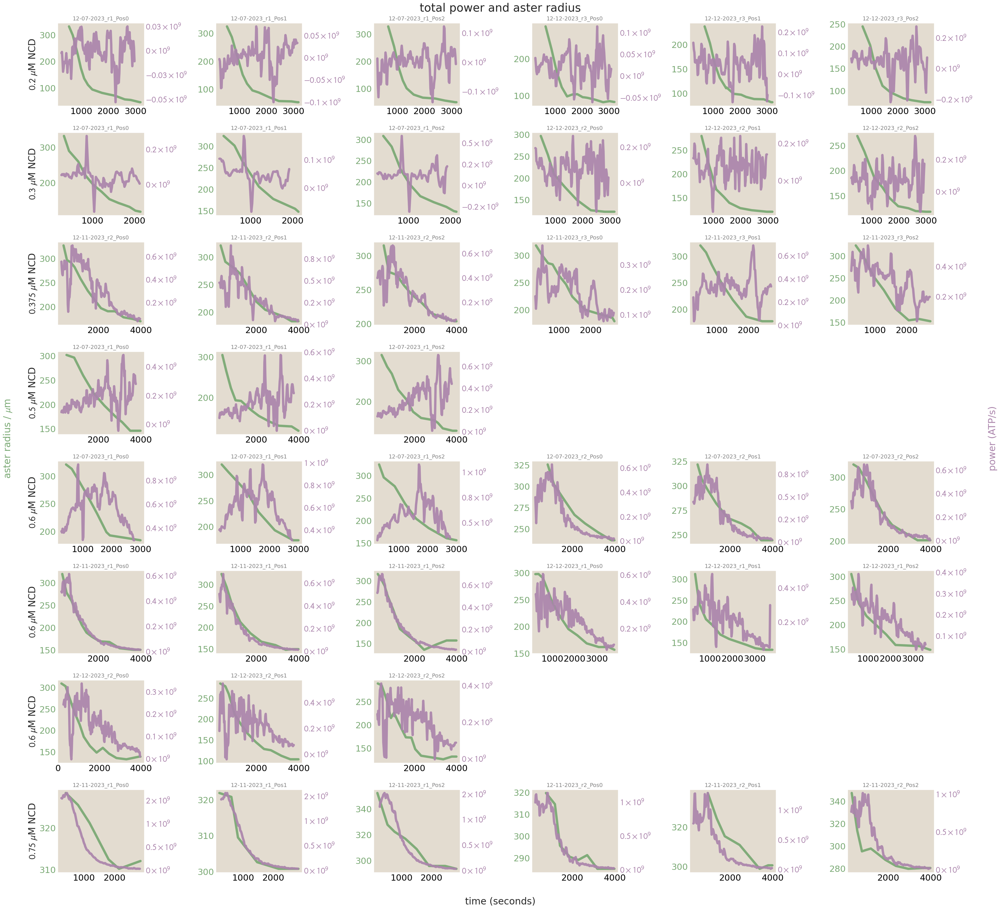

In [130]:
# run this indeed.
### aster raddii flexible axes limits
uniqueConcs = np.unique(allProps_verb[:, 1])
nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        figsize=(34, 32))#, sharex=True, sharey=True)
rowCounter = 0  # Initialize row counter
colCounter = 0  # Initialize column counter
# Iterate over unique concentrations
for ii in range(len(uniqueConcs)):
    c = uniqueConcs[ii]
    # Get indices for this concentration
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    if colCounter==0:
        axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
    # Iterate over indices for this concentration
    for j in range(len(idxsForThisC)):
        # Check if we've exceeded the subplot grid
        if rowCounter >= nrows:
            print("Warning: Not enough subplots to display all data.")
            break  # Exit if no more subplots are available
            
        axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
        # Plot data
        #axs[rowCounter, colCounter].plot(1, 1, 'ro')
        ## get this gname's analyzed data files & parse
        #axs[thisSubplIdx].plot(1,1, 'ro')
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
    
        # # Pre CVAT radii: this is (numTimes, numRbinMidpoints)
        # asterRadii=h5dic['radii']*umperpixel
        # times=np.arange(len(asterRadii))*20; #20 seconds interval

        #cvat radii version
        centers, axesLengths = cvatCentandRad(gnameList[idxsForThisC[j]], 
                                              annotPath, 
                                              imshape = (1200, 1920))
        asterRadii = np.sqrt(axesLengths[:,0]*axesLengths[:,1])
        #times
        times=np.arange(len(asterRadii))*20; #20 seconds interval

        # also import power
        totalPowers=np.sum(h5dic['powerShells'], axis=1)
        smoothwindow=4
        totalPowers=float_avg(totalPowers, smoothwindow)
        times_power=h5dic['timesPower']
        timepowgreater250 = np.where(times_power>=250)[0]

        #cheat to remove anomolously high power at end of movie
        checkspike = totalPowers[-10:]>np.average(totalPowers[:5])
        if np.sum(checkspike)>0 :
            timepowgreater250nospike = timepowgreater250[:-10+np.where(checkspike)[0][0]]
        else:
            timepowgreater250nospike = timepowgreater250
        
        # for time in range(len(times)):
        #     axs[rowCounter, colCounter].plot(times[time],
        #                            asterRadii[time], 'o', alpha=0.7+((time%20)==0)*0.2, 
        #                            color=sns.color_palette("flare", as_cmap=True)(time/len(times)), lw=2) 
        #     ## also plot apparent total power
        #     twin=axs[rowCounter, colCounter].twinx()
        #     twin.plot(times[time],
        #                            totalPowers[time], 'o-', alpha=0.7+((time%20)==0)*0.2, 
        #                            color=sns.color_palette("crest", as_cmap=True)(time/len(times)), lw=2)
        
        axs[rowCounter, colCounter].plot(times, asterRadii, '-', color=color_palette()['green'], label='radius', lw=6, alpha=0.93)
        yticklabels=axs[rowCounter, colCounter].get_yticklabels()
        for label in yticklabels:
            label.set_color(color_palette()['green']) 
        axs[rowCounter, colCounter].tick_params(axis='y', which='both', length=0)  # Set tick line length to 0

        twin=axs[rowCounter, colCounter].twinx()
        twin.plot(times_power[timepowgreater250nospike], totalPowers[timepowgreater250nospike], '-', color=color_palette()['purple'], label='power', lw=6, alpha=0.93)
        yticklabels=twin.get_yticklabels()
        for label in yticklabels:
            label.set_color(color_palette()['purple']) 
                    # Define the formatter function
        def scientific_notation_formatter(value, tick_number):
            return r"${:.1g} \times 10^9$".format(value / 1e9)
        
        # Apply the formatter to the y-axis
        twin.yaxis.set_major_formatter(ticker.FuncFormatter(scientific_notation_formatter))

        # Remove y-axis tick lines while keeping the labels
        twin.tick_params(axis='y', which='both', length=0)  # Set tick line length to 0


        
        
        # Move to the next column
        colCounter += 1
        # If we've reached the end of the columns, reset colCounter and increment rowCounter
        if colCounter >= ncols:
            colCounter = 0
            rowCounter += 1

    # After processing this concentration, move to the next row if not already at the start of a new row
    if colCounter != 0:
        colCounter = 0
        rowCounter += 1


# [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# hack for labeling
axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# Iterate through all subplots to hide empty ones
for ax in axs.flat:  # .flat iterates over all subplots in the grid
    if not ax.has_data():  # Check if the subplot has any data
        ax.set_visible(False)  # Hide the entire axis

plt.suptitle('total power and aster radius')
# Add a common x-label
fig.text(0.5, -0.01, 'time (seconds)', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, 'aster radius / $\mu$m', ha='center', va='center', rotation=90, color=color_palette()['green'])
fig.text(1+0.01, 0.5, 'power (ATP/s)', ha='center', va='center', rotation=90, color=color_palette()['purple'])


# axs[0,0].set_ylim([-0.01, 500])
# axs[0,0].set_xlim([-0.01, 27])

# Adjust layout and display the plot
plt.tight_layout()

#plt.savefig('20250604_initialMultipleAster_smlMltpls_crrctGrid_power_smooth4power_fixedAxLimits_wPhotoCvat.pdf', bbox_inches='tight')
#plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_power_asterRadii_smooth4power.pdf', bbox_inches='tight')

In [128]:
checkspike = totalPowers[-10:]>np.average(totalPowers[:5])
int(-10+np.where(checkspike)[0][0])

-10

In [111]:
checkspike = totalPowers[-10:]>np.average(totalPowers[:5])
if np.sum(checkspike)>0 :
    timepowgreater250nospike = timepowgreater250[:-10+np.where(checkspike)[0]]
else:
    timepowgreater250nospike = timepowgreater250

b


<>:118: SyntaxWarning: invalid escape sequence '\m'
<>:118: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2130840/735117009.py:118: SyntaxWarning: invalid escape sequence '\m'
  fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
/tmp/ipykernel_2130840/735117009.py:139: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_2130840/735117009.py:153: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


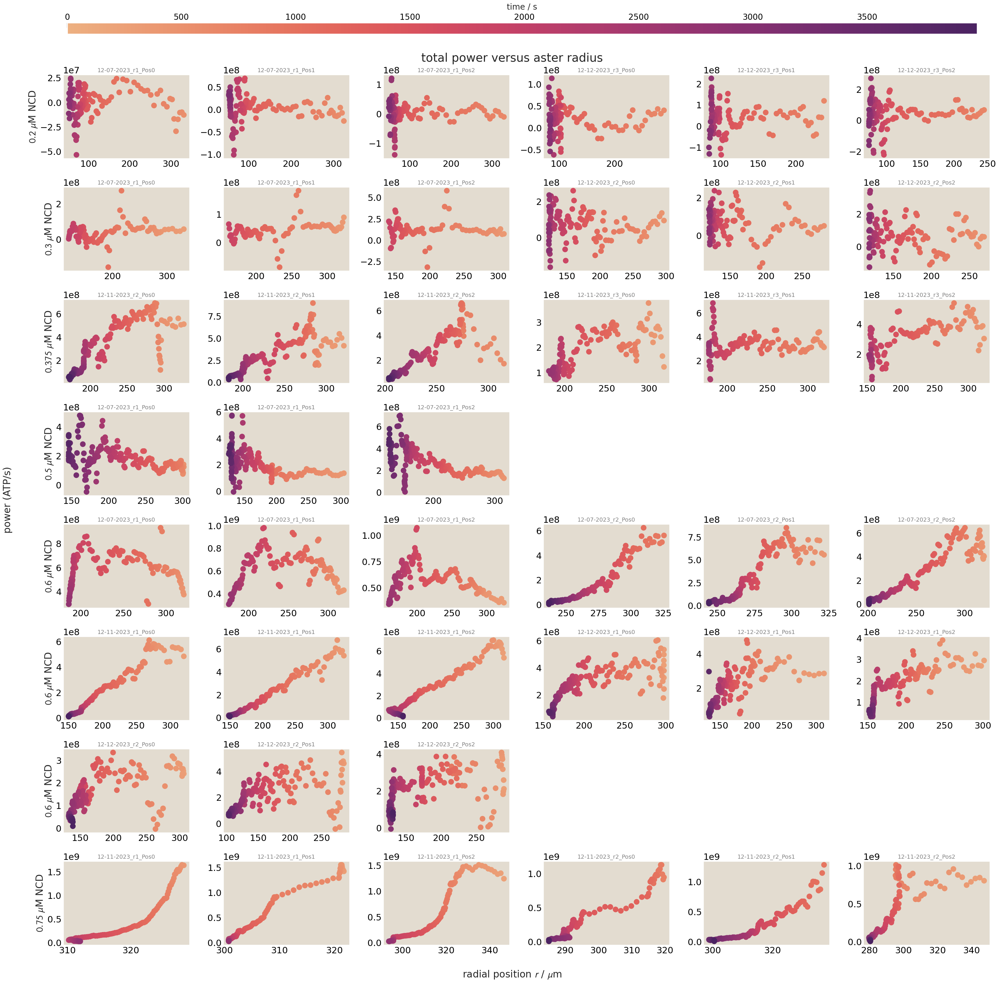

In [131]:
### aster radii FIXED axes limits
# # need to be trickier/more careful here since twinx complicates setting global limits for each twinx separately
# axesForAsterRadii=[]; #preallocate
# axesForPower=[]


global_timeCmap_pow=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minpowtime, vmax=maxpowtime)(time))

uniqueConcs = np.unique(allProps_verb[:, 1])
nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        figsize=(34, 32))#, sharex=True, sharey=True)
rowCounter = 0  # Initialize row counter
colCounter = 0  # Initialize column counter
# Iterate over unique concentrations
for ii in range(len(uniqueConcs)):
    c = uniqueConcs[ii]
    # Get indices for this concentration
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    if colCounter==0:
        axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
    # Iterate over indices for this concentration
    for j in range(len(idxsForThisC)):
        # Check if we've exceeded the subplot grid
        if rowCounter >= nrows:
            print("Warning: Not enough subplots to display all data.")
            break  # Exit if no more subplots are available
            
        axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
        # Plot data
        #axs[rowCounter, colCounter].plot(1, 1, 'ro')
        ## get this gname's analyzed data files & parse
        #axs[thisSubplIdx].plot(1,1, 'ro')
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
    
        # # this is (numTimes, numRbinMidpoints)
        # asterRadii=h5dic['radii']*umperpixel
        # times=np.arange(len(asterRadii))*20; #20 seconds interval

        #cvat radii version
        centers, axesLengths = cvatCentandRad(gnameList[idxsForThisC[j]], 
                                              annotPath, 
                                              imshape = (1200, 1920))
        asterRadii = np.sqrt(axesLengths[:,0]*axesLengths[:,1])
        #times
        times=np.arange(len(asterRadii))*20; #20 seconds interval
        
        # also import power
        totalPowers=np.sum(h5dic['powerShells'], axis=1)
        smoothwindow=4
        totalPowers=float_avg(totalPowers, smoothwindow)
        times_power=h5dic['timesPower']
        timepowgreater250 = np.where(times_power>=250)[0]

        #cheat to remove anomolously high power at end of movie
        checkspike = totalPowers[-10:]>np.average(totalPowers[:5])
        if np.sum(checkspike)>0 :
            timepowgreater250nospike = timepowgreater250[:-10+np.where(checkspike)[0][0]]
        else:
            timepowgreater250nospike = timepowgreater250
    
        # for time in range(len(times)):
        #     axs[rowCounter, colCounter].plot(times[time],
        #                            asterRadii[time], 'o', alpha=0.7+((time%20)==0)*0.2, 
        #                            color=sns.color_palette("flare", as_cmap=True)(time/len(times)), lw=2) 
        #     ## also plot apparent total power
        #     twin=axs[rowCounter, colCounter].twinx()
        #     twin.plot(times[time],
        #                            totalPowers[time], 'o-', alpha=0.7+((time%20)==0)*0.2, 
        #                            color=sns.color_palette("crest", as_cmap=True)(time/len(times)), lw=2)
        
        axs[rowCounter, colCounter].scatter(asterRadii[1:-1][timepowgreater250nospike], 
                                            totalPowers[timepowgreater250nospike], 
                                            c = [global_timeCmap_pow(time) for time in times_power[timepowgreater250nospike]])#, '-', color=color_palette()['green'], label='radius', alpha=0.88)
        axesForAsterRadii.append(axs[rowCounter, colCounter]) #for later setting global axes limits

        ### If you want y axis in scientific notation - currently weird rounding stuff happens ###
        # def scientific_notation_formatter(value, tick_number):
        #     return r"${:.1g} \times 10^9$".format(value / 1e9)
        
        # # Apply the formatter to the y-axis
        # axs[rowCounter, colCounter].yaxis.set_major_formatter(ticker.FuncFormatter(scientific_notation_formatter))

        # # Remove y-axis tick lines while keeping the labels
        # axs[rowCounter, colCounter].tick_params(axis='y', which='both', length=0)  # Set tick line length to 0


        
        
        # Move to the next column
        colCounter += 1
        # If we've reached the end of the columns, reset colCounter and increment rowCounter
        if colCounter >= ncols:
            colCounter = 0
            rowCounter += 1

    # After processing this concentration, move to the next row if not already at the start of a new row
    if colCounter != 0:
        colCounter = 0
        rowCounter += 1


# [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# hack for labeling
axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# Iterate through all subplots to hide empty ones
for ax in axs.flat:  # .flat iterates over all subplots in the grid
    if not ax.has_data():  # Check if the subplot has any data
        ax.set_visible(False)  # Hide the entire axis

plt.suptitle('total power versus aster radius')
# Add a common x-label
fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, 'power (ATP/s)', ha='center', va='center', rotation=90)

# Adjust the top margin to make space for the colorbar
fig.subplots_adjust(top=0.85)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=minMottime, vmax=maxMottime)),
                    cax=cax, orientation='horizontal')
cbar.ax.tick_params(labelsize=20)

# Move colorbar label and ticks to the top
cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
cbar.ax.xaxis.set_label_position('top')   # Move label to top
cbar.set_label('time / s', fontsize=20, labelpad=10)

# Adjust layout and display the plot
plt.tight_layout()


# ### ### ### 
# #global_asterRadiusYlim=[75,350] #NOTE truncates max of weird experiments (that reach up to 600um? in radius) a bit. #green left aster radius 
# global_powerYlim=[-1e8, 1e9] # purple
# #global_radialPositionXlim=[-200, 4000]

# #[ax.set_ylim(global_asterRadiusYlim) for ax in axesForAsterRadii]
# [ax.set_ylim(global_powerYlim) for ax in axesForPower]
# #[ax.set_xlim(global_radialPositionXlim) for ax in axesForAsterRadii+axesForPower]


# Adjust layout and display the plot
plt.tight_layout()

plt.savefig('20250924_initialMultipleAster_smlMltpls_totPowVSradius_smooth4power_250sStart.pdf', 
            bbox_inches='tight')

In [41]:
np.where(h5dic['timesPower']>=250)[0][0]

np.int64(12)

(-100000000.0, 2000000000.0)

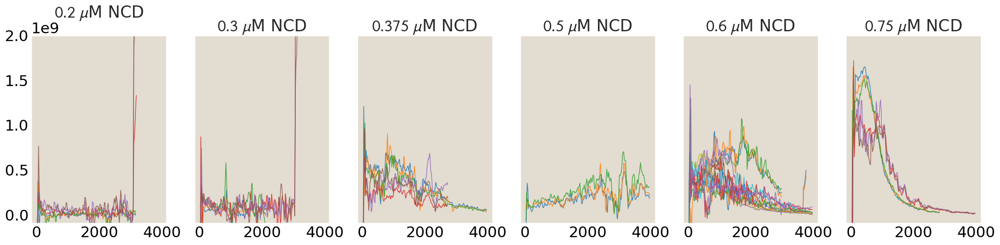

In [42]:
uniqueConcs = np.unique(allProps_verb[:, 1])
fig, ax = plt.subplots(1, len(uniqueConcs), figsize=(25, 5), sharey=True, sharex=True)
for ii, c in enumerate(uniqueConcs):
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    ax[ii].set_title(r'$' + str(c) + r'\ \mu$M NCD')
    for j in range(len(idxsForThisC)):
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
        
        # also import power
        totalPowers=np.sum(h5dic['powerShells'], axis=1)
        smoothwindow=4
        totalPowers=float_avg(totalPowers, smoothwindow)
        times_power=h5dic['timesPower']
        ax[ii].plot(times_power, totalPowers, '-', label='power', lw=1, alpha=0.88) 
ax[0].set_ylim(-1e8, 2e9)

<>:47: SyntaxWarning: invalid escape sequence '\c'
<>:47: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_1780813/2740775368.py:47: SyntaxWarning: invalid escape sequence '\c'
  ax[0][0].set_ylabel(f'power / $10^9$ ATP $\cdot$ s$^{-1}$', fontsize=25)


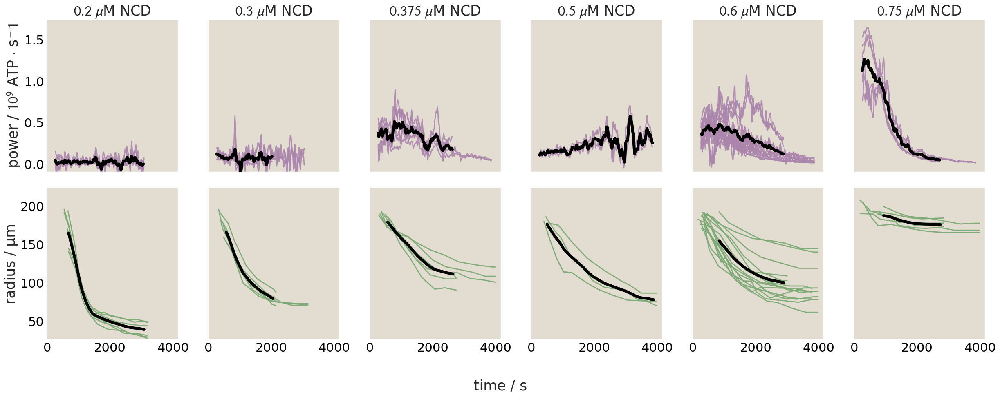

In [43]:
uniqueConcs = np.unique(allProps_verb[:, 1])
fig, ax = plt.subplots(2, len(uniqueConcs), figsize=(25, 10), sharex=True, sharey='row')
for ii, c in enumerate(uniqueConcs):
    powatThisC = []
    radatThisC = []
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    ax[0][ii].set_title(r'$' + str(c) + r'\ \mu$M NCD', fontsize=25)
    for j in range(len(idxsForThisC)):
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
        
        #### plot power ####
        totalPowers=np.sum(h5dic['powerShells'], axis=1)
        smoothwindow=4
        totalPowers=float_avg(totalPowers, smoothwindow)
        powatThisC.append(totalPowers)
        times_power=h5dic['timesPower']
        #impose early time cutoff
        cutoff=np.where(h5dic['timesPower']>=250)[0][0]
        ax[0][ii].plot(times_power[cutoff:-5], totalPowers[cutoff:-5]/1e9, '-', label='power', lw=2, alpha=0.88, color=color_palette()['purple']) #impose cutoff at 250s
        #ax[0][ii].set_ylim(0, ax[0][ii].get_ylim()[-1])
           
        #### Plot Aster size ####
        centers, axesLengths = cvatCentandRad(gnameList[idxsForThisC[j]], 
                                              annotPath, 
                                              imshape = (1200, 1920))
        asterRadii = np.sqrt(axesLengths[:,0]*axesLengths[:,1])*umperpixel
        radatThisC.append(asterRadii)
        #radiitimes
        times=np.arange(len(asterRadii))*20; #20 seconds interval
        ax[1][ii].plot(times, asterRadii, '-', color=color_palette()['green'], label='radius', lw=2, alpha=0.93)
        #ax[1][ii].set_ylim(50,350)

    minLen = len(min(powatThisC, key=len)) # some of the power arrays are different lengths find the min
    powatThisC = np.array([a[:minLen] for a in powatThisC])
    ax[0][ii].plot(times_power[:minLen][cutoff:-5], np.average(powatThisC, axis=0)[cutoff:-5]/1e9, '-',  lw=5, color='k',zorder=100)

    minLen = len(min(radatThisC, key=len)) # some of the power arrays are different lengths find the min
    radatThisC = np.array([a[:minLen] for a in radatThisC])
    ax[1][ii].plot(times[:minLen][cutoff:-5], np.average(radatThisC, axis=0)[cutoff:-5], '-', lw=5, color='k', zorder=100)

#ax[0][ii].set_ylim(-1e8, 2e9)
ax[0][ii].set_ylim(-0.1, 1.75)
# ax[0][0].set_yscale('log')
ax[1][0].set_ylim(25,225)

ax[0][0].set_ylabel(f'power / $10^9$ ATP $\cdot$ s$^{-1}$', fontsize=25)
ax[1][0].set_ylabel(r'radius / µm', fontsize=25)
fig.supxlabel(r'time / s', fontsize=25)
plt.tight_layout()
# plt.savefig('20250629_powAndradMotSweep.pdf', 
#             bbox_inches='tight')

In [44]:
4000/20

200.0

# 20250608 Plots for single aster

Pick a good aster

In [47]:
gname_pc = '../../data/aster/Ncd_Aster_assay_12-11-2023/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif'
h5spath_pc=gname_pc.split('data')[0]+'analyzed_data'+gname_pc.split('data')[1]+'/'
h5dic_pc = read_h5py(h5spath_pc)

ATP_conc_ims_pc = makeImFromValsList(h5dic_pc['ATP'], h5dic_pc['mask_coords'], h5dic_pc['imshape'])
mot_conc_ims_pc = makeImFromValsList(h5dic_pc['mot'], h5dic_pc['mask_coords'], h5dic_pc['imshape'])
mango_mask_pc = makeImFromValsList(np.ones((len(h5dic_pc['mot']), len(h5dic_pc['mask_coords'][0]))), h5dic_pc['mask_coords'], h5dic_pc['imshape'])[0].astype('int')

centers_pc, axesLengths_pc = cvatCentandRad(gname_pc, annotPath, ATP_conc_ims_pc[0].shape)
min_dist_pc = min_radius(mango_mask_pc, centers_pc)


NameError: name 'min_radius' is not defined

In [48]:
h5dic_pc.keys()

dict_keys(['ATPShells', 'timesMot', 'ATP_shell_vol_L', 'timesATP', 'imshape', 'Mot_shell_vol_L', 'ATP_centCrop', 'MotShells', 'timesPower', 'mot_centCrop', 'all_rMotavgs', 'ATP', 'all_rMotbins', 'mask_coords', 'powerShells', 'mot', 'all_rATPbins', 'all_rATPavgs'])

In [49]:
#define the time  of each frame
times_sec = np.arange(len(mot_conc_ims_cropped))*exp_params['interval']
times_min = times_sec/60

#square inscribed in circle
side_length = int(min_dist/np.sqrt(2))
inscribe_crop_all = np.s_[:, round(min_dist)-side_length:round(min_dist)+side_length,
                     round(min_dist)-side_length:round(min_dist)+side_length]


NameError: name 'mot_conc_ims_cropped' is not defined

Movies

In [ ]:
def spaceTimeAvg(imgArray, numTimesWindow, spatialBlock, mode='valid', clip=True):
    """ Also try mode='valid' if you want to only compute time points where the window fits """
    # first, take time running average
    window = np.ones(numTimesWindow) / numTimesWindow
    # 0 refers to first axis (assumed to be time, if imgArray = numTimes x height x width)
    timeAvgd= np.apply_along_axis(lambda m: np.convolve(m, window, mode=mode), 0, imgArray)
    
    # next, do space average
    spaceTimeAvgd=np.zeros((timeAvgd.shape[0], timeAvgd.shape[1]//spatialBlock[0], timeAvgd.shape[1]//spatialBlock[0]))
    for t in range(timeAvgd.shape[0]):
        spaceTimeAvgd[t,:,:]=skimage.measure.block_reduce(timeAvgd[t,:,:],block_size=spatialBlock, func=np.mean)
    
    ## optionally, clip to 99th percentile
    if clip:
        percentile=99.99
        for t in range(spaceTimeAvgd.shape[0]):
            cutOff=np.percentile(spaceTimeAvgd[t,:,:].flatten(), percentile)
            spaceTimeAvgd[t,:,:]=np.where(spaceTimeAvgd[t,:,:]>cutOff, np.nan, spaceTimeAvgd[t,:,:])
    
    return spaceTimeAvgd

def justTimeAvg(imgArray, numTimesWindow, mode='valid'):
    """ Also try mode='valid' if you want to only compute time points where the window fits """
    # first, take time running average
    window = np.ones(numTimesWindow) / numTimesWindow
    # 0 refers to first axis (assumed to be time, if imgArray = numTimes x height x width)
    timeAvgd= np.apply_along_axis(lambda m: np.convolve(m, window, mode=mode), 0, imgArray)
    
#     # next, do space average
#     spaceTimeAvgd=np.zeros((timeAvgd.shape[0], timeAvgd.shape[1]//spatialBlock[0], timeAvgd.shape[1]//spatialBlock[0]))
#     for t in range(timeAvgd.shape[0]):
#         spaceTimeAvgd[t,:,:]=skimage.measure.block_reduce(timeAvgd[t,:,:],block_size=spatialBlock, func=np.mean)
    
#     ## optionally, clip to 99th percentile
#     if clip:
#         percentile=99.99
#         for t in range(spaceTimeAvgd.shape[0]):
#             cutOff=np.percentile(spaceTimeAvgd[t,:,:].flatten(), percentile)
#             spaceTimeAvgd[t,:,:]=np.where(spaceTimeAvgd[t,:,:]>cutOff, np.nan, spaceTimeAvgd[t,:,:])
    
    return timeAvgd

In [ ]:
# ATP Downsampling in space AND time
ds_sptm_ATP=spaceTimeAvg(ATP_conc_ims_cropped[inscribe_crop_all], numTimesWindow=2, spatialBlock=(6,6), clip=False)
# motor downsample in time only
ds_tm_mot=justTimeAvg(mot_conc_ims_cropped[inscribe_crop_all], numTimesWindow=2)

Motor Movie

In [ ]:
ims = []
side_length = int(min_dist/np.sqrt(2))
inscribe_crop = np.s_[round(min_dist)-side_length:round(min_dist)+side_length,
                     round(min_dist)-side_length:round(min_dist)+side_length]
plot_array = mot_conc_ims_cropped[inscribe_crop_all]#ds_sptm_mot
plot_times = times_min #min
winsize_um = side_length*um_per_pixel
cmap = sns.color_palette('mako', as_cmap=True)#cm.get_cmap('binary_r')
colorbar_min = np.percentile(plot_array, 0)
colorbar_max = np.percentile(plot_array, 99.9)
normalizer = Normalize(colorbar_min, colorbar_max)
cb_setting = cm.ScalarMappable(norm=normalizer, cmap=cmap)
extent = [-winsize_um, winsize_um, -winsize_um, winsize_um]

fig, ax = plt.subplots(figsize = (5,4))

#ax.set_title("NCD Kinesin Motors")

camera = cell.Camera(fig)

for i, time in enumerate(tqdm(plot_times)):
    im_temp = plot_array[i]
    im = ax.imshow(im_temp,
                   vmin=colorbar_min,
                   vmax=colorbar_max,
                   cmap = cmap,
                   animated=True,
                   extent=extent,
                   zorder=0)
    # ax.text(-105, 100, str(round(time, 2)), color = 'w')
    # ax.text(-80, 100, " min", color = 'w')
    ax.text(32, 60, str(round(time, 2)), color = 'k')
    ax.text(47, 60, " min", color = 'k')
    ax.text(55,-65, " µm", color = 'k')
    camera.snap()
cbar = plt.colorbar(cb_setting, label = "NCD Concentration (µM)")#, ticks = cbar_range)
cbar.ax.tick_params(pad=1)
# plt.xlabel('µm')
# plt.ylabel('µm')
    
animation = camera.animate()
save_path ='../../analyzed_data/aster/2023-12-12_NCD_Aster/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2/'
#animation.save(save_path+"20240911_motor_movie.mp4",dpi=400, fps=20)

ATP Movie

In [ ]:
ims = []

side_length = int(min_dist/np.sqrt(2))
inscribe_crop = np.s_[round(min_dist)-side_length:round(min_dist)+side_length,
                     round(min_dist)-side_length:round(min_dist)+side_length]
plot_array = ds_sptm_ATP
plot_times = (times_sec[1:] - exp_params['interval']/2)/60 #min
winsize_um = side_length*um_per_pixel
extent = [-winsize_um, winsize_um, -winsize_um, winsize_um]


cmap = sns.color_palette('mako', as_cmap=True)
colorbar_min = np.percentile(plot_array, 0)
colorbar_max = np.percentile(plot_array, 98)
#cbar_range = [np.percentile(ratios_plot[40], 9), np.percentile(ratios_plot[40], 36), np.percentile(ratios_plot[40],63), np.percentile(ratios_plot[40], 90)]
#cbar_range_ATP = ATP_inten_to_conc(np.array(cbar_range), 742,  1.49,   0.78,   2.02)
# cbar_range_ATPint = []
# for i, val in enumerate(cbar_range_ATP):
#     cbar_range_ATPint.append(int(val))

normalizer = Normalize(colorbar_min, colorbar_max)
cb_setting = cm.ScalarMappable(norm=normalizer, cmap=cmap)
fig, ax = plt.subplots(figsize=(5,4))

#ax.set_title("ATP")

camera = cell.Camera(fig)

for i, time in enumerate(tqdm(plot_times)):
    im_temp = plot_array[i]
    im = ax.imshow(im_temp,
                   vmin=colorbar_min,
                   vmax=colorbar_max,
                   cmap = cmap,
                   animated=True,
                   extent = extent,
                   zorder=0)
    ax.text(32, 60, str(round(time, 2)), color = 'k')
    ax.text(47, 60, " min", color = 'k')
    ax.text(55,-65, " µm", color = 'k')
    camera.snap()
cbar = plt.colorbar(cb_setting, label = "ATP Concentration (µM)")#, ticks = cbar_range)

#cbar.ax.set_yticklabels([colorbar_min, colorbar_max]) 
cbar.ax.tick_params(pad=1)
#cbar.ax.set_yticklabels(cbar_range_ATPint)
#plt.xlabel('µm')
#plt.ylabel('µm')
    
animation = camera.animate()
save_path ='../../analyzed_data/aster/2023-12-12_NCD_Aster/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2/'
#animation.save(save_path+"20240911_ATP_movie_ds_sp6x6_tm2.mp4",dpi=400, fps=20)

In [18]:
for i, gname in enumerate(gnameList):
    print(i, summarizeGnameVerbose(gname,motName='_NCD_dimers_'))


0 ('12-07-2023_r1_Pos0', 0.6, '500uM')
1 ('12-07-2023_r1_Pos0', 0.5, '500uM')
2 ('12-07-2023_r1_Pos0', 0.3, '500uM')
3 ('12-07-2023_r1_Pos0', 0.2, '500uM')
4 ('12-07-2023_r1_Pos1', 0.6, '500uM')
5 ('12-07-2023_r1_Pos1', 0.5, '500uM')
6 ('12-07-2023_r1_Pos1', 0.3, '500uM')
7 ('12-07-2023_r1_Pos1', 0.2, '500uM')
8 ('12-07-2023_r1_Pos2', 0.5, '500uM')
9 ('12-07-2023_r1_Pos2', 0.6, '500uM')
10 ('12-07-2023_r1_Pos2', 0.3, '500uM')
11 ('12-07-2023_r1_Pos2', 0.2, '500uM')
12 ('12-07-2023_r2_Pos0', 0.6, '500uM')
13 ('12-07-2023_r2_Pos1', 0.6, '500uM')
14 ('12-07-2023_r2_Pos2', 0.6, '500uM')
15 ('12-11-2023_r1_Pos0', 0.75, '500uM')
16 ('12-11-2023_r1_Pos0', 0.6, '500uM')
17 ('12-11-2023_r1_Pos1', 0.6, '500uM')
18 ('12-11-2023_r1_Pos1', 0.75, '500uM')
19 ('12-11-2023_r1_Pos2', 0.6, '500uM')
20 ('12-11-2023_r1_Pos2', 0.75, '500uM')
21 ('12-11-2023_r2_Pos0', 0.375, '500uM')
22 ('12-11-2023_r2_Pos0', 0.75, '500uM')
23 ('12-11-2023_r2_Pos1', 0.375, '500uM')
24 ('12-11-2023_r2_Pos1', 0.75, '500uM')
2

In [23]:
def cbarFtn(array, cmap='flare', ):
    colorPalette = sns.color_palette(cmap, as_cmap=True)
    norm = matplotlib.colors.Normalize(vmin=min(array), vmax=max(array))
    colorFunction = lambda x: colorPalette(norm(x))
    return colorFunction
#color = colorFunction(array[t])

### power/volume

In [22]:
def NumPerum3(numarr, volLarr):
    Ltoum3 = 1e-3*1e18 # (m^3 / 1000L)(10^18 um^3 / m^3)
    return numarr/(volLarr*Ltoum3)

/tmp/ipykernel_2643380/4010808224.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


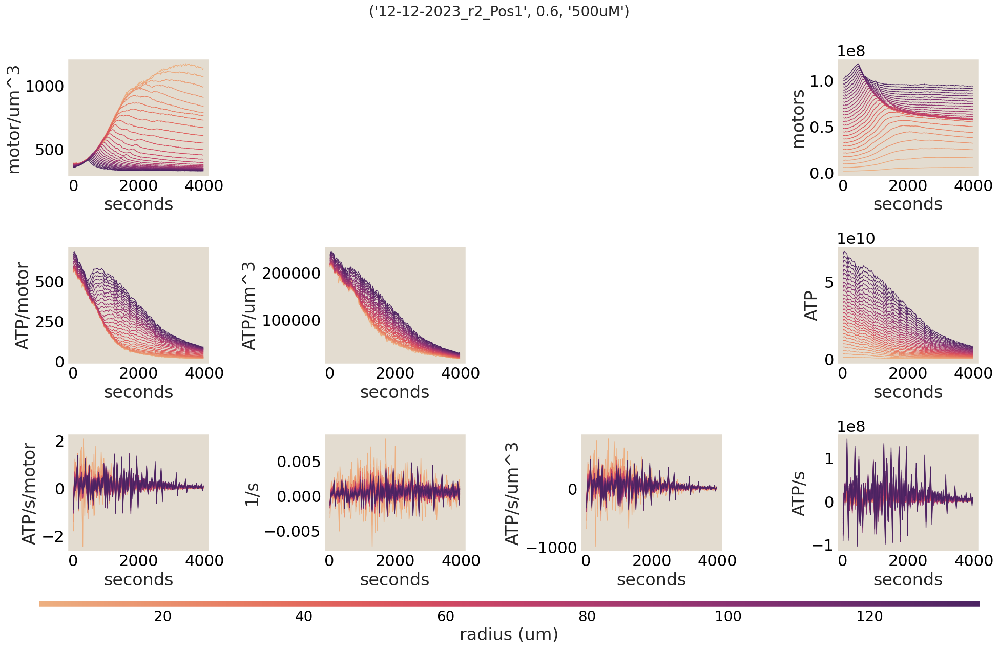

In [24]:
gname=gnameList[35] #good based on subplots 35, 27
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)

colorPalette = sns.color_palette('flare', as_cmap=True)
norm = matplotlib.colors.Normalize(vmin=min(h5dic['all_rATPbins'][0]*6*umperpixel), vmax=max(h5dic['all_rATPbins'][0]*6*umperpixel))

fig, ax = plt.subplots(3, 4, figsize=(20, 12))
#motor
# #motor units
for r, rad in enumerate(h5dic['all_rMotbins'][0]*umperpixel):
    ax[0][3].plot(h5dic['timesMot'], 
                  h5dic['MotShells'][:,r], 
                  color = colorPalette(norm(rad)),
                  lw=1)
ax[0][3].set_xlabel('seconds')
ax[0][3].set_ylabel('motors')

# #/um^3 units
MotPerum3 = NumPerum3(h5dic['MotShells'], h5dic['Mot_shell_vol_L'])
for r, rad in enumerate(h5dic['all_rMotbins'][0]*umperpixel):
    ax[0][0].plot(h5dic['timesMot'], 
                  MotPerum3[:,r], #h5dic['MotShells'][:,r]/(h5dic['Mot_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)),
                  lw=1)
ax[0][0].set_xlabel('seconds')
ax[0][0].set_ylabel('motor/um^3')

#atp
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[1][3].plot(h5dic['timesATP'], 
                  h5dic['ATPShells'][:,r], 
                  color = colorPalette(norm(rad)),
                  lw=1)
ax[1][3].set_xlabel('seconds')
ax[1][3].set_ylabel('ATP')

ATPPerum3 = NumPerum3(h5dic['ATPShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[1][1].plot(h5dic['timesATP'], 
                  ATPPerum3[:,r], #h5dic['ATPShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1,)
ax[1][1].set_xlabel('seconds')
ax[1][1].set_ylabel('ATP/um^3')

ATPPerMot = ((ATPPerum3[1:]+ATPPerum3[:-1])/2)/MotPerum3[1:-1] # average ATP shells for matching timepoints
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[1][0].plot(h5dic['timesPower'], 
                  ATPPerMot[:,r], #h5dic['powerShells'][:,r]/( (h5dic['ATPShells'][1:,r]+h5dic['ATPShells'][:-1,r])/2 ), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[1][0].set_xlabel('seconds')
ax[1][0].set_ylabel('ATP/motor')

#power
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[2][3].plot(h5dic['timesPower'], 
                  h5dic['powerShells'][:,r], 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2][3].set_xlabel('seconds')
ax[2][3].set_ylabel('ATP/s')

powPerum3 = NumPerum3(h5dic['powerShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[2][2].plot(h5dic['timesPower'], 
                  powPerum3[:,r], #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2][2].set_xlabel('seconds')
ax[2][2].set_ylabel('ATP/s/um^3')

#powPerMot = (h5dic['powerShells']/(h5dic['ATP_shell_vol_L']*1e-3*1e18))/(h5dic['MotShells'][1:-1]/(h5dic['Mot_shell_vol_L']*1e-3*1e18))
powPerMot = powPerum3 / MotPerum3[1:-1]
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[2][0].plot(h5dic['timesPower'], 
                  powPerMot[:,r], 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2][0].set_xlabel('seconds')
ax[2][0].set_ylabel('ATP/s/motor')

powPerATP = powPerum3 / ((ATPPerum3[1:]+ATPPerum3[:-1])/2) # average ATP shells for matching timepoints
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[2][1].plot(h5dic['timesPower'], 
                  powPerATP[:,r], #h5dic['powerShells'][:,r]/( (h5dic['ATPShells'][1:,r]+h5dic['ATPShells'][:-1,r])/2 ), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2][1].set_xlabel('seconds')
ax[2][1].set_ylabel('1/s')


# Adjust the top margin to make space for the colorbar
#fig.subplots_adjust(top=0.9)
fig.subplots_adjust(bottom=0.1)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 0, 0.92, 0.012])  # [left, bottom, width, height]
#cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=norm),
                    cax=cax, orientation='horizontal', label='radius (um)')
cbar.ax.tick_params(labelsize=20)
# # Iterate through all subplots to hide empty ones
for a in ax.flat:  # .flat iterates over all subplots in the grid
    if not a.has_data():  # Check if the subplot has any data
        a.set_visible(False)  # Hide the entire axis
plt.suptitle(summarizeGnameVerbose(gname,motName='_NCD_dimers_'), fontsize=20)
plt.tight_layout()

### 20250711 confirming power is what we think it is

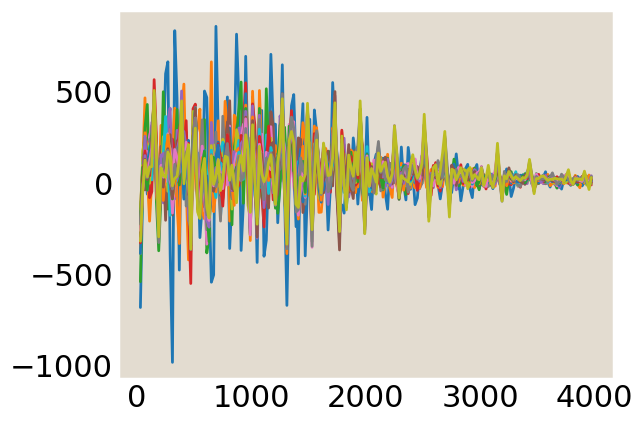

In [30]:
#show how to grab the power raw per shell (volumetric power de3nsity)
plt.plot(h5dic['timesATP'][1:], -np.diff(h5dic['all_rATPavgs'], axis=0)/20*600, lw=2);

Text(0, 0.5, 'Smoothed ATP/s/um^3')

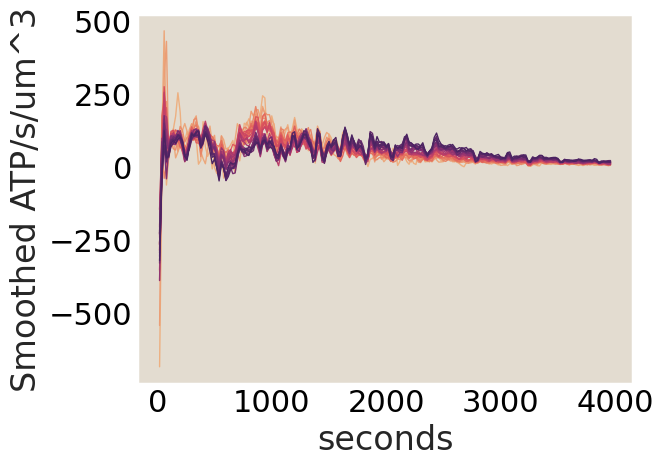

In [31]:


powPerum3 = NumPerum3(h5dic['powerShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    plt.plot(h5dic['timesPower'], 
                  float_avg(powPerum3[:,r], 4), #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
plt.xlabel('seconds')
plt.ylabel('Smoothed ATP/s/um^3')

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Text(0.5, 1.0, 'measured power density from ATP fields')

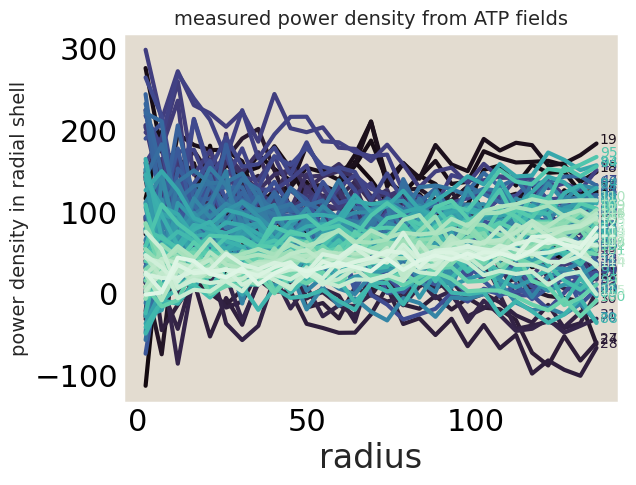

In [57]:
###### rePlot the trends above, but slicing with respect to 


# define helper function that takes as input an atp time and gives color
timesMot=h5dic['timesMot']
#global_timeCmap_Motmako=lambda time:sns.color_palette("mako", as_cmap=True)(matplotlib.colors.Normalize(vmin=minMottime, vmax=maxMottime)(time))

startTidx=12;
endTidx=120
global_timeCmap_Motmako=lambda time:sns.color_palette("mako", as_cmap=True)(matplotlib.colors.Normalize(vmin=timesMot[startTidx], vmax=timesMot[endTidx])(time))


radiiInUm=h5dic['all_rATPbins'][0]*6*umperpixel

powPerum3 = NumPerum3(h5dic['powerShells'], h5dic['ATP_shell_vol_L'])
tSmoothedPowPerum3=np.zeros_like(powPerum3)
for r in range(powPerum3.shape[1]):
    tSmoothedPowPerum3[:,r]=float_avg(powPerum3[:,r], 2)

colorPalette_time = sns.color_palette('flare', as_cmap=True)
norm_time = matplotlib.colors.Normalize(vmin=0,
                                        vmax=tSmoothedPowPerum3.shape[0])

for t in range(powPerum3.shape[0]):
    if t>=startTidx and t<=endTidx:
        plt.plot(radiiInUm, tSmoothedPowPerum3[t,:], color = global_timeCmap_Motmako(timesMot[t])) #color='b', alpha=0.1+0.9*(t/tSmoothedPowPerum3.shape[0]))
        plt.text(radiiInUm[-1]+1, tSmoothedPowPerum3[t,-1], str(t), fontsize=10, color=global_timeCmap_Motmako(timesMot[t]))

plt.xlabel('radius')
plt.ylabel('power density in radial shell', fontsize=14)
#plt.colorbar()

plt.title('measured power density from ATP fields', fontsize=14)



# for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
#     plt.plot(h5dic['timesPower'], 
#                   float_avg(powPerum3[:,r], 4), #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
#                   color = colorPalette(norm(rad)), 
#                   lw=1)
# # ax[2][2].set_xlabel('seconds')
# # ax[2][2].set_ylabel('ATP/s/um^3')

Text(0.5, 1.0, 'free energy to maintain motor distribution')

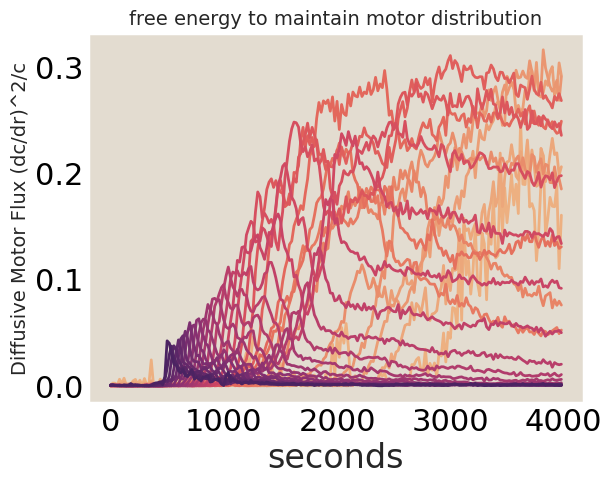

In [56]:
#try D(dc/dr)^2/c for motors: 

motSpaceum = np.diff(h5dic['all_rMotbins'][0]*umperpixel)[0]
motDiffFlux = (np.gradient(MotPerum3, axis=1)/motSpaceum)**2/MotPerum3

for r, rad in enumerate(h5dic['all_rMotbins'][0]*umperpixel):
    plt.plot(h5dic['timesMot'], 
                  motDiffFlux[:,r], #h5dic['MotShells'][:,r]/(h5dic['Mot_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)),
                  lw=2)
plt.xlabel('seconds')
plt.ylabel('Diffusive Motor Flux (dc/dr)^2/c', fontsize=14)

plt.title('free energy to maintain motor distribution', fontsize=14)

In [ ]:
# #### same plot as above, but sliced by time (and displayed vs radius on x axis)
# #try D(dc/dr)^2/c for motors: 

motSpaceum = np.diff(h5dic['all_rMotbins'][0]*umperpixel)[0]
motDiffFlux = (np.gradient(MotPerum3, axis=1)/motSpaceum)**2/MotPerum3

### go ahead and smooth, too.
smoothed_motDiffFlux = np.zeros_like(motDiffFlux)
for 

for r, rad in enumerate(h5dic['all_rMotbins'][0]*umperpixel):
    plt.plot(h5dic['timesMot'], 
                  motDiffFlux[:,r], #h5dic['MotShells'][:,r]/(h5dic['Mot_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)),
                  lw=2)
plt.xlabel('seconds')
plt.ylabel('Diffusive Motor Flux (dc/dr)^2/c', fontsize=14)

plt.title('free energy to maintain motor distribution', fontsize=14)

Let us predict based on the motors and ATP per micron values what the power should be at different times and radii

In [42]:
def predPowPerum3(mot, atp, KD = 30, gamma = 1):
    KDperum3 = KD*scipy.constants.N_A*1e-6*1000*1e-18
    return gamma*mot*atp/(KDperum3 + atp)

/tmp/ipykernel_306599/1935155883.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


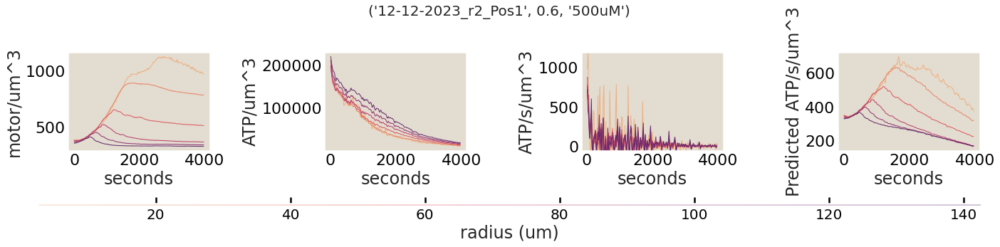

In [51]:
gname=gnameList[35] #good based on subplots 35, 27
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)

colorPalette = sns.color_palette('flare', as_cmap=True)
norm = matplotlib.colors.Normalize(vmin=min(h5dic['all_rATPbins'][0]*6*umperpixel), vmax=max(h5dic['all_rATPbins'][0]*6*umperpixel))

num_radii = 5
skip_int = int(len(h5dic['all_rATPbins'][0])/num_radii)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
#motor

# #/um^3 units
MotPerum3 = NumPerum3(h5dic['MotShells'], h5dic['Mot_shell_vol_L'])
for r, rad in enumerate((h5dic['all_rMotbins'][0]*umperpixel)[::skip_int]):
    ax[0].plot(h5dic['timesMot'], 
                  MotPerum3[:,r*skip_int], #h5dic['MotShells'][:,r]/(h5dic['Mot_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)),
                  lw=1)
ax[0].set_xlabel('seconds')
ax[0].set_ylabel('motor/um^3')

#atp
ATPPerum3 = NumPerum3(h5dic['ATPShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate((h5dic['all_rATPbins'][0]*6*umperpixel)[::skip_int]):
    ax[1].plot(h5dic['timesATP'], 
                  ATPPerum3[:,r*skip_int], #h5dic['ATPShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1,)
ax[1].set_xlabel('seconds')
ax[1].set_ylabel('ATP/um^3')


#power
powPerum3 = NumPerum3(h5dic['powerShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate((h5dic['all_rATPbins'][0]*6*umperpixel)[::skip_int]):
    ax[2].plot(h5dic['timesPower'], 
                  powPerum3[:,r*skip_int], #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2].set_xlabel('seconds')
ax[2].set_ylabel('ATP/s/um^3')
ax[2].set_ylim(-50, 1200)

#predict power
#sampTimes = h5dic['timesPower'][::10]
for r, rad in enumerate((h5dic['all_rATPbins'][0]*6*umperpixel)[::skip_int]):
    ax[3].plot(h5dic['timesPower'], 
                  predPowPerum3(MotPerum3[1:-1,r*skip_int], ((ATPPerum3[1:,r*skip_int]+ATPPerum3[:-1, r*skip_int])/2), KD = 30, gamma = 1), #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[3].set_xlabel('seconds')
ax[3].set_ylabel('Predicted ATP/s/um^3')



# Adjust the top margin to make space for the colorbar
#fig.subplots_adjust(top=0.9)
fig.subplots_adjust(bottom=0.1)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 0, 0.92, 0.012])  # [left, bottom, width, height]
#cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=norm),
                    cax=cax, orientation='horizontal', label='radius (um)')
cbar.ax.tick_params(labelsize=20)
# # Iterate through all subplots to hide empty ones
for a in ax.flat:  # .flat iterates over all subplots in the grid
    if not a.has_data():  # Check if the subplot has any data
        a.set_visible(False)  # Hide the entire axis
plt.suptitle(summarizeGnameVerbose(gname,motName='_NCD_dimers_'), fontsize=20)
plt.tight_layout()

(-50.0, 1200.0)

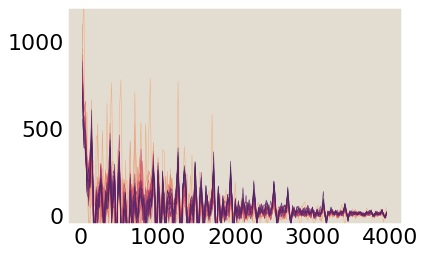

In [196]:
powPerum3 = NumPerum3(h5dic['powerShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    plt.plot(h5dic['timesPower'], 
                  powPerum3[:,r], #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=0.5,
                  alpha=1)
plt.ylim(-50, 1200)
# ax[2][2].set_xlabel('seconds')
# ax[2][2].set_ylabel('ATP/s/um^3')

/tmp/ipykernel_280731/210051430.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


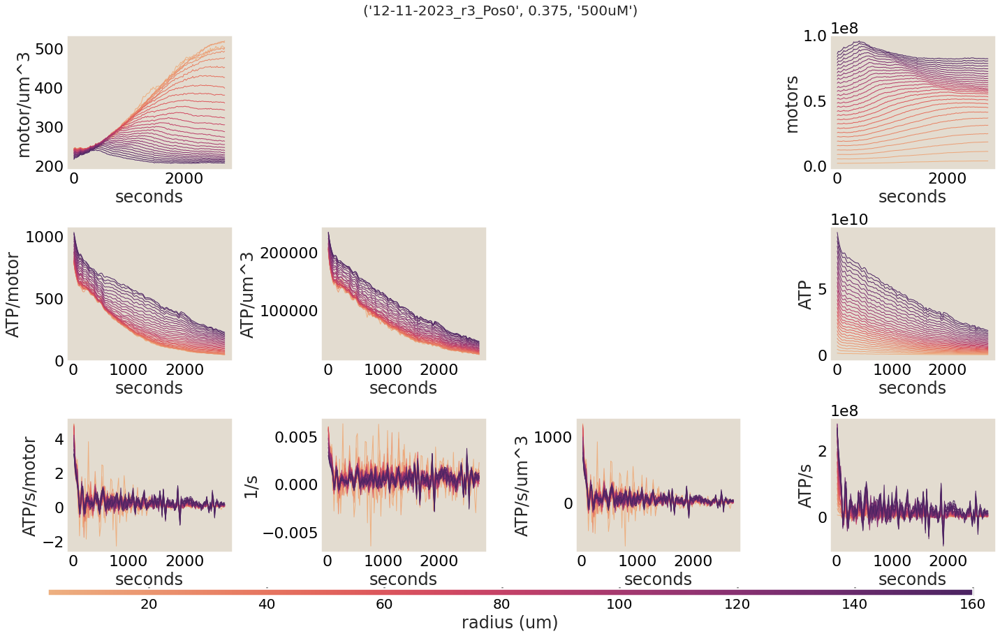

In [176]:
gname=gnameList[27] #good based on subplots 35, 27
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)

colorPalette = sns.color_palette('flare', as_cmap=True)
norm = matplotlib.colors.Normalize(vmin=min(h5dic['all_rATPbins'][0]*6*umperpixel), vmax=max(h5dic['all_rATPbins'][0]*6*umperpixel))

fig, ax = plt.subplots(3, 4, figsize=(20, 12))
#motor
# #motor units
for r, rad in enumerate(h5dic['all_rMotbins'][0]*umperpixel):
    ax[0][3].plot(h5dic['timesMot'], 
                  h5dic['MotShells'][:,r], 
                  color = colorPalette(norm(rad)),
                  lw=1)
ax[0][3].set_xlabel('seconds')
ax[0][3].set_ylabel('motors')

# #/um^3 units
MotPerum3 = NumPerum3(h5dic['MotShells'], h5dic['Mot_shell_vol_L'])
for r, rad in enumerate(h5dic['all_rMotbins'][0]*umperpixel):
    ax[0][0].plot(h5dic['timesMot'], 
                  MotPerum3[:,r], #h5dic['MotShells'][:,r]/(h5dic['Mot_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)),
                  lw=1)
ax[0][0].set_xlabel('seconds')
ax[0][0].set_ylabel('motor/um^3')

#atp
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[1][3].plot(h5dic['timesATP'], 
                  h5dic['ATPShells'][:,r], 
                  color = colorPalette(norm(rad)),
                  lw=1)
ax[1][3].set_xlabel('seconds')
ax[1][3].set_ylabel('ATP')

ATPPerum3 = NumPerum3(h5dic['ATPShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[1][1].plot(h5dic['timesATP'], 
                  ATPPerum3[:,r], #h5dic['ATPShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1,)
ax[1][1].set_xlabel('seconds')
ax[1][1].set_ylabel('ATP/um^3')

ATPPerMot = ((ATPPerum3[1:]+ATPPerum3[:-1])/2)/MotPerum3[1:-1] # average ATP shells for matching timepoints
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[1][0].plot(h5dic['timesPower'], 
                  ATPPerMot[:,r], #h5dic['powerShells'][:,r]/( (h5dic['ATPShells'][1:,r]+h5dic['ATPShells'][:-1,r])/2 ), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[1][0].set_xlabel('seconds')
ax[1][0].set_ylabel('ATP/motor')

#power
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[2][3].plot(h5dic['timesPower'], 
                  h5dic['powerShells'][:,r], 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2][3].set_xlabel('seconds')
ax[2][3].set_ylabel('ATP/s')

powPerum3 = NumPerum3(h5dic['powerShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[2][2].plot(h5dic['timesPower'], 
                  powPerum3[:,r], #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2][2].set_xlabel('seconds')
ax[2][2].set_ylabel('ATP/s/um^3')

#powPerMot = (h5dic['powerShells']/(h5dic['ATP_shell_vol_L']*1e-3*1e18))/(h5dic['MotShells'][1:-1]/(h5dic['Mot_shell_vol_L']*1e-3*1e18))
powPerMot = powPerum3 / MotPerum3[1:-1]
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[2][0].plot(h5dic['timesPower'], 
                  powPerMot[:,r], 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2][0].set_xlabel('seconds')
ax[2][0].set_ylabel('ATP/s/motor')

powPerATP = powPerum3 / ((ATPPerum3[1:]+ATPPerum3[:-1])/2) # average ATP shells for matching timepoints
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[2][1].plot(h5dic['timesPower'], 
                  powPerATP[:,r], #h5dic['powerShells'][:,r]/( (h5dic['ATPShells'][1:,r]+h5dic['ATPShells'][:-1,r])/2 ), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2][1].set_xlabel('seconds')
ax[2][1].set_ylabel('1/s')


# Adjust the top margin to make space for the colorbar
#fig.subplots_adjust(top=0.9)
fig.subplots_adjust(bottom=0.1)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 0, 0.92, 0.012])  # [left, bottom, width, height]
#cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=norm),
                    cax=cax, orientation='horizontal', label='radius (um)')
cbar.ax.tick_params(labelsize=20)
# # Iterate through all subplots to hide empty ones
for a in ax.flat:  # .flat iterates over all subplots in the grid
    if not a.has_data():  # Check if the subplot has any data
        a.set_visible(False)  # Hide the entire axis
plt.suptitle(summarizeGnameVerbose(gname,motName='_NCD_dimers_'), fontsize=20)
plt.tight_layout()

/tmp/ipykernel_306599/2437869209.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


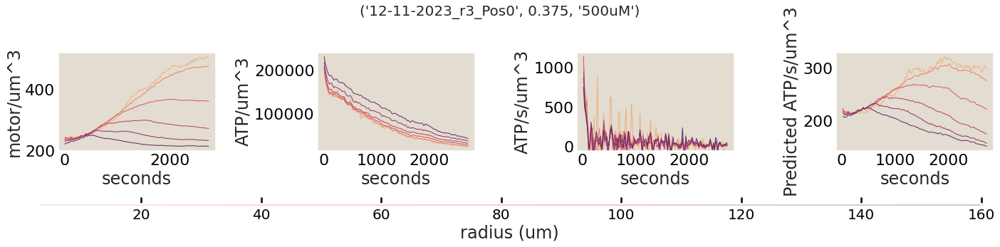

In [52]:
gname=gnameList[27] #good based on subplots 35, 27
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)

colorPalette = sns.color_palette('flare', as_cmap=True)
norm = matplotlib.colors.Normalize(vmin=min(h5dic['all_rATPbins'][0]*6*umperpixel), vmax=max(h5dic['all_rATPbins'][0]*6*umperpixel))

num_radii = 5
skip_int = int(len(h5dic['all_rATPbins'][0])/num_radii)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
#motor

# #/um^3 units
MotPerum3 = NumPerum3(h5dic['MotShells'], h5dic['Mot_shell_vol_L'])
for r, rad in enumerate((h5dic['all_rMotbins'][0]*umperpixel)[::skip_int]):
    ax[0].plot(h5dic['timesMot'], 
                  MotPerum3[:,r*skip_int], #h5dic['MotShells'][:,r]/(h5dic['Mot_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)),
                  lw=1)
ax[0].set_xlabel('seconds')
ax[0].set_ylabel('motor/um^3')

#atp
ATPPerum3 = NumPerum3(h5dic['ATPShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate((h5dic['all_rATPbins'][0]*6*umperpixel)[::skip_int]):
    ax[1].plot(h5dic['timesATP'], 
                  ATPPerum3[:,r*skip_int], #h5dic['ATPShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1,)
ax[1].set_xlabel('seconds')
ax[1].set_ylabel('ATP/um^3')


#power
powPerum3 = NumPerum3(h5dic['powerShells'], h5dic['ATP_shell_vol_L'])
for r, rad in enumerate((h5dic['all_rATPbins'][0]*6*umperpixel)[::skip_int]):
    ax[2].plot(h5dic['timesPower'], 
                  powPerum3[:,r*skip_int], #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[2].set_xlabel('seconds')
ax[2].set_ylabel('ATP/s/um^3')
ax[2].set_ylim(-50, 1200)

#predict power
#sampTimes = h5dic['timesPower'][::10]
for r, rad in enumerate((h5dic['all_rATPbins'][0]*6*umperpixel)[::skip_int]):
    ax[3].plot(h5dic['timesPower'], 
                  predPowPerum3(MotPerum3[1:-1,r*skip_int], ((ATPPerum3[1:,r*skip_int]+ATPPerum3[:-1, r*skip_int])/2), KD = 30, gamma = 1), #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=1)
ax[3].set_xlabel('seconds')
ax[3].set_ylabel('Predicted ATP/s/um^3')



# Adjust the top margin to make space for the colorbar
#fig.subplots_adjust(top=0.9)
fig.subplots_adjust(bottom=0.1)

# Create an axis for the colorbar that spans all columns
cax = fig.add_axes([0.05, 0, 0.92, 0.012])  # [left, bottom, width, height]
#cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# Create the colorbar
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=norm),
                    cax=cax, orientation='horizontal', label='radius (um)')
cbar.ax.tick_params(labelsize=20)
# # Iterate through all subplots to hide empty ones
for a in ax.flat:  # .flat iterates over all subplots in the grid
    if not a.has_data():  # Check if the subplot has any data
        a.set_visible(False)  # Hide the entire axis
plt.suptitle(summarizeGnameVerbose(gname,motName='_NCD_dimers_'), fontsize=20)
plt.tight_layout()

## Try smoothing power

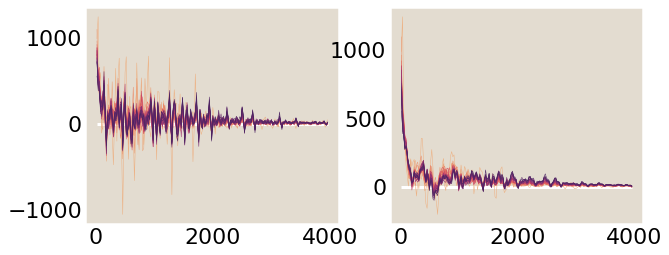

In [67]:
gname=gnameList[35] #good based on subplots 35, 27
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)

colorPalette = sns.color_palette('flare', as_cmap=True)
norm = matplotlib.colors.Normalize(vmin=min(h5dic['all_rATPbins'][0]*6*umperpixel), vmax=max(h5dic['all_rATPbins'][0]*6*umperpixel))


fig, ax = plt.subplots(1,2, figsize = (10,4))
powPerum3 = NumPerum3(h5dic['powerShells'], h5dic['ATP_shell_vol_L'])
ax[0].hlines(0, h5dic['timesPower'].min(), h5dic['timesPower'].max(), color='w')
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[0].plot(h5dic['timesPower'], 
                  powPerum3[:,r], #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=0.5,
                  alpha=1)
ax[1].hlines(0, h5dic['timesPower'].min(), h5dic['timesPower'].max(), color='w')
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    ax[1].plot(h5dic['timesPower'], 
                  float_avg(powPerum3[:,r],2), #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=0.5,
                  alpha=1)


# ax[2][2].set_xlabel('seconds')
# ax[2][2].set_ylabel('ATP/s/um^3')

(0.0, 1000.0)

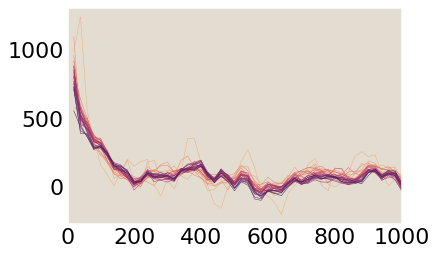

In [72]:
for r, rad in enumerate(h5dic['all_rATPbins'][0]*6*umperpixel):
    plt.plot(h5dic['timesPower'], 
                  float_avg(powPerum3[:,r],2), #h5dic['powerShells'][:,r]/(h5dic['ATP_shell_vol_L'][r]*1e-3*1e18), 
                  color = colorPalette(norm(rad)), 
                  lw=0.5,
                  alpha=1)
plt.xlim(0, 1000)

In [ ]:
gname=gnameList[35] #good based on subplots 35, 27
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)

colorPalette = sns.color_palette('flare', as_cmap=True)
norm = matplotlib.colors.Normalize(vmin=min(h5dic['all_rATPbins'][0]*6*umperpixel), vmax=max(h5dic['all_rATPbins'][0]*6*umperpixel))


In [132]:
(h5dic['timesMot'][1:]+h5dic['timesMot'][:-1])/2

array([  10.,   30.,   50.,   70.,   90.,  110.,  130.,  150.,  170.,
        190.,  210.,  230.,  250.,  270.,  290.,  310.,  330.,  350.,
        370.,  390.,  410.,  430.,  450.,  470.,  490.,  510.,  530.,
        550.,  570.,  590.,  610.,  630.,  650.,  670.,  690.,  710.,
        730.,  750.,  770.,  790.,  810.,  830.,  850.,  870.,  890.,
        910.,  930.,  950.,  970.,  990., 1010., 1030., 1050., 1070.,
       1090., 1110., 1130., 1150., 1170., 1190., 1210., 1230., 1250.,
       1270., 1290., 1310., 1330., 1350., 1370., 1390., 1410., 1430.,
       1450., 1470., 1490., 1510., 1530., 1550., 1570., 1590., 1610.,
       1630., 1650., 1670., 1690., 1710., 1730., 1750., 1770., 1790.,
       1810., 1830., 1850., 1870., 1890., 1910., 1930., 1950., 1970.,
       1990., 2010., 2030., 2050., 2070., 2090., 2110., 2130., 2150.,
       2170., 2190., 2210., 2230., 2250., 2270., 2290., 2310., 2330.,
       2350., 2370., 2390., 2410., 2430., 2450., 2470., 2490., 2510.,
       2530., 2550.,

In [133]:
h5dic['timesATP'], h5dic['timesMot'], h5dic['timesPower']

(array([  10.,   30.,   50.,   70.,   90.,  110.,  130.,  150.,  170.,
         190.,  210.,  230.,  250.,  270.,  290.,  310.,  330.,  350.,
         370.,  390.,  410.,  430.,  450.,  470.,  490.,  510.,  530.,
         550.,  570.,  590.,  610.,  630.,  650.,  670.,  690.,  710.,
         730.,  750.,  770.,  790.,  810.,  830.,  850.,  870.,  890.,
         910.,  930.,  950.,  970.,  990., 1010., 1030., 1050., 1070.,
        1090., 1110., 1130., 1150., 1170., 1190., 1210., 1230., 1250.,
        1270., 1290., 1310., 1330., 1350., 1370., 1390., 1410., 1430.,
        1450., 1470., 1490., 1510., 1530., 1550., 1570., 1590., 1610.,
        1630., 1650., 1670., 1690., 1710., 1730., 1750., 1770., 1790.,
        1810., 1830., 1850., 1870., 1890., 1910., 1930., 1950., 1970.,
        1990., 2010., 2030., 2050., 2070., 2090., 2110., 2130., 2150.,
        2170., 2190., 2210., 2230., 2250., 2270., 2290., 2310., 2330.,
        2350., 2370., 2390., 2410., 2430., 2450., 2470., 2490., 2510.,
      

In [ ]:
h5dic['MotShells'].shape

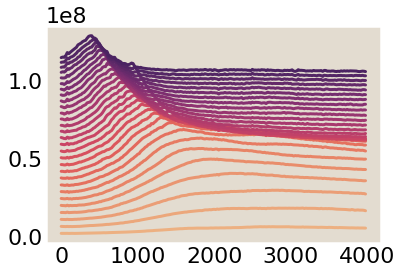

In [85]:
for r, rad in enumerate(h5dic['all_rMotbins'][0]):
    plt.plot(h5dic['timesMot'], h5dic['MotShells'][:,r], color = cbarFtn(h5dic['all_rMotbins'][0]*umperpixel)(rad*umperpixel))

In [86]:
h5dic['Mot_shell_vol_L']

array([5.73460334e-12, 1.72038100e-11, 2.86730167e-11, 4.01422234e-11,
       5.16114300e-11, 6.30806367e-11, 7.45498434e-11, 8.60190501e-11,
       9.74882567e-11, 1.08957463e-10, 1.20426670e-10, 1.31895877e-10,
       1.43365083e-10, 1.54834290e-10, 1.66303497e-10, 1.77772703e-10,
       1.89241910e-10, 2.00711117e-10, 2.12180324e-10, 2.23649530e-10,
       2.35118737e-10, 2.46587944e-10, 2.58057150e-10, 2.69526357e-10,
       2.80995564e-10, 2.92464770e-10, 3.03933977e-10, 3.15403184e-10,
       3.26872390e-10])

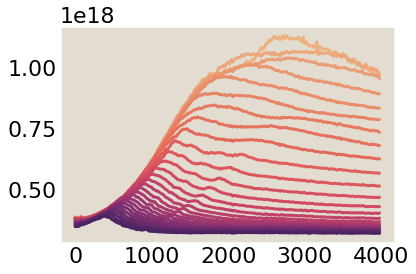

In [87]:
for r, rad in enumerate(h5dic['all_rMotbins'][0]):
    plt.plot(h5dic['timesMot'], h5dic['MotShells'][:,r]/h5dic['Mot_shell_vol_L'][r], color = cbarFtn(h5dic['all_rMotbins'][0]*umperpixel)(rad*umperpixel))

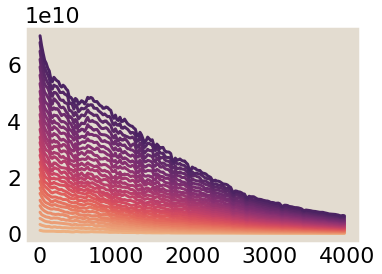

In [73]:
for r, rad in enumerate(h5dic['all_rATPbins'][0]):
    plt.plot(h5dic['timesATP'], h5dic['ATPShells'][:,r], color = cbarFtn(h5dic['all_rATPbins'][0])(rad))

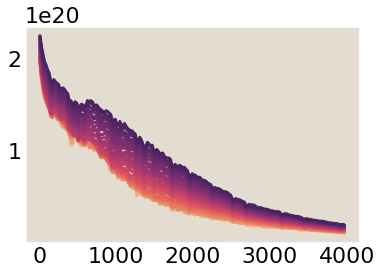

In [88]:
for r, rad in enumerate(h5dic['all_rATPbins'][0]):
    plt.plot(h5dic['timesATP'], h5dic['ATPShells'][:,r]/h5dic['ATP_shell_vol_L'][r], color = cbarFtn(h5dic['all_rATPbins'][0])(rad))

In [77]:
h5dic['all_rMotbins'][0], h5dic['all_rATPbins'][0]*6

(array([  4.32758621,  12.98275862,  21.63793103,  30.29310345,
         38.94827586,  47.60344828,  56.25862069,  64.9137931 ,
         73.56896552,  82.22413793,  90.87931034,  99.53448276,
        108.18965517, 116.84482759, 125.5       , 134.15517241,
        142.81034483, 151.46551724, 160.12068966, 168.77586207,
        177.43103448, 186.0862069 , 194.74137931, 203.39655172,
        212.05172414, 220.70689655, 229.36206897, 238.01724138,
        246.67241379]),
 array([  4.24137931,  12.72413793,  21.20689655,  29.68965517,
         38.17241379,  46.65517241,  55.13793103,  63.62068966,
         72.10344828,  80.5862069 ,  89.06896552,  97.55172414,
        106.03448276, 114.51724138, 123.        , 131.48275862,
        139.96551724, 148.44827586, 156.93103448, 165.4137931 ,
        173.89655172, 182.37931034, 190.86206897, 199.34482759,
        207.82758621, 216.31034483, 224.79310345, 233.27586207,
        241.75862069]))

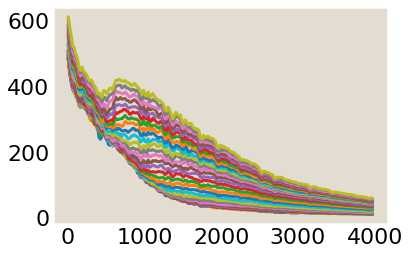

In [37]:
plt.plot(h5dic['timesATP'], h5dic['ATPShells']/h5dic['MotShells'][1:])

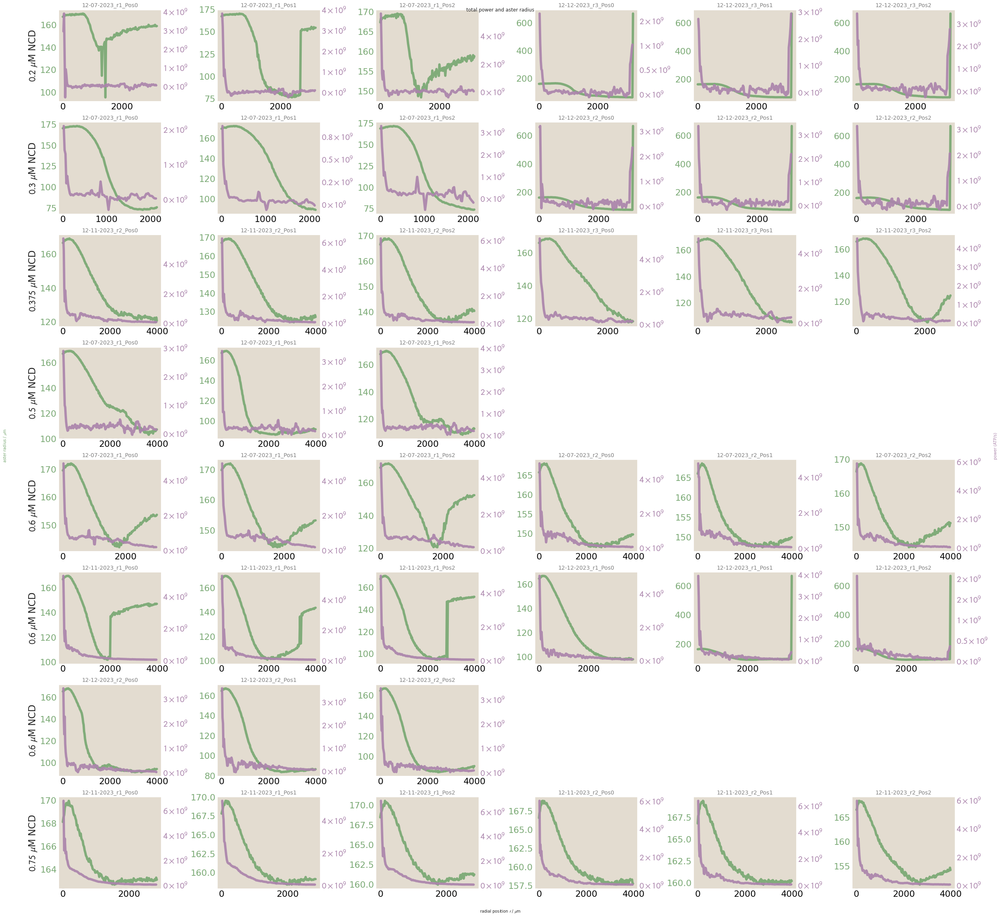

In [13]:
### aster radii fixed axes limits
uniqueConcs = np.unique(allProps_verb[:, 1])
nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
fig, axs = plt.subplots(nrows=nrows, 
                        ncols=ncols,
                        figsize=(34, 32))#, sharex=True, sharey=True)
rowCounter = 0  # Initialize row counter
colCounter = 0  # Initialize column counter
# Iterate over unique concentrations
for ii in range(len(uniqueConcs)):
    c = uniqueConcs[ii]
    # Get indices for this concentration
    idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
    if colCounter==0:
        axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
    # Iterate over indices for this concentration
    for j in range(len(idxsForThisC)):
        # Check if we've exceeded the subplot grid
        if rowCounter >= nrows:
            print("Warning: Not enough subplots to display all data.")
            break  # Exit if no more subplots are available
            
        axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
        # Plot data
        #axs[rowCounter, colCounter].plot(1, 1, 'ro')
        ## get this gname's analyzed data files & parse
        #axs[thisSubplIdx].plot(1,1, 'ro')
        h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
        h5dic = read_h5py(h5spath)
    
        # this is (numTimes, numRbinMidpoints)
        asterRadii=h5dic['radii']*umperpixel
        times=np.arange(len(asterRadii))*20; #20 seconds interval

        # also import power
        totalPowers=np.sum(h5dic['powerShells'], axis=1)
        smoothwindow=4
        totalPowers=float_avg(totalPowers, smoothwindow)
        times_power=h5dic['timesPower']
        
        # for time in range(len(times)):
        #     axs[rowCounter, colCounter].plot(times[time],
        #                            asterRadii[time], 'o', alpha=0.7+((time%20)==0)*0.2, 
        #                            color=sns.color_palette("flare", as_cmap=True)(time/len(times)), lw=2) 
        #     ## also plot apparent total power
        #     twin=axs[rowCounter, colCounter].twinx()
        #     twin.plot(times[time],
        #                            totalPowers[time], 'o-', alpha=0.7+((time%20)==0)*0.2, 
        #                            color=sns.color_palette("crest", as_cmap=True)(time/len(times)), lw=2)
        
        axs[rowCounter, colCounter].plot(times, asterRadii, '-', color=color_palette()['green'], label='radius', lw=6, alpha=0.93)
        yticklabels=axs[rowCounter, colCounter].get_yticklabels()
        for label in yticklabels:
            label.set_color(color_palette()['green']) 
        axs[rowCounter, colCounter].tick_params(axis='y', which='both', length=0)  # Set tick line length to 0

        twin=axs[rowCounter, colCounter].twinx()
        twin.plot(times_power, totalPowers, '-', color=color_palette()['purple'], label='power', lw=6, alpha=0.93)
        yticklabels=twin.get_yticklabels()
        for label in yticklabels:
            label.set_color(color_palette()['purple']) 
                    # Define the formatter function
        def scientific_notation_formatter(value, tick_number):
            return r"${:.1g} \times 10^9$".format(value / 1e9)
        
        # Apply the formatter to the y-axis
        twin.yaxis.set_major_formatter(ticker.FuncFormatter(scientific_notation_formatter))

        # Remove y-axis tick lines while keeping the labels
        twin.tick_params(axis='y', which='both', length=0)  # Set tick line length to 0


        
        
        # Move to the next column
        colCounter += 1
        # If we've reached the end of the columns, reset colCounter and increment rowCounter
        if colCounter >= ncols:
            colCounter = 0
            rowCounter += 1

    # After processing this concentration, move to the next row if not already at the start of a new row
    if colCounter != 0:
        colCounter = 0
        rowCounter += 1


# [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# hack for labeling
axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# Iterate through all subplots to hide empty ones
for ax in axs.flat:  # .flat iterates over all subplots in the grid
    if not ax.has_data():  # Check if the subplot has any data
        ax.set_visible(False)  # Hide the entire axis

plt.suptitle('total power and aster radius')
# Add a common x-label
fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# Add a common y-label
fig.text(-0.01, 0.5, 'aster radius / $\mu$m', ha='center', va='center', rotation=90, color=color_palette()['green'])
fig.text(1+0.01, 0.5, 'power (ATP/s)', ha='center', va='center', rotation=90, color=color_palette()['purple'])


# axs[0,0].set_ylim([-0.01, 500])
# axs[0,0].set_xlim([-0.01, 27])

# Adjust layout and display the plot
plt.tight_layout()

#plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_power_asterRadii_smooth4power.pdf', bbox_inches='tight')

In [ ]:
# ### aster raddii fixed axes limits
# uniqueConcs = np.unique(allProps_verb[:, 1])
# nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
# fig, axs = plt.subplots(nrows=nrows, 
#                         ncols=ncols,
#                         figsize=(34, 32))#, sharex=True, sharey=True)
# rowCounter = 0  # Initialize row counter
# colCounter = 0  # Initialize column counter
# # Iterate over unique concentrations
# for ii in range(len(uniqueConcs)):
#     c = uniqueConcs[ii]
#     # Get indices for this concentration
#     idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
#     if colCounter==0:
#         axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
#     # Iterate over indices for this concentration
#     for j in range(len(idxsForThisC)):
#         # Check if we've exceeded the subplot grid
#         if rowCounter >= nrows:
#             print("Warning: Not enough subplots to display all data.")
#             break  # Exit if no more subplots are available
            
#         axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
#         # Plot data
#         #axs[rowCounter, colCounter].plot(1, 1, 'ro')
#         ## get this gname's analyzed data files & parse
#         #axs[thisSubplIdx].plot(1,1, 'ro')
#         h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
#         h5dic = read_h5py(h5spath)
    
#         # this is (numTimes, numRbinMidpoints)
#         asterRadii=h5dic['radii']*umperpixel
#         times=np.arange(len(asterRadii))*20; #20 seconds interval

#         # also import power
#         totalPowers=np.sum(h5dic['powerShells'], axis=1)
#         smoothwindow=4
#         totalPowers=float_avg(totalPowers, smoothwindow)
#         times_power=h5dic['timesPower']
        
#         # for time in range(len(times)):
#         #     axs[rowCounter, colCounter].plot(times[time],
#         #                            asterRadii[time], 'o', alpha=0.7+((time%20)==0)*0.2, 
#         #                            color=sns.color_palette("flare", as_cmap=True)(time/len(times)), lw=2) 
#         #     ## also plot apparent total power
#         #     twin=axs[rowCounter, colCounter].twinx()
#         #     twin.plot(times[time],
#         #                            totalPowers[time], 'o-', alpha=0.7+((time%20)==0)*0.2, 
#         #                            color=sns.color_palette("crest", as_cmap=True)(time/len(times)), lw=2)
        
#         axs[rowCounter, colCounter].plot(times, asterRadii, '-', color=color_palette()['green'], label='radius', lw=6, alpha=0.93)
#         yticklabels=axs[rowCounter, colCounter].get_yticklabels()
#         for label in yticklabels:
#             label.set_color(color_palette()['green']) 
#         axs[rowCounter, colCounter].tick_params(axis='y', which='both', length=0)  # Set tick line length to 0

#         twin=axs[rowCounter, colCounter].twinx()
#         twin.plot(times_power, totalPowers, '-', color=color_palette()['purple'], label='power', lw=6, alpha=0.93)
#         yticklabels=twin.get_yticklabels()
#         for label in yticklabels:
#             label.set_color(color_palette()['purple']) 
#                     # Define the formatter function
#         def scientific_notation_formatter(value, tick_number):
#             return r"${:.1g} \times 10^9$".format(value / 1e9)
        
#         # Apply the formatter to the y-axis
#         twin.yaxis.set_major_formatter(ticker.FuncFormatter(scientific_notation_formatter))

#         # Remove y-axis tick lines while keeping the labels
#         twin.tick_params(axis='y', which='both', length=0)  # Set tick line length to 0


        
        
#         # Move to the next column
#         colCounter += 1
#         # If we've reached the end of the columns, reset colCounter and increment rowCounter
#         if colCounter >= ncols:
#             colCounter = 0
#             rowCounter += 1

#     # After processing this concentration, move to the next row if not already at the start of a new row
#     if colCounter != 0:
#         colCounter = 0
#         rowCounter += 1


# # [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# # hack for labeling
# axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
# axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# plt.suptitle('total power and aster radius')
# # Add a common x-label
# fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# # Add a common y-label
# fig.text(-0.01, 0.5, 'aster radius / $\mu$m', ha='center', va='center', rotation=90)
# fig.text(-0.01, 0.5, 'aster radius / $\mu$m', ha='center', va='center', rotation=90)

# # axs[0,0].set_ylim([-0.01, 500])
# # axs[0,0].set_xlim([-0.01, 27])

# # Adjust layout and display the plot
# plt.tight_layout()


# #### GLOBALLY defined fixed ylims, but different for twinx axes (one each for power, aster radius)
# # Set y-limits using list comprehensions
# [ax.set_ylim(primary_ylim) for ax in primary_axes]
# [twin_ax.set_ylim(twin_ylim) for twin_ax in twin_axes]

# plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_power_asterRadii_smooth4power_fixedAxesLimits.pdf', bbox_inches='tight')

### Visualizations, pending:
 * Radii versus time,
 * Total Power versus time,

 * power at radial position (per radial shell)
 * power per motor

Summaries:
* versus 

Troubleshooting:
* _Movies_:
    * subset of interesting movies (ATP_cent_cropped, mot_cent_cropped)
    * 

### prototype subplot array of aster radii trackings

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors

def drawCircles2(radii, centers, times, skip=10, ax=None, colorFunction=None, title=None):
    if ax is None:
        fig, ax = plt.subplots()
        ax.set_aspect('equal')

    if colorFunction is None:
        colorPalette = sns.color_palette("flare", as_cmap=True)
        norm = mcolors.Normalize(vmin=min(times), vmax=max(times))
        colorFunction = lambda x: colorPalette(norm(x))

    goodTimes=[t for t in range(0, len(times), skip)]
    goodTimes.append(-1) #make sure last is there
    
    for t in goodTimes:
        color = colorFunction(times[t])  # Removed extra parenthesis
        center = tuple(centers[t])  # Ensure center is a tuple
        circle = plt.Circle(center, radii[t], edgecolor=color,
                            facecolor='none', lw=1, alpha=0.8)
        ax.plot(*centers[t], '+', mec=color, mfc=color, alpha=0.8)
        ax.add_artist(circle)
        
        # if t % skip == 0:
        #     ax.text(
        #         centers[t][0] + radii[t] * np.cos(0.2 * np.pi * t / len(times)), 
        #         centers[t][1] + radii[t] * np.sin(0.2 * np.pi * t / len(times)),
        #         str(int(times[t])),
        #         fontsize=10,
        #         color=color,
        #         ha='center',
        #         va='center',
        #         bbox=dict(facecolor='#E3DCD0', edgecolor='none', boxstyle='round,pad=0')
        #     )

    if title:
        ax.set_title(title, color='grey')
    ax.relim()
    ax.invert_yaxis()
    ax.autoscale_view()

## parallelize and save tree-ring-plots in each directory


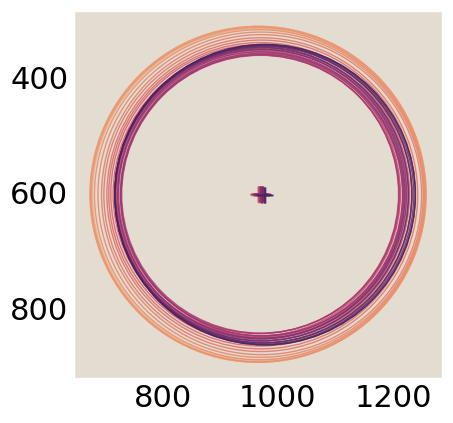

In [13]:
## example concentric plot
h5spath=gnameList[0].split('data')[0]+'analyzed_data'+gnameList[0].split('data')[1]+'/'
h5dic = read_h5py(h5spath)
radii = h5dic['radii']
centers = h5dic['center']

drawCircles2(radii, centers, times=h5dic['timesMot'], skip=5, title=)

In [19]:
## example concentric plot
def treeRingPlotHelper(gname, save=True):
    h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
    h5dic = read_h5py(h5spath)
    radii = h5dic['radii']
    centers = h5dic['center']
    times=h5dic['timesMot']
    title=summarizeGnameVerbose(gname)[0]
    drawCircles2(radii, centers, times, skip=5, title=title)
    if save:
        save_name = glob.glob(h5spath + '*mot.h5')[0].split('/')[-1].split('mot.h5')[0] #.strip('mot.h5')
        
        plt.savefig(h5spath+save_name+'_asterTreeCircPlot.pdf', bbox_inches='tight')

In [25]:
import concurrent.futures
list(concurrent.futures.ProcessPoolExecutor().map(treeRingPlotHelper, gnameList))

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]


KeyboardInterrupt



Error in callback <function _draw_all_if_interactive at 0x7fd3e6b01ab0> (for post_execute):


KeyboardInterrupt: 

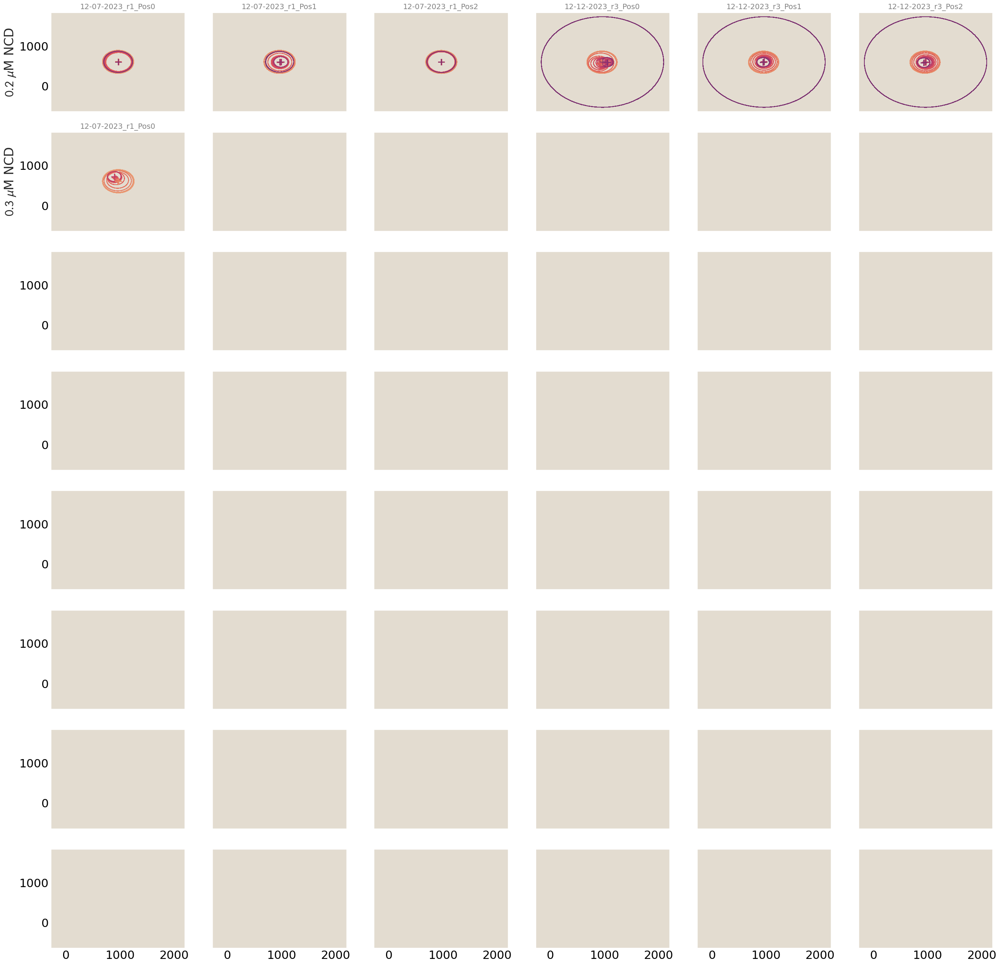

In [110]:
# ##### aster radii circles as giant grid, sadly takes too long?

# # define helper function that takes as input an atp time and gives color
# global_timeCmap_ATP=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minATPtime, vmax=maxATPtime)(time))
# global_timeCmap_Mot=lambda time:sns.color_palette("flare", as_cmap=True)(matplotlib.colors.Normalize(vmin=minMottime, vmax=maxMottime)(time))

# ### MOTORS
# uniqueConcs = np.unique(allProps_verb[:, 1])
# nrows, ncols = 8, 6  # Number of rows and columns in the subplot grid
# fig, axs = plt.subplots(nrows=nrows, 
#                         ncols=ncols,
#                         sharex=True,
#                         sharey=True,
#                         figsize=(32, 32))
# rowCounter = 0  # Initialize row counter
# colCounter = 0  # Initialize column counter
# # Iterate over unique concentrations
# for ii in range(len(uniqueConcs)):
#     c = uniqueConcs[ii]
#     # Get indices for this concentration
#     idxsForThisC = np.where(allProps_verb[:, 1] == c)[0]
#     if colCounter==0:
#         axs[rowCounter, colCounter].set_ylabel(r'$' + str(uniqueConcs[ii]) + r'\ \mu$M NCD')
    
#     # Iterate over indices for this concentration
#     for j in range(len(idxsForThisC)):
#         # Check if we've exceeded the subplot grid
#         if rowCounter >= nrows:
#             print("Warning: Not enough subplots to display all data.")
#             break  # Exit if no more subplots are available
            
#         axs[rowCounter, colCounter].set_title(allProps_verb[idxsForThisC[j], 0], fontsize=14, color='grey')
#         # Plot data
#         #axs[rowCounter, colCounter].plot(1, 1, 'ro')
#         ## get this gname's analyzed data files & parse
#         #axs[thisSubplIdx].plot(1,1, 'ro')
#         h5spath=gnameList[idxsForThisC[j]].split('data')[0]+'analyzed_data'+gnameList[idxsForThisC[j]].split('data')[1]+'/'
#         h5dic = read_h5py(h5spath)
    
#         # this is (numTimes, numRbinMidpoints)
#         radii = h5dic['radii']
#         centers = h5dic['center']
#         timesMot=h5dic['timesMot']
#         for time in range(len(timesMot)):
#             drawCircles2(radii, centers, timesMot, ax=axs[rowCounter, colCounter], colorFunction=global_timeCmap_Mot)
        
        
#         # Move to the next column
#         colCounter += 1
#         # If we've reached the end of the columns, reset colCounter and increment rowCounter
#         if colCounter >= ncols:
#             colCounter = 0
#             rowCounter += 1

#     # After processing this concentration, move to the next row if not already at the start of a new row
#     if colCounter != 0:
#         colCounter = 0
#         rowCounter += 1


# # [r'$' + str(c) + r'\ \mu$M NCD' for c in uniqueConcs]
# # hack for labeling
# axs[5,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');
# axs[6,0].set_ylabel(r'$' + str(uniqueConcs[4]) + r'\ \mu$M NCD');

# # Iterate through all subplots to hide empty ones
# for ax in axs.flat:  # .flat iterates over all subplots in the grid
#     if not ax.has_data():  # Check if the subplot has any data
#         ax.set_visible(False)  # Hide the entire axis

# plt.suptitle('ATP distributions')
# # Add a common x-label
# fig.text(0.5, -0.01, 'radial position $r$ / $\mu$m', ha='center', va='center')
# # Add a common y-label
# fig.text(-0.01, 0.5, '[ATP] / $\mu M$', ha='center', va='center', rotation=90)


# ######
# # Adjust the top margin to make space for the colorbar
# fig.subplots_adjust(top=0.85)

# # Create an axis for the colorbar that spans all columns
# cax = fig.add_axes([0.05, 1, 0.92, 0.012])  # [left, bottom, width, height]

# # Create the colorbar
# cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=sns.color_palette("flare", as_cmap=True), norm=mcolors.Normalize(vmin=minMottime, vmax=maxMottime)),
#                     cax=cax, orientation='horizontal')
# cbar.ax.tick_params(labelsize=20)

# # Move colorbar label and ticks to the top
# cbar.ax.xaxis.set_ticks_position('top')   # Move ticks to top
# cbar.ax.xaxis.set_label_position('top')   # Move label to top
# cbar.set_label('time / s', fontsize=20, labelpad=10)

# # GLOBAL ATP axis limits
# # axs[0,0].set_ylim([-0.01, 500])
# # axs[0,0].set_xlim([-0.01, 27])


# # Adjust layout and display the plot
# plt.tight_layout()

# plt.savefig('20241118_initialMultipleAster_smlMltpls_crrctGrid_asterCircles_globalTimeCmap.pdf', 
#             bbox_inches='tight')

## Center Views

In [46]:
def makeImFromValsList(valuesList, mask_coords, imshape):
    """ valuesList: numTimepoints x numValues, such that valuesList[t,:] is the list of values we populate in the returned image/array
        mask_coords: tuple of length 2; the first entry is 1d array of rowNums and the second entry is 1d array of colNums, of length = numValues (defined in mask)
        imshape: numImgRows x numImgCols.
        
        Returns imgArrayTotal = (numTimepoints x numImgRows x numImgCols) array where things are zero when outside the mask and otherwise populated by the provided valuesList in appropriate positions.
    """
    imgArrayTotal = np.zeros((len(valuesList), imshape[0], imshape[1]))
    for t in range(len(valuesList)):
        imgArrayTotal[t,mask_coords[0], mask_coords[1]]=valuesList[t,:]
    
    return imgArrayTotal

In [50]:
def overlayCenters(array, radii, centers, frameint=5, xmin=0, xmax=-1, ymin=0, ymax=-1, save=False):
    ncols = 5
    nrows = int(np.ceil(len(array)/frameint/ncols))
    crop = np.s_[ymin:ymax, xmin:xmax]
    fig, ax = plt.subplots(nrows, ncols, figsize = (4*ncols,4*nrows) )

    for i, im in enumerate(array[::frameint]):
        j=i*frameint
        ax[int(i/ncols)][i%ncols].imshow(im[crop], vmin = 0, vmax = np.percentile(im, 99.9))
        ax[int(i/ncols)][i%ncols].scatter(centers[j][0]-xmin, centers[j][1]-ymin, s=10, c='k')

        circle = plt.Circle((centers[j][0]-xmin, 
                             centers[j][1]-ymin), 
                            radii[j], 
                            edgecolor='b',
                            facecolor='none', 
                            lw=1, 
                            alpha=0.8)
        ax[int(i/ncols)][i%ncols].add_artist(circle)
        del circle
        ax[int(i/ncols)][i%ncols].set_title(j)

        # if i==0:
        #     circle = plt.Circle((centers[195][0]-xmin, 
        #                      centers[195][1]-ymin), 
        #                     radii[195], 
        #                     edgecolor='b',
        #                     facecolor='none', 
        #                     lw=1, 
        #                     alpha=0.8)
        #     ax[0][0].add_artist(circle)
        #     ax[0][0].set_title(i)
        
        #remove axis tick labels
        ax[int(i/ncols)][i%ncols].set_xticklabels([])
        ax[int(i/ncols)][i%ncols].set_yticklabels([])
    # # Iterate through all subplots to hide empty ones
    for a in ax.flat:  # .flat iterates over all subplots in the grid
        if not a.has_data():  # Check if the subplot has any data
            a.set_visible(False)  # Hide the entire axis
    plt.tight_layout()

In [71]:
def centerVisPlots(gname, save=True):
    #read in dataframes
    h5spath = gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
    h5dic = read_h5py(h5spath)#, excludes=['_centCrop'])
    #print(len(h5dic.keys()))
    
    #Turn data into an image shape (parse)
    #ATP_conc_ims = makeImFromValsList(h5dic['ATP'], h5dic['mask_coords'], h5dic['imshape'])
    mot_conc_ims = makeImFromValsList(h5dic['mot'], h5dic['mask_coords'], h5dic['imshape'])
    #mango_mask = makeImFromValsList(np.ones((len(h5dic['mot']), len(h5dic['mask_coords'][0]))), h5dic['mask_coords'], h5dic['imshape'])[0].astype('int')

    overlayCenters(mot_conc_ims, h5dic['radii'],  h5dic['center'], frameint=5, xmin=600, xmax=1300, ymin=250, ymax=950)
    
    plt.suptitle(summarizeGnameVerbose(gname,motName='_NCD_dimers_'), y=1.01)
    print(str(summarizeGnameVerbose(gname,motName='_NCD_dimers_'))+' Begin save')
    if save:
        save_name = glob.glob(h5spath + '*mot.h5')[0].split('/')[-1].split('mot.h5')[0] #.strip('mot.h5')
        
        plt.savefig(h5spath+save_name+'_centTrackPlot.pdf', bbox_inches='tight')
    print(str(summarizeGnameVerbose(gname,motName='_NCD_dimers_'))+' DONE')

In [69]:
gnameList[0]

np.str_('../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos0.ome.tif')

In [74]:
import concurrent.futures
list(concurrent.futures.ProcessPoolExecutor().map(centerVisPlots, 
                                                  gnameList))

('12-11-2023_r1_Pos1', 0.6, '500uM') Begin save
('12-11-2023_r1_Pos1', 0.6, '500uM') DONE
('12-11-2023_r2_Pos0', 0.375, '500uM') Begin save
('12-11-2023_r1_Pos1', 0.75, '500uM') Begin save
('12-11-2023_r2_Pos0', 0.375, '500uM') DONE
('12-11-2023_r1_Pos1', 0.75, '500uM') DONE
('12-12-2023_r3_Pos1', 0.2, '500uM') Begin save
('12-12-2023_r2_Pos1', 0.3, '500uM') Begin save
('12-12-2023_r3_Pos1', 0.2, '500uM') DONE
('12-12-2023_r2_Pos1', 0.3, '500uM') DONE
('12-07-2023_r1_Pos0', 0.2, '500uM') Begin save
('12-07-2023_r1_Pos0', 0.2, '500uM') DONE
('12-12-2023_r3_Pos2', 0.2, '500uM') Begin save
('12-07-2023_r1_Pos2', 0.3, '500uM') Begin save
('12-07-2023_r1_Pos2', 0.3, '500uM') DONE
('12-12-2023_r3_Pos2', 0.2, '500uM') DONE
('12-11-2023_r2_Pos2', 0.375, '500uM') Begin save
('12-11-2023_r2_Pos2', 0.375, '500uM') DONE
('12-07-2023_r1_Pos2', 0.5, '500uM') Begin save
('12-07-2023_r1_Pos0', 0.3, '500uM') Begin save
('12-12-2023_r2_Pos1', 0.6, '500uM') Begin save
('12-07-2023_r1_Pos0', 0.3, '500uM')

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [47]:
gnameList[0]

np.str_('../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos0.ome.tif')

# flux

In [31]:
list(h5dic.keys())

['imshape',
 'timesMot',
 'radii',
 'timesATP',
 'all_rMotbins',
 'Mot_shell_vol_L',
 'MotShells',
 'mot_centCrop',
 'ATPShells',
 'center',
 'mask_coords',
 'ATP_centCrop',
 'all_rMotavgs',
 'ATP',
 'ATP_shell_vol_L',
 'all_rATPbins',
 'timesPower',
 'all_rATPavgs',
 'mot',
 'powerShells']

In [253]:
gname = '../../data/aster/Ncd_Aster_assay_12-12-2023/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2_MMStack_Pos1.ome.tif'
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)



In [254]:
h5dic.keys()

dict_keys(['ATP_centCrop', 'Mot_shell_vol_L', 'mot', 'all_rMotbins', 'ATPShells', 'all_rATPavgs', 'timesMot', 'imshape', 'MotShells', 'ATP_shell_vol_L', 'powerShells', 'timesPower', 'all_rMotavgs', 'ATP', 'mask_coords', 'mot_centCrop', 'timesATP', 'all_rATPbins'])

$$J_s = \frac{r}{2}\frac{\partial c(r,t)}{\partial t}$$
$$J_s = \frac{r}{2}\frac{c(r,t+\Delta t) - c(r,t)}{\Delta t}$$

For a given circle with a radius $R$, the concentration inside is
$$c(R,t) = \frac{\sum_r^R c_rV_r}{V_R}$$

Find the different mechanisms of flux upon each shell

### Plot raw motor concentrations

(200, 29)

In [257]:
np.abs(h5dic['all_rMotavgs'][time,:]/min(spatialGrad))

array([0.00045596, 0.00045428, 0.00044762, 0.00041887, 0.00039103,
       0.00036943, 0.00034494, 0.00031973, 0.00029381, 0.00026655,
       0.00024208, 0.0002206 , 0.00020288, 0.00019058, 0.00018069,
       0.00017424, 0.0001695 , 0.00016691, 0.00016476, 0.00016271,
       0.00016172, 0.00016114, 0.00015963, 0.00015809, 0.00015665,
       0.00015566, 0.00015422, 0.00015302, 0.00015152])

<>:23: SyntaxWarning: invalid escape sequence '\m'
<>:23: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_37599/1670941129.py:23: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('motor concentration $c(r,t)$/$\mu$M')


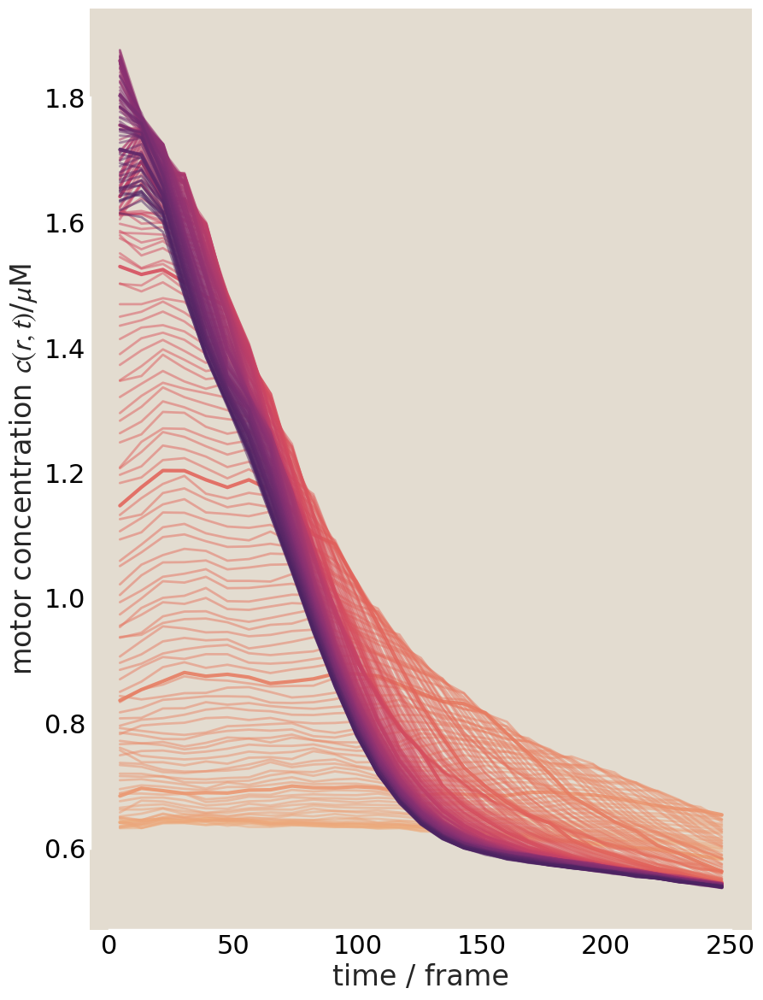

In [258]:

apparentLambda=np.zeros(len(h5dic['timesMot']))
rsteepestMots=np.zeros(len(h5dic['timesMot']))

fig, ax = plt.subplots(figsize=(10,14))
for time in range(len(h5dic['timesMot'])):
    plt.plot(h5dic['all_rMotbins'][time,:], h5dic['all_rMotavgs'][time,:], '-', 
             alpha=0.5+((time%20)==0)*0.4, 
             color=sns.color_palette("flare", as_cmap=True)(time/len(h5dic['timesMot'])), 
             lw=2+((time%20)==0)*1)
    # plot point of maximum spatial gradient
    spatialGrad=np.gradient(h5dic['all_rMotbins'][time,:], h5dic['all_rMotavgs'][time,:])

    steepestRidx=np.where(spatialGrad==min(spatialGrad))[0][0]
    
    apparentLambda[time]=np.abs(h5dic['all_rMotavgs'][time,steepestRidx]/min(spatialGrad))
    
    rsteepestMots[time]=h5dic['all_rMotbins'][time,steepestRidx]
    # plt.plot(all_rbins_mot[time, steepestRidx], 
    #          all_rMOTavgs[time,steepestRidx], 
    #          'o', alpha=0.5+((time%20)==0)*0.4, color=sns.color_palette("flare", as_cmap=True)(time/new_najAsterMot.shape[0]), mew=2+((time%20)==0)*1, mfc='None')

plt.xlabel('time / frame')
plt.ylabel('motor concentration $c(r,t)$/$\mu$M')
    
sns.despine(trim=True)

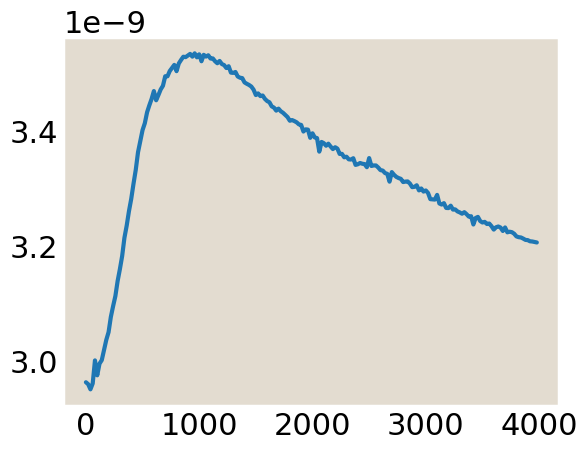

In [280]:
plt.plot(h5dic['timesMot'], np.sum(h5dic['all_rMotavgs']*h5dic['Mot_shell_vol_L'], axis=1))

In [259]:
#multiply the conc of each ring by the ring volume and unit convert to get number
summedNumber = np.cumsum(h5dic['all_rMotavgs']*h5dic['Mot_shell_vol_L'], axis=1)*1e-6*scipy.constants.N_A #number of motors
#area of the interface
depth=70 #um
areaInterface = 2*np.pi*h5dic['all_rMotbins'][0]*depth # um^2
#compute the total flux as the ∆number/area ∆t
Jtot = np.diff(summedNumber, axis=0)/(areaInterface*np.diff(h5dic['timesMot'][:2]))
                                    
uMtoPerum3 = scipy.constants.N_A*(1e-21)
motD = 30 #um^2/s
Jdiff = -motD* np.diff(h5dic['all_rMotavgs'], axis=1)*uMtoPerum3/np.diff(h5dic['all_rMotbins'][0,:2])

Jsource = Jtot[:,:-1]-(Jdiff[1:]+Jdiff[:-1])/2
#summedVol = np.cumsum(h5dic['Mot_shell_vol_L'])

Text(0, 0.5, 'Total Flux ($s^{-1}\\mu m^{-2}$)')

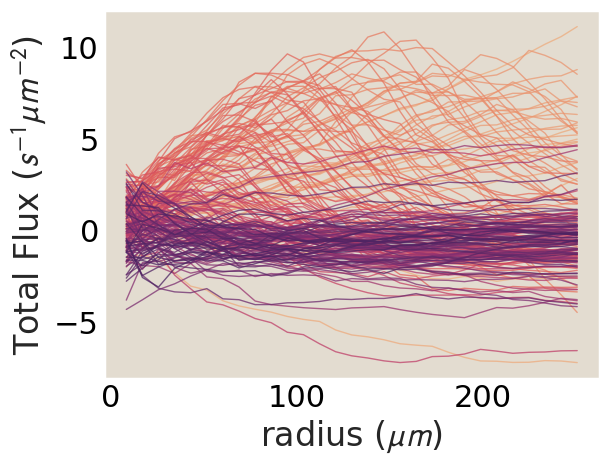

In [260]:
for t, time in enumerate((h5dic['timesMot'][1:]+h5dic['timesMot'][:-1])/2):
    plt.plot(h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2, 
             Jtot[t], 
             color = cbarFtn(h5dic['timesMot'])(time),
             lw=1,
            alpha = 0.75)
plt.xlabel(r'radius ($\mu m$)')
plt.ylabel(r'Total Flux ($s^{-1}\mu m^{-2}$)')

Text(0, 0.5, 'Total Flux ($s^{-1}\\mu m^{-2}$)')

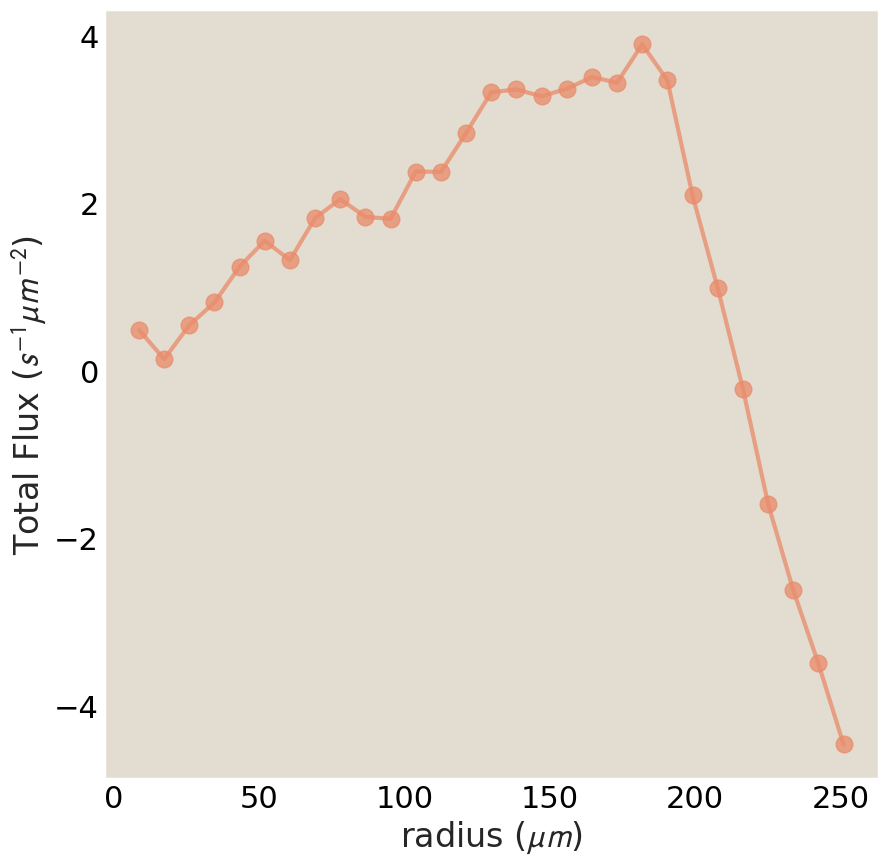

In [261]:
t=30
fig, ax=plt.subplots(figsize=(10,10))
plt.plot(h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2, 
             Jtot[t], 
             color = cbarFtn(h5dic['timesMot'])(t*20),
             marker='o',
            alpha = 0.75)
plt.xlabel(r'radius ($\mu m$)')
plt.ylabel(r'Total Flux ($s^{-1}\mu m^{-2}$)')
# plt.yscale('log')
# plt.xscale('log')
#ax.set_aspect('equal')
# plt.ylim([1, plt.ylim()[-1]])

# plt.plot([10, 1e3], [2, 2*(10**2)*2], 'k-')
# plt.plot([10, 1e3], [2, 2*(10**2)*3], 'k--')
# plt.plot([10, 1e3], [2, 2*(10**2)*4], 'g--')

/tmp/ipykernel_37599/3904239033.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax=plt.subplots(figsize=(5,5))


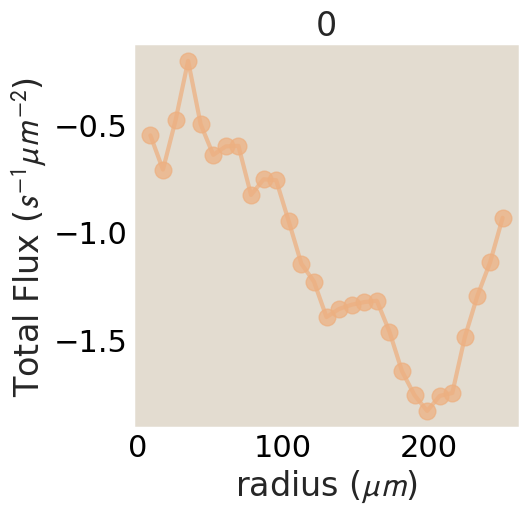

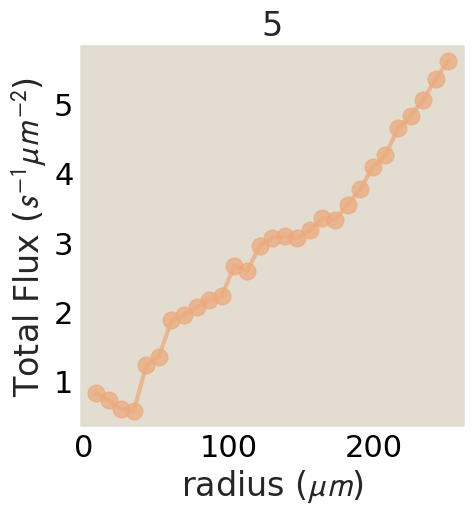

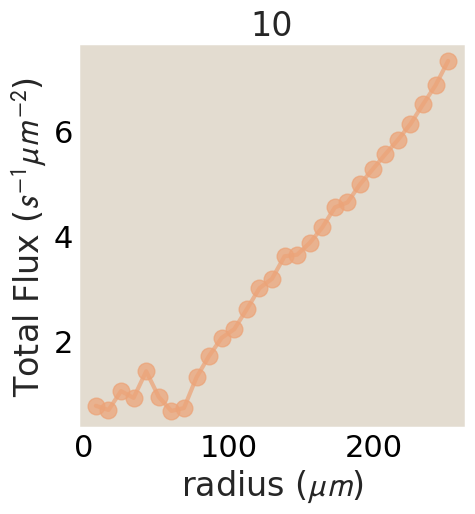

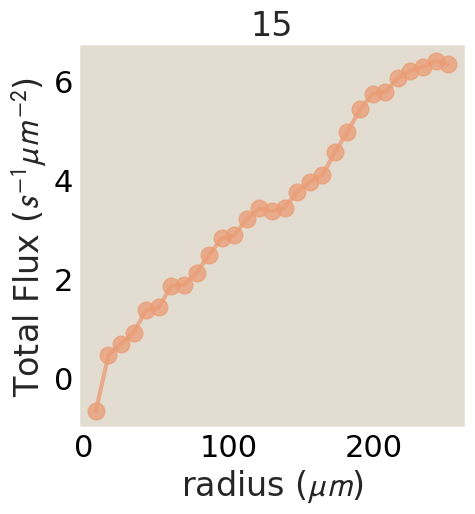

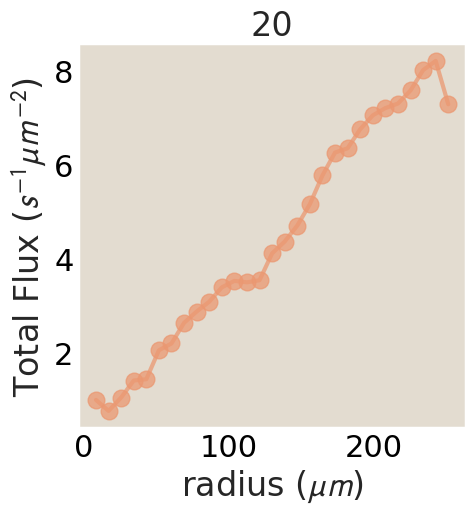

...

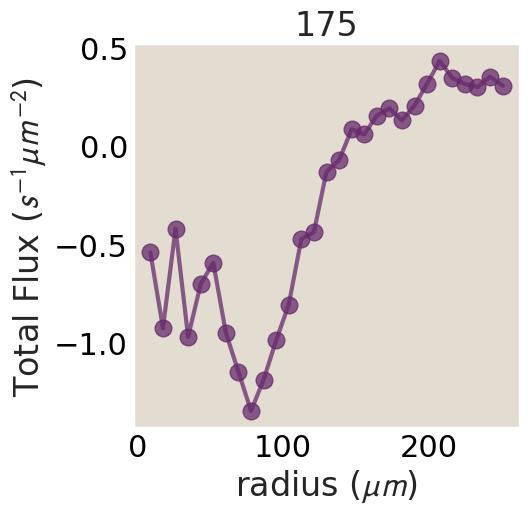

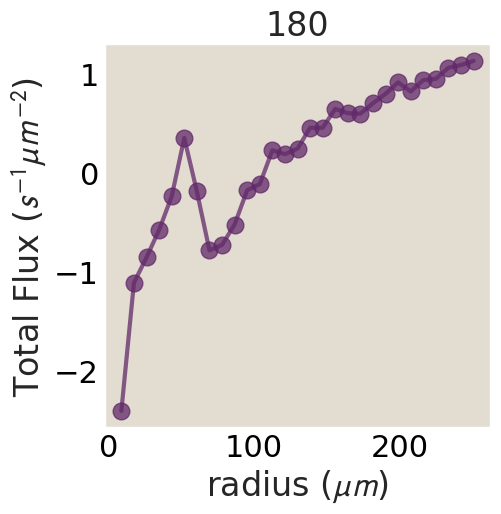

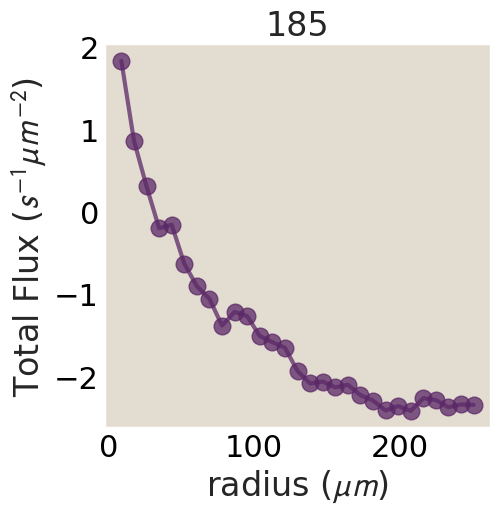

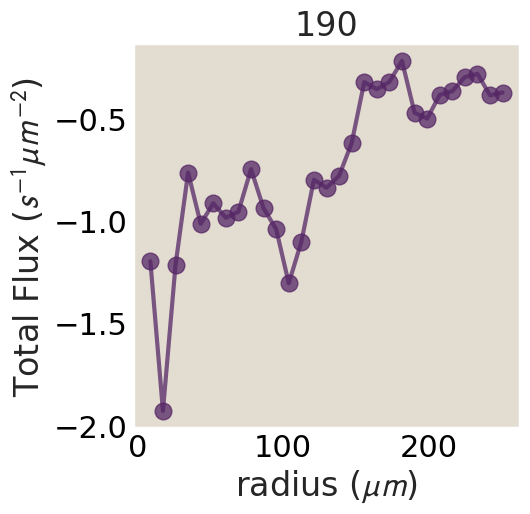

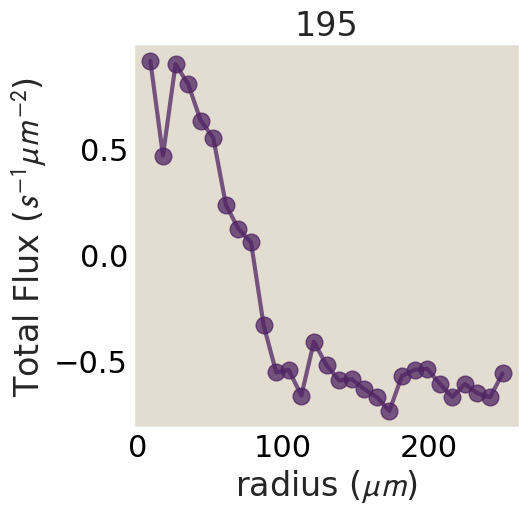

In [275]:
for t in range(0, 199, 5):
    fig, ax=plt.subplots(figsize=(5,5))
    plt.plot(h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2, 
                 Jtot[t], 
                 color = cbarFtn(h5dic['timesMot'])(t*20),
                 marker='o',
                alpha = 0.75)
    plt.xlabel(r'radius ($\mu m$)')
    plt.ylabel(r'Total Flux ($s^{-1}\mu m^{-2}$)')
    # plt.yscale('log')
    # plt.xscale('log')
    # ax.set_aspect('equal')
    # plt.ylim([1, plt.ylim()[-1]])
    
    # plt.plot([10, 1e3], [2, 2*(1e3/10)**2], 'k-') # quadratic
    # plt.plot([10, 1e3], [2, 2*(1e3/10)**1], 'k-') # quadratic
    
    plt.title(str(t))

In [263]:
## approximate power law exponent
shellSurfaceRadii=h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2
np.log(Jtot[10][-1]/Jtot[10][0])/np.log(shellSurfaceRadii[-1]/shellSurfaceRadii[0])

np.float64(0.6711655320015534)

In [264]:
cbarFtn(h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2)

<function __main__.cbarFtn.<locals>.<lambda>(x)>

(0.0, 2000.0)

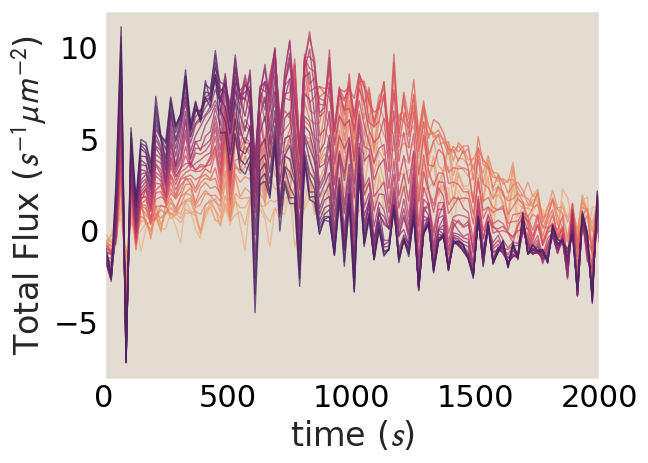

In [276]:

for r, rad in enumerate(h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2):
    plt.plot((h5dic['timesMot'][1:]+h5dic['timesMot'][:-1])/2, 
             Jtot[:,r], 
             color = cbarFtn(h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2)(rad),
             lw=1,
            alpha = 0.75)
plt.xlabel(r'time ($s$)')
plt.ylabel(r'Total Flux ($s^{-1}\mu m^{-2}$)')
plt.xlim(0, 2000)

Text(0, 0.5, 'Diffusive Flux ($s^{-1}\\mu m^{-2}$)')

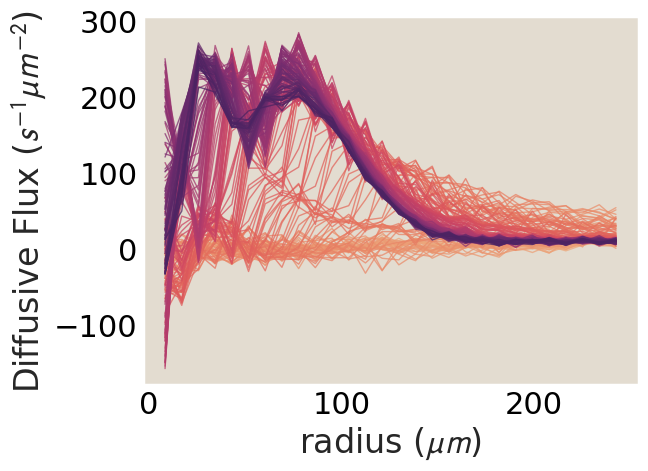

In [266]:
for t, time in enumerate(h5dic['timesMot']):
    plt.plot((h5dic['all_rMotbins'][0][1:]+h5dic['all_rMotbins'][0][:-1])/2, 
             Jdiff[t], 
             color = cbarFtn(h5dic['timesMot'])(time),
             lw=1,
            alpha = 0.75)
plt.xlabel(r'radius ($\mu m$)')
plt.ylabel(r'Diffusive Flux ($s^{-1}\mu m^{-2}$)')

Text(0, 0.5, 'Diffusive Flux ($s^{-1}\\mu m^{-2}$)')

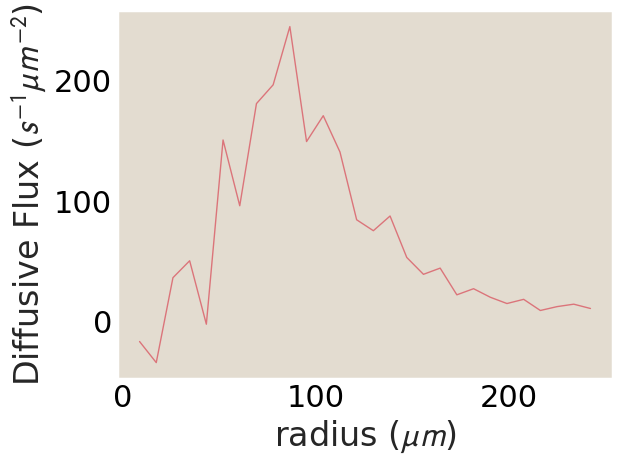

In [267]:
t=76
plt.plot((h5dic['all_rMotbins'][0][1:]+h5dic['all_rMotbins'][0][:-1])/2, 
             Jdiff[t], 
             color = cbarFtn(h5dic['timesMot'])(t*20),
             lw=1,
            alpha = 0.75)
plt.xlabel(r'radius ($\mu m$)')
plt.ylabel(r'Diffusive Flux ($s^{-1}\mu m^{-2}$)')

/tmp/ipykernel_37599/1875990428.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10,10))


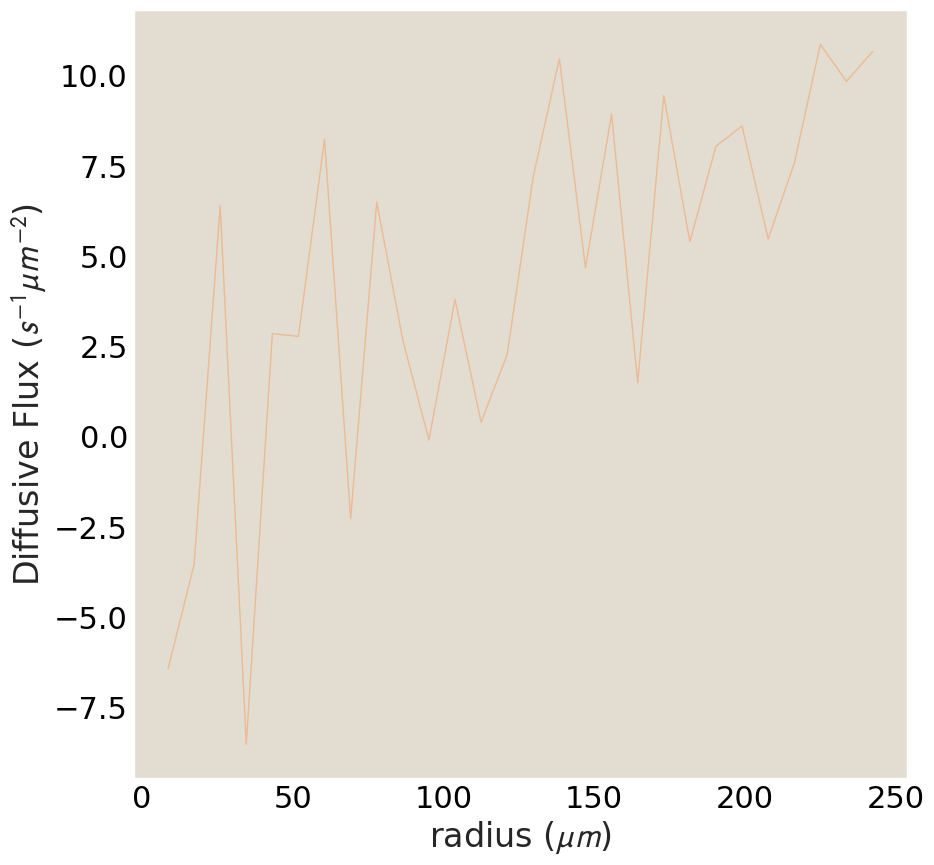

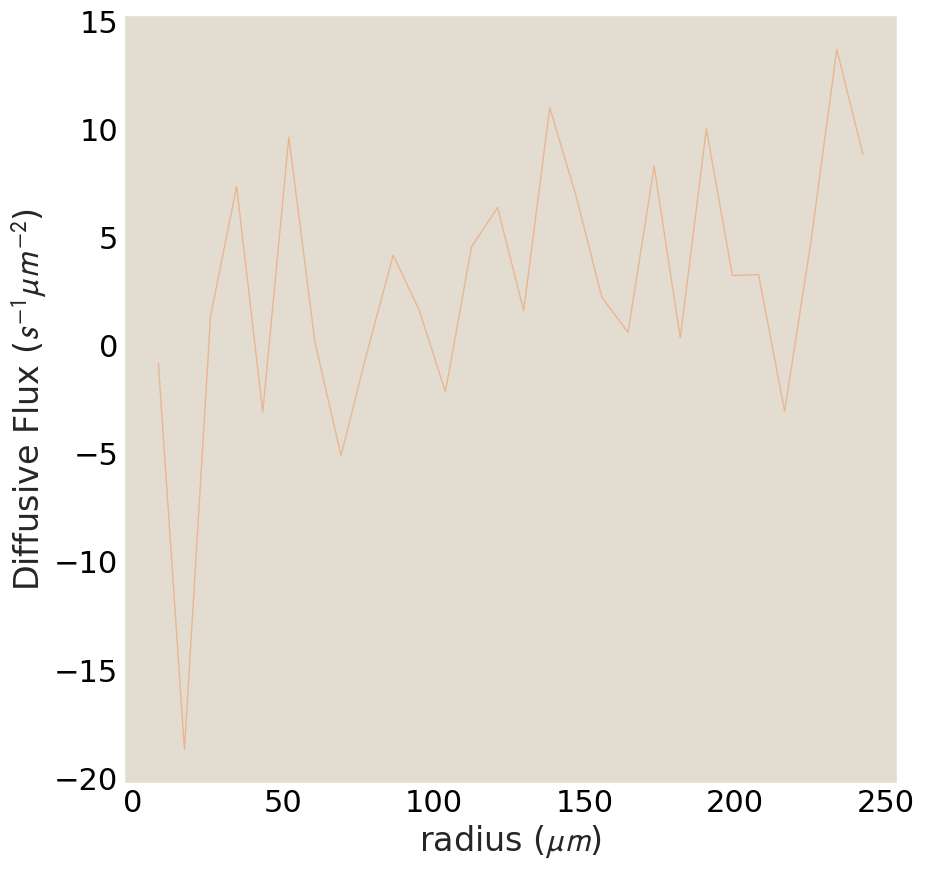

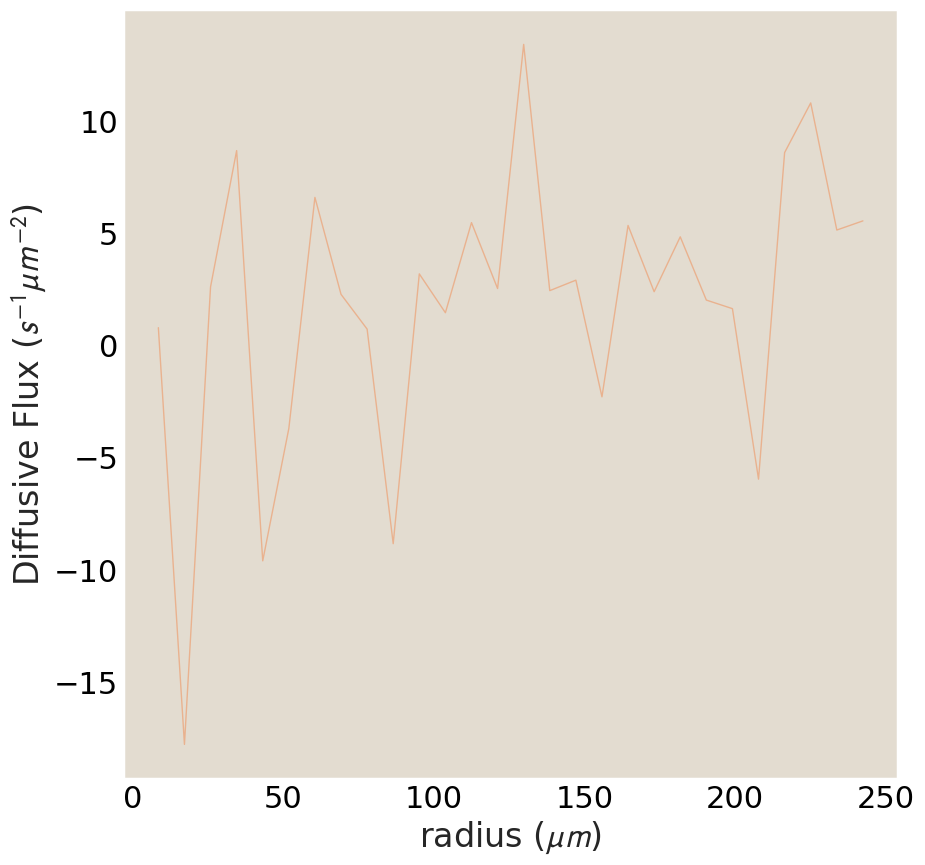

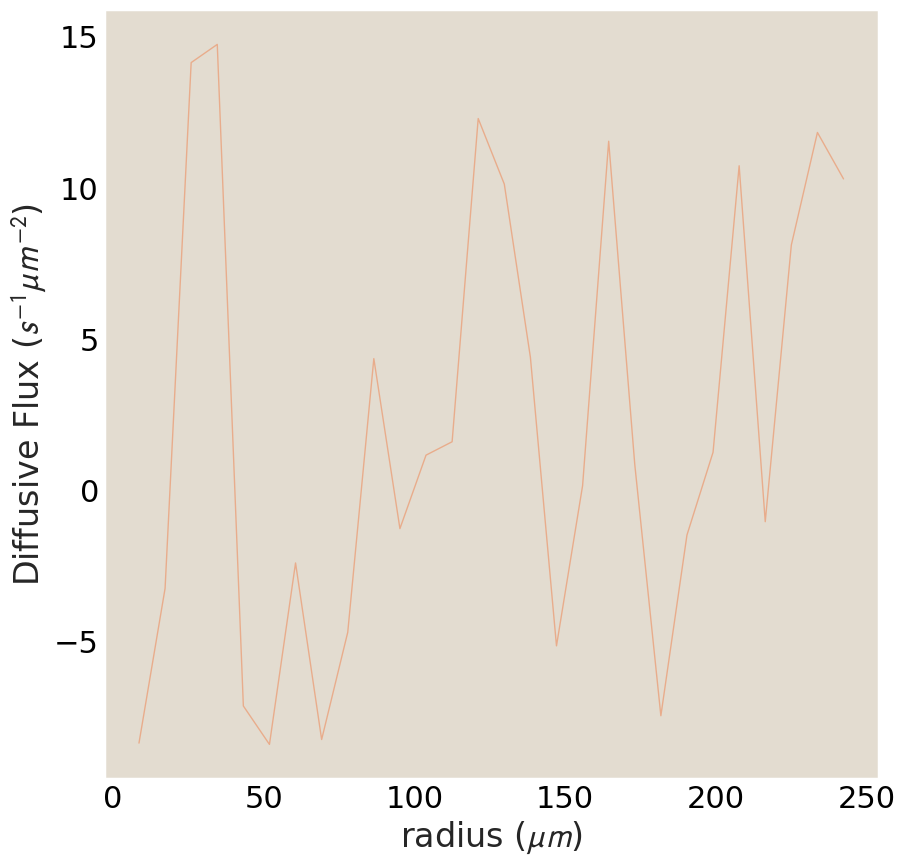

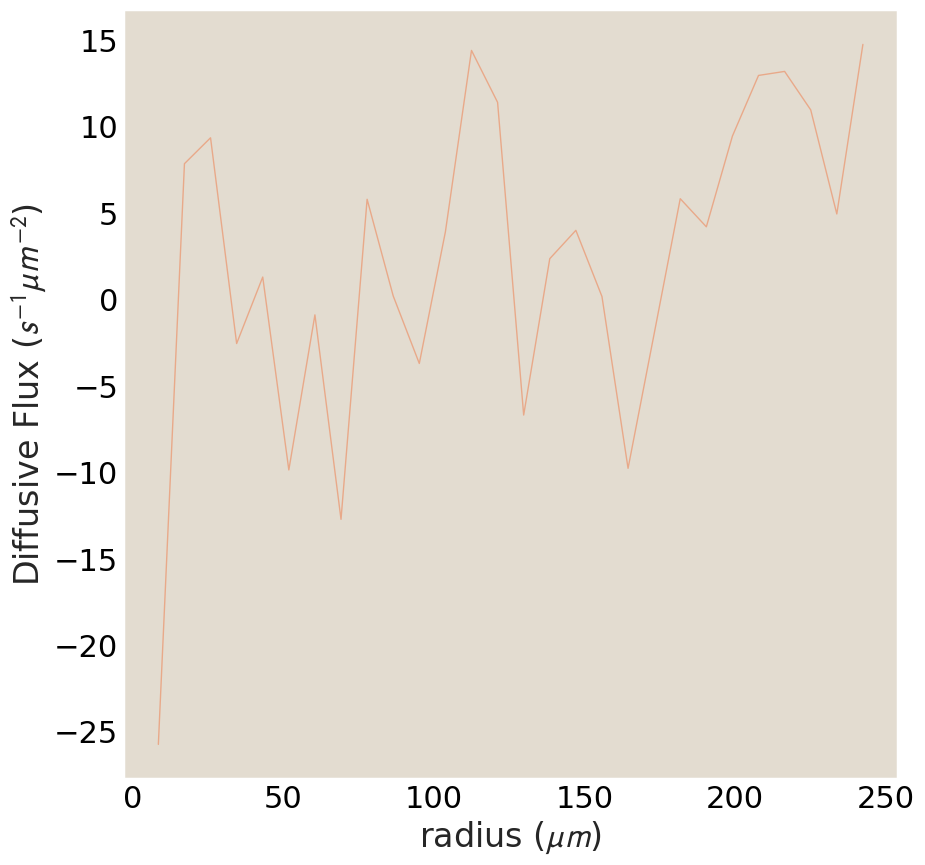

...

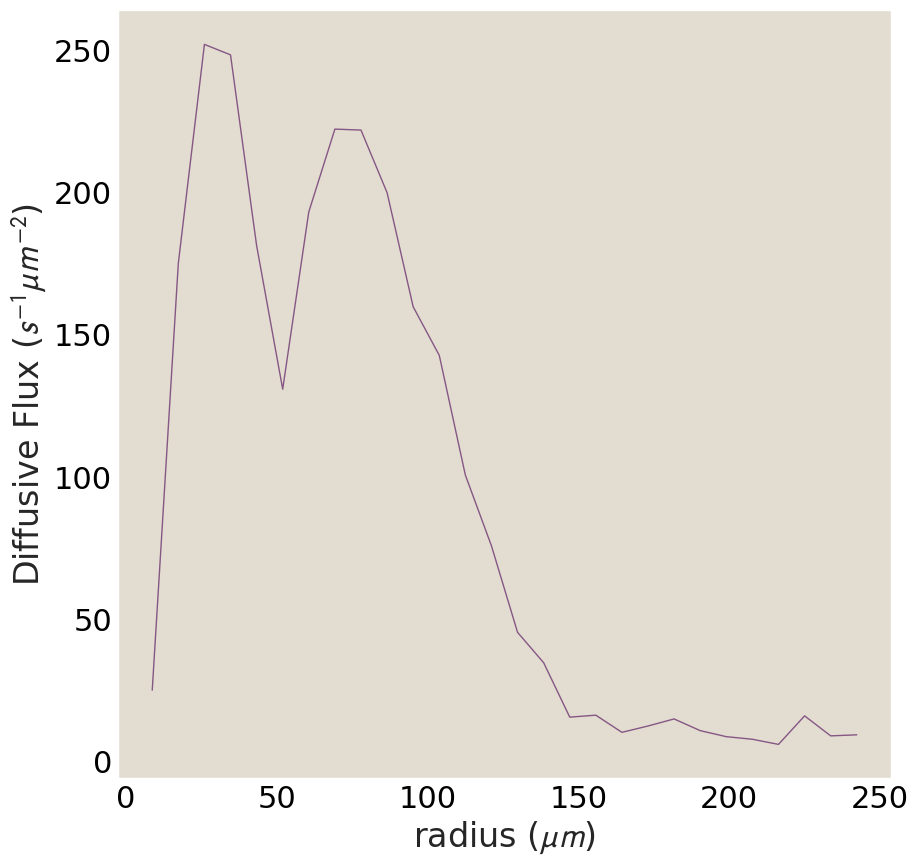

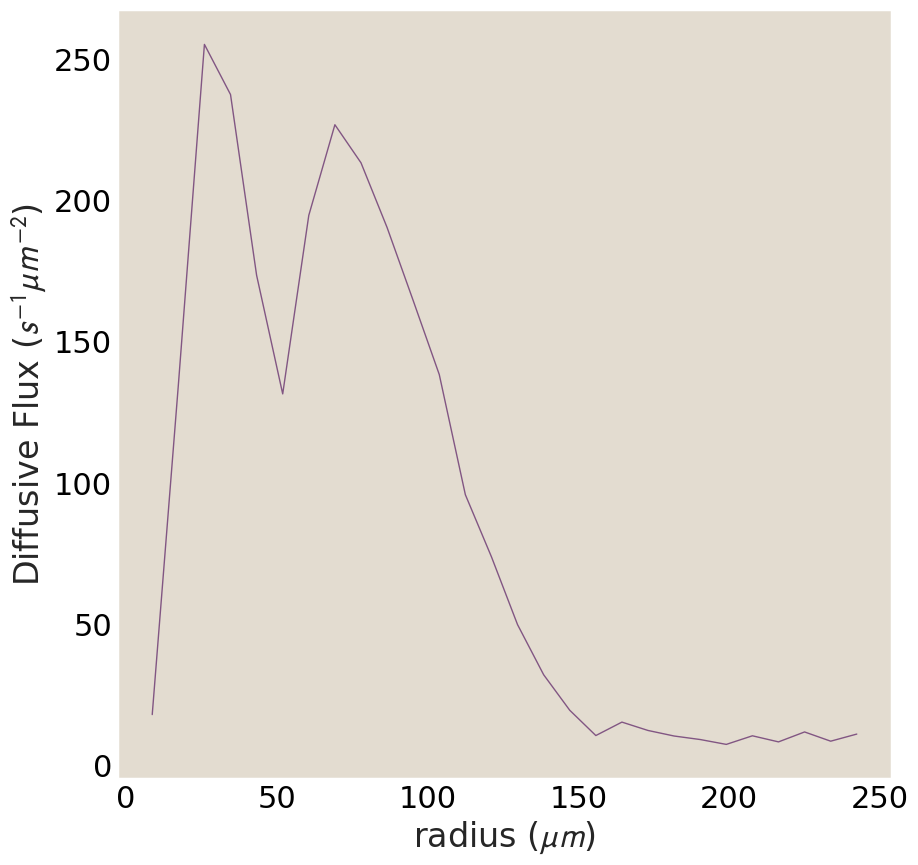

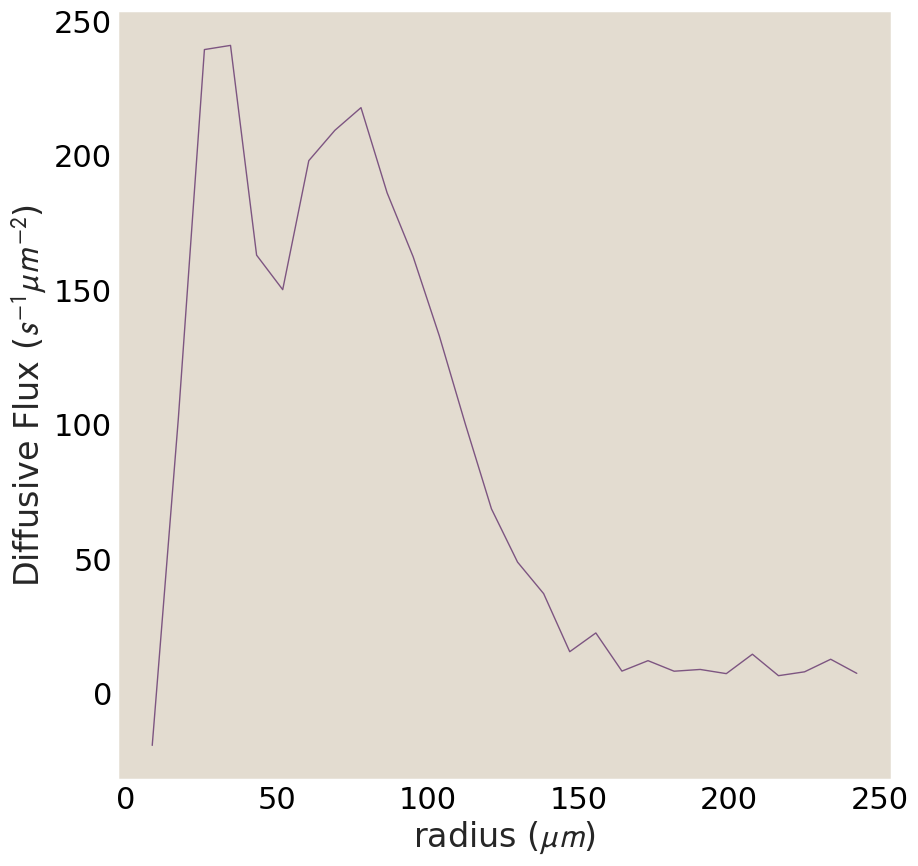

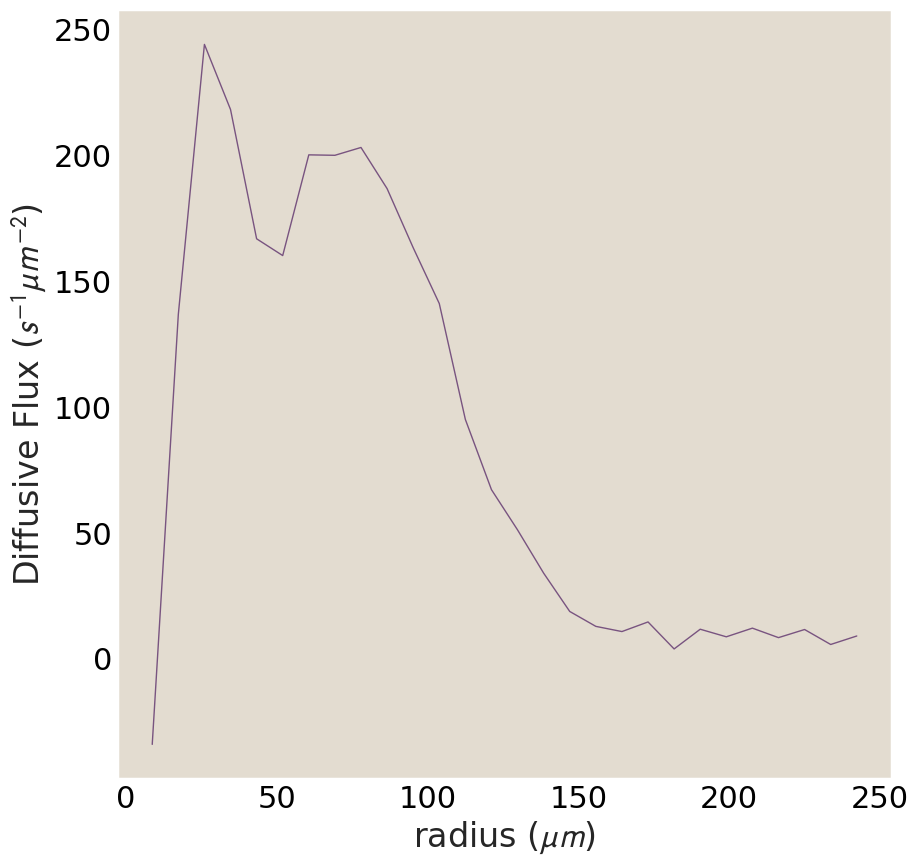

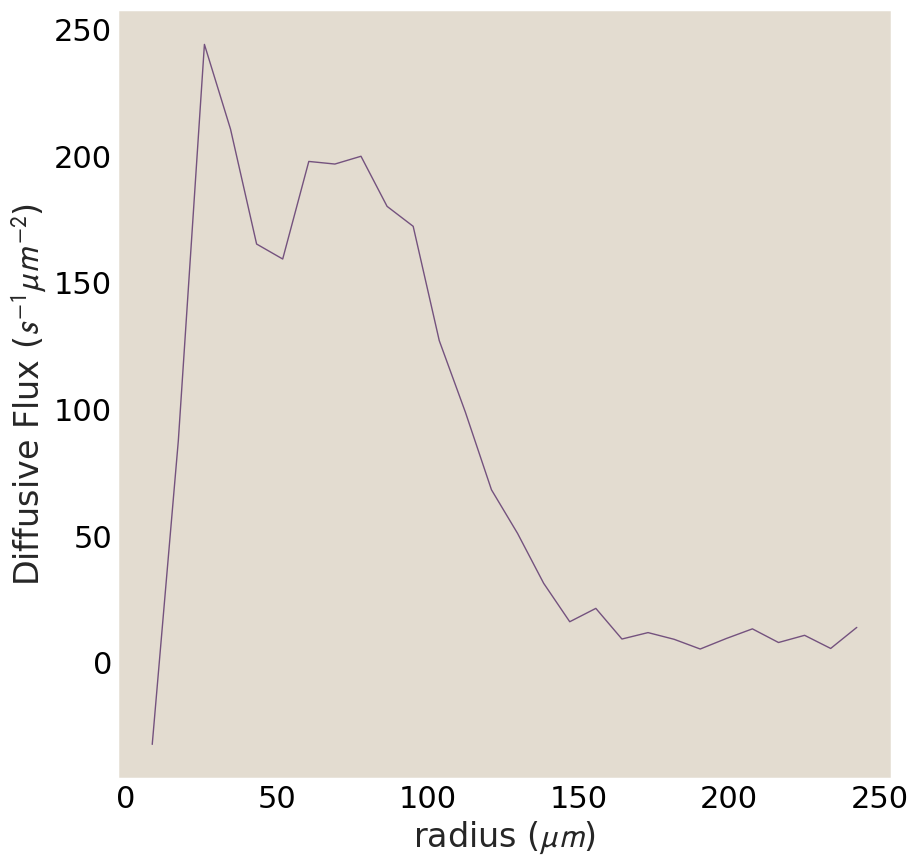

In [268]:
for t in range(0,h5dic['timesMot'].shape[0],5):
    fig, ax = plt.subplots(figsize=(10,10))
    plt.plot((h5dic['all_rMotbins'][0][1:]+h5dic['all_rMotbins'][0][:-1])/2, 
                 Jdiff[t], 
                 color = cbarFtn(h5dic['timesMot'])(t*20),
                 lw=1,
                alpha = 0.75)
    plt.xlabel(r'radius ($\mu m$)')
    plt.ylabel(r'Diffusive Flux ($s^{-1}\mu m^{-2}$)')

Text(0, 0.5, 'Diffusive Flux ($s^{-1}\\mu m^{-2}$)')

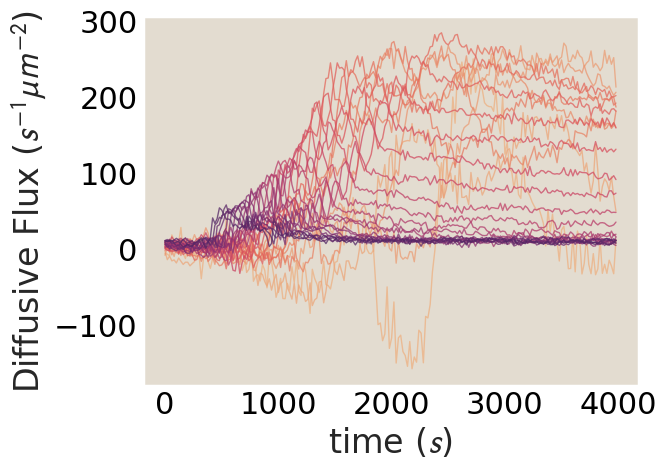

In [269]:
for r, rad in enumerate(h5dic['all_rMotbins'][0,:-1]+np.diff(h5dic['all_rMotbins'][0][:2])/2):
    plt.plot(h5dic['timesMot'], 
             Jdiff[:,r], 
             color = cbarFtn(h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2)(rad),
             lw=1,
            alpha = 0.75)
plt.xlabel(r'time ($s$)')
plt.ylabel(r'Diffusive Flux ($s^{-1}\mu m^{-2}$)')

Text(0, 0.5, 'Source Flux ($s^{-1}\\mu m^{-2}$)')

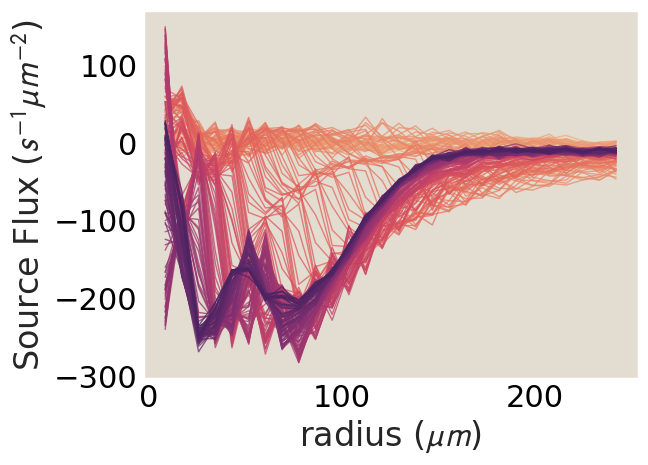

In [270]:
for t, time in enumerate((h5dic['timesMot'][1:]+h5dic['timesMot'][:-1])/2):
    plt.plot((h5dic['all_rMotbins'][0][1:]+h5dic['all_rMotbins'][0][:-1])/2, 
             Jsource[t], 
             color = cbarFtn(h5dic['timesMot'])(time),
             lw=1,
            alpha = 0.75)
plt.xlabel(r'radius ($\mu m$)')
plt.ylabel(r'Source Flux ($s^{-1}\mu m^{-2}$)')

Text(0, 0.5, 'SourceFlux ($s^{-1}\\mu m^{-2}$)')

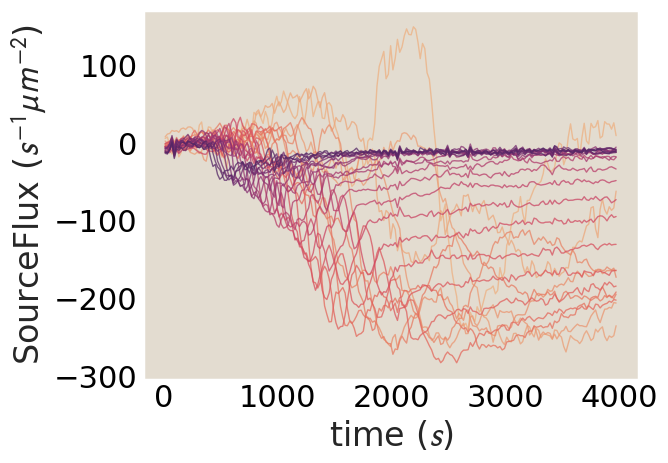

In [271]:
for r, rad in enumerate(h5dic['all_rMotbins'][0,:-1]+np.diff(h5dic['all_rMotbins'][0][:2])/2):
    plt.plot((h5dic['timesMot'][1:]+h5dic['timesMot'][:-1])/2, 
             Jsource[:,r], 
             color = cbarFtn(h5dic['all_rMotbins'][0]+np.diff(h5dic['all_rMotbins'][0][:2])/2)(rad),
             lw=1,
            alpha = 0.75)
plt.xlabel(r'time ($s$)')
plt.ylabel(r'SourceFlux ($s^{-1}\mu m^{-2}$)')

In [272]:
Jdiff = np.diff(h5dic[])

SyntaxError: invalid syntax. Perhaps you forgot a comma? (2619772061.py, line 1)

In [67]:
np.diff(h5dic['timesMot'][:3])

array([20., 20.])

In [69]:
h5dic['all_rMotbins'][0]

array([  4.89655172,  14.68965517,  24.48275862,  34.27586207,
        44.06896552,  53.86206897,  63.65517241,  73.44827586,
        83.24137931,  93.03448276, 102.82758621, 112.62068966,
       122.4137931 , 132.20689655, 142.        , 151.79310345,
       161.5862069 , 171.37931034, 181.17241379, 190.96551724,
       200.75862069, 210.55172414, 220.34482759, 230.13793103,
       239.93103448, 249.72413793, 259.51724138, 269.31034483,
       279.10344828])

# Movie saves

In [20]:
plt.imshow(h5dic['ATP_centCrop'][0],
          cmap=sns.color_palette("crest", as_cmap=True))

NameError: name 'h5dic' is not defined

In [19]:
def crop_inscribed_square(images):
    """
    Crops each image in a T x m x m array to the largest square that can be inscribed in a circle
    of diameter m, centered on the central pixel of the array.

    Parameters:
    images (numpy.ndarray): Input array of shape (T, m, m)

    Returns:
    numpy.ndarray: Cropped array of shape (T, s, s)
    """
    T, m1, m2 = images.shape
    assert m1 == m2, "Input images must be square"
    m = m1

    # Calculate side length s of the largest square inscribed in a circle of diameter m
    s = max(1, int(np.floor(m / np.sqrt(2))))

    # Calculate center index
    center = m // 2

    # Determine start and end indices for cropping
    start = center - s // 2
    end = start + s

    # Adjust indices if they are out of bounds
    if start < 0:
        start = 0
        end = s
    if end > m:
        end = m
        start = m - s

    # Crop the images
    cropped_images = images[:, start:end, start:end]

    return cropped_images

In [20]:
def apply_circular_mask(images, diameter=None):
    """
    Applies a circular mask to each frame in the image array.

    Parameters:
    images (numpy.ndarray): Input array of shape (T, m, m)
    diameter (int, optional): Diameter of the circle. Defaults to m.

    Returns:
    numpy.ndarray: Masked array of shape (T, m, m)
    """
    T, m1, m2 = images.shape
    assert m1 == m2, "Input images must be square"
    m = m1

    if diameter is None:
        diameter = m
    else:
        diameter = min(diameter, m)

    radius = diameter / 2.0

    # Create coordinate grid
    y, x = np.ogrid[:m, :m]
    center_x = (m - 1) / 2.0
    center_y = (m - 1) / 2.0

    # Compute distance from center for each pixel
    distance_from_center = np.sqrt((x - center_x)**2 + (y - center_y)**2)

    # Create mask: pixels within radius are True (1), others are False (0)
    mask = distance_from_center <= radius
    mask = mask.astype(images.dtype)  # Ensure mask has the same data type as images

    # Apply mask to each frame
    masked_images = images * mask

    return masked_images

In [21]:
gname=gnameList[0]
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)

In [22]:
h5dic['ATP_centCrop'].shape

(151, 616, 616)

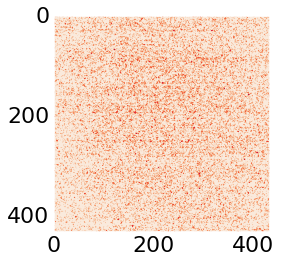

In [23]:
testATPdoublCrop=crop_inscribed_square(h5dic['ATP_centCrop'])
plt.imshow(testATPdoublCrop[0,:,:])

In [24]:
testATPdoublCropCirc=apply_circular_mask(h5dic['ATP_centCrop'])
testMotdoublCropCirc=apply_circular_mask(h5dic['mot_centCrop'])

In [25]:
import matplotlib.patheffects as path_effects

def drawFrame(frame, time, cmap=sns.color_palette("mako", as_cmap=True), norm=None,
              scaleBarDistInum=25, umPerPixel=0.59, ax=None, title=None):
    if not ax:
        fig, ax = plt.subplots(figsize=(5,4))
    img=ax.imshow(frame, cmap=cmap, extent=[-frame.shape[0]//2*umPerPixel, frame.shape[0]//2*umPerPixel, -frame.shape[0]//2*umPerPixel, frame.shape[0]//2*umPerPixel],
             norm=norm)
    ## length of scale bar in pixels
    lengthOfScalebarDataUnits=scaleBarDistInum/umPerPixel
    yScaleBar=0.9*-frame.shape[0]//2*umPerPixel
    xStartScalebar=0.6*(frame.shape[0]//2*umPerPixel)
    
    ax.plot([xStartScalebar, xStartScalebar + lengthOfScalebarDataUnits],
        [yScaleBar, yScaleBar],
        'k',  # Black color
        lw=7,  # Line width for the outer "box"
        solid_capstyle='projecting')  # Square ends)
    ax.plot([xStartScalebar, xStartScalebar+lengthOfScalebarDataUnits], [yScaleBar, yScaleBar], color='whitesmoke', lw=5,
           solid_capstyle='projecting')
    text=ax.text(xStartScalebar+lengthOfScalebarDataUnits/2, yScaleBar, str(scaleBarDistInum)+' $\mu$m', color='whitesmoke', fontsize=13, va='bottom', ha='center')
    text_timestamp=ax.text(xStartScalebar+lengthOfScalebarDataUnits/2, -yScaleBar, str(time)+' min', color='whitesmoke', fontsize=13, va='top', ha='center')

    # Apply the path effect for a black outline
    text.set_path_effects([
        path_effects.Stroke(linewidth=3, foreground='black'),
        path_effects.Normal()
    ])
    text_timestamp.set_path_effects([
        path_effects.Stroke(linewidth=3, foreground='black'),
        path_effects.Normal()
    ])
    if title:
        ax.set_title(title, fontsize=10)
    #remove axis tick labels
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    
    return img

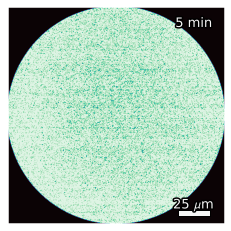

In [26]:
drawFrame(testATPdoublCropCirc[0,:,:], 5)

In [29]:
drawFrame(testATPdoublCrop[0,:,:])

TypeError: drawFrame() missing 1 required positional argument: 'time'

In [27]:
#Movie
import celluloid as cell
import matplotlib.animation as animation

In [28]:
def movie(array, times, cmap=None, titlePrefix='', scaleBarDistInum=25, umPerPixel=0.59, cbarLabel='concentration / $\mu$M', save_path=''):
    fig, ax=plt.subplots(figsize=(5,4))
    camera = cell.Camera(fig)
    if not cmap or not norm:
        goodMin=min(0, np.min(array.flatten()))
        goodMax=np.percentile(array.flatten(), 99)
        
        cmap=sns.color_palette("mako", as_cmap=True)
        norm=matplotlib.colors.Normalize(goodMin, goodMax)
        
    for t in range(array.shape[0]):
        im=drawFrame(array[t,:,:], cmap=cmap, ax=ax, norm=norm, title=str(round(times[t]/60, 3))+' min')
        #ax.axis('off')
        if t==0:
            # Add a colorbar to the same axes
            cbar = plt.colorbar(im, ax=ax)
            cbar.set_label(cbarLabel)  # Optional: Label for the colorbar
            cbar.outline.set_visible(False)
            cbar.ax.tick_params(size=0)
            camera.snap()
        plt.tight_layout()
        camera.snap()  
    animation=camera.animate()
    animation.save(save_path+'_TESTmovie.mp4', fps=6)

/tmp/ipykernel_184763/3078326902.py:21: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


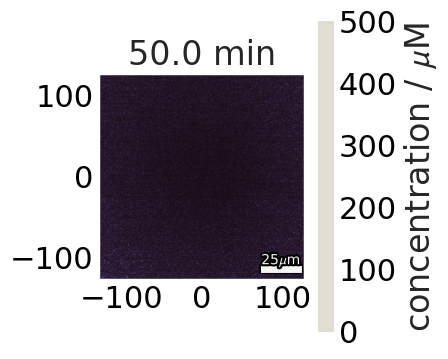

In [187]:
movie(testATPdoublCrop[:,:,:], times=h5dic['timesMot'])

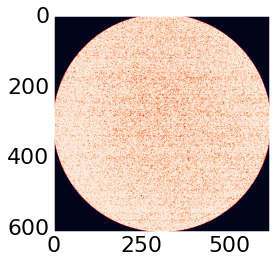

In [88]:
plt.imshow(testATPdoublCropCirc[0])

In [29]:
import skimage.io

In [30]:
def grab_expparams_ome(gname):
    """
    Parses a file name to fine experimental parameters.
    
    Parameters:
    gname (string): data file path.
    
    Returns:
    exp_file (string): Saves the ome.tif name of the dataset.
    interval (integer): The time interval between images in seconds.
    motor_conc (float): The total concentration of motor proteins in µM.
    motor_type (string): The motor species, i.e. NCD or K401.
    ATP_conc (float): The inital concentration of ATP in µM.
    tubulin_conc (float): The concentration of tubulin (in the form of MT) in µM
    probe_conc (float): The concentration of the ATP probe in µM.
    probe_type (string): the species of ATP probe, i.e. A81D or ATeam
    """
    exp_file = gname.split('/')[-1]
    interval = int(exp_file.split('sInter')[0])
    motor_conc = float(exp_file.split('_')[1].split('uM')[0])
    motor_type = exp_file.split('_')[2]
    ATP_conc = float(exp_file.split('_')[4].split('uM')[0])
    tubulin_conc = float(exp_file.split('_')[5].split('uM')[0])
    probe_conc = float(exp_file.split('_')[7].split('uM')[0])
    probe_type = exp_file.split('_')[8]
    
    exp_params = {'exp_file':exp_file,
                 'interval':interval,
                 'motor_conc':motor_conc,
                 'motor_type':motor_type,
                 'ATP_conc':ATP_conc,
                 'tubulin_conc':tubulin_conc,
                 'probe_conc':probe_conc,
                 'probe_type':probe_type}
    return exp_params

In [31]:
def spaceTimeAvg(imgArray, numTimesWindow, spatialBlock, downsampMode = np.nanmean, mode='valid', clip=True):
    """ Also try mode='valid' if you want to only compute time points where the window fits """
    #Do the time averaging assuming numTimesWindow >1
    if numTimesWindow > 1:
        # first, take time running average
        window = np.ones(numTimesWindow) / numTimesWindow
        # 0 refers to first axis (assumed to be time, if imgArray = numTimes x height x width)
        timeAvgd= np.apply_along_axis(lambda m: np.convolve(m, window, mode=mode), 0, imgArray)
    else:
        timeAvgd = imgArray
        
    # next, do space average assuming spatialBlock >1
    if max(spatialBlock) > 1:  
        spaceTimeAvgd=np.zeros((timeAvgd.shape[0], timeAvgd.shape[1]//spatialBlock[0], timeAvgd.shape[1]//spatialBlock[0]))
        for t in range(timeAvgd.shape[0]):
            spaceTimeAvgd[t,:,:]=skimage.measure.block_reduce(timeAvgd[t,:,:],block_size=spatialBlock, func=downsampMode)
    else:
        spaceTimeAvgd = timeAvgd
    
    ## optionally, clip to 99th percentile
    if clip:
        percentile=99.99
        for t in range(spaceTimeAvgd.shape[0]):
            cutOff=np.percentile(spaceTimeAvgd[t,:,:].flatten(), percentile)
            spaceTimeAvgd[t,:,:]=np.where(spaceTimeAvgd[t,:,:]>cutOff, np.nan, spaceTimeAvgd[t,:,:])
    
    return spaceTimeAvgd

In [32]:
def perform_downsamp(arr, timewin, pixelwin, mode=np.nanmean):
    """
    executes the downsampling function safely for a given array and returns a time array
    
    Inputs:
    -------
    arr (np.array): 3d image array of shape
    timewin (integer): number of timesteps to downsample over
    pixelwin (integer): number of pixels to downsample over
    mode (function): method of averaging (i.e. np.nanmean or np.nanmedian)
    
    Returns:
    --------
    times (np.array): 1D array of the frame number corresponding to downsampled images
    arr_downsamped (3d np.array): image array of downsampled data
    """
    
    #Establish time array
    n=arr.shape[0]; #the number of timepoints for this array
    times=1/2*(np.arange(0, n-(timewin-1))+np.arange((timewin-1), n)) 
    
    ###execute the down space timesampling###
    #if pixelwin is not a multiple of the array shape, crop the edge pixels
    if pixelwin != 0:
        offset = arr.shape[-1]%pixelwin
    else:
        offset=0
        
    if offset%2==0:
        if offset==0:
            #dont do anyting
            arr_cropped = arr
        else:
            # trim each side of array evenly
            offset=int(offset/2)
            arr_cropped = arr[:, offset:-offset, offset:-offset]
    else:
        #trim unevenly, we arbitrarily chose
        offset=math.ceil(offset/2)
        arr_cropped = arr[:, (offset-1):-offset, (offset-1):-offset]
        
    #do the downsampling
    arr_downsamped = spaceTimeAvg(arr_cropped, timewin, (pixelwin, pixelwin), downsampMode=mode)
    
    return times, arr_downsamped

In [33]:
testdwnsp = perform_downsamp(h5dic['ATP_centCrop'], 2, 6)

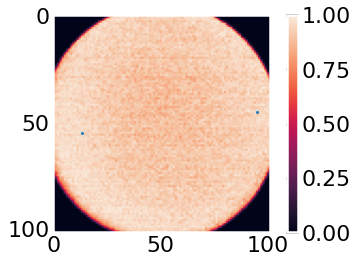

In [34]:
plt.imshow(testdwnsp[1][0])
plt.scatter( [95,13], [45, 55],s=1)
plt.colorbar()

In [35]:
np.where(np.isnan(testdwnsp[1][0]))

(array([45, 55]), array([95, 13]))

In [36]:
np.nanpercentile(testdwnsp[1], 99.9)

np.float64(476.8732010099623)

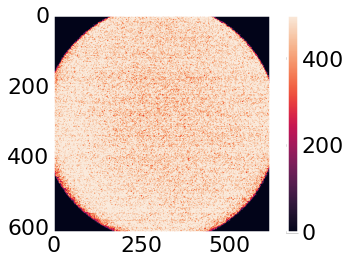

In [37]:
plt.imshow(h5dic['ATP_centCrop'][0])
plt.colorbar()

In [38]:
def ADmovie(array, times, cmap=None, title=None, scaleBarDistInum=25, umPerPixel=0.59, cbarLabel='concentration / µM', save_path=''):
    fig, ax=plt.subplots(figsize=(5,4))
    camera = cell.Camera(fig)
    if not cmap or not norm:
        goodMin=min(0, np.min(array.flatten()))
        goodMax=np.nanpercentile(array.flatten(), 99.9)
        
        cmap=sns.color_palette("mako", as_cmap=True)
        norm=matplotlib.colors.Normalize(goodMin, goodMax)
        #cb_setting = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
        
    for t in range(array.shape[0]):
        im=drawFrame(array[t,:,:], 
                     round(times[t]/60, 1), 
                     cmap=cmap, 
                     ax=ax, 
                     norm=norm, 
                     scaleBarDistInum = scaleBarDistInum,
                     umPerPixel=umPerPixel,
                     title=title)
        #ax.set_title(str(round(times[t] / 60, 3)) + ' min')
        # ax.text(32, 60, str(round(times[t]/60, 3)), color = 'k')
        # ax.text(47, 60, " min", color = 'k')
        #ax.axis('off')
        #plt.tight_layout()
        camera.snap() 
        
    # Add a colorbar to the same axes
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label(cbarLabel, fontsize=15)  # Optional: Label for the colorbar
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(size=0, labelsize = 13)
    
    animation=camera.animate()
    animation.save(save_path+'_movie.mp4', fps=10, dpi=100) # dpi=400 for presentation quality

    plt.close(fig)

In [39]:
gnameList[0]

np.str_('../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos0.ome.tif')

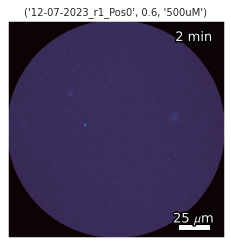

In [40]:
test_title=summarizeGnameVerbose(gnameList[0])
drawFrame(testMotdoublCropCirc[0], 2, title=test_title)

In [41]:
glob.glob(h5spath + '*mot.h5')[0].split('/')[-1].split('mot.h5')[0][-15:]

'20241116_163516'

In [42]:
import time

In [44]:
def movieSaves(gname, ATPtimewin=2, ATPpixelwin=6, Mottimewin=1, Motpixelwin=1, dsmode = np.nanmean):
    curr = time.time()
    # Read in files for given dataset
    h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
    h5dic = read_h5py(h5spath)
    
    #parse params
    summ_param=summarizeGnameVerbose(gname)
    
    #define save path and date of h5 analysis
    save_name = glob.glob(h5spath + '*mot.h5')[0].split('/')[-1].split('mot.h5')[0]
    anal_date = save_name[-15:]
    
    #exp params
    exp_params = grab_expparams_ome(gname)
    
    #downsample
    timesATP, ATP = perform_downsamp(h5dic['ATP_centCrop'], ATPtimewin, ATPpixelwin, mode=dsmode)
    timesMot, mot = perform_downsamp(h5dic['mot_centCrop'], Mottimewin, Motpixelwin, mode=dsmode)
    
    timesATP = timesATP*exp_params['interval']
    timesMot = timesMot*exp_params['interval']
    
    #apply circular mask to images
    ATPCirc = apply_circular_mask(ATP)
    motCirc = apply_circular_mask(mot)
    
    #Make and save movie
    ADmovie(ATPCirc[:,:,:], 
            times=timesATP, 
            umPerPixel=0.59*ATPpixelwin,
            title=str(summ_param)+anal_date, 
            save_path=h5spath+save_name+'_ATPdsTime'+str(ATPtimewin)+'Space'+str(ATPpixelwin));
    
    ADmovie(motCirc[:,:,:], 
            times=timesMot, 
            umPerPixel = 0.59*Motpixelwin,
            title=str(summ_param)+anal_date, 
            save_path=h5spath+save_name+'_motdsTime'+str(Mottimewin)+'Space'+str(Motpixelwin));

    print(gname, time.time()-curr)
    

In [199]:
movieSaves(gnameList[0])

(np.str_('../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos0.ome.tif'),
 65.9386887550354)

#save all the movies eek

In [45]:
# save all the powers
list(concurrent.futures.ProcessPoolExecutor().map(movieSaves, 
                                                  gnameList,
                                                 ))#[(2, 6, 1, 1, np.nanmean) for ii in range(len(gnameList))]))

../../data/aster/Ncd_Aster_assay_12-12-2023/20sInterval_0.3uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2/20sInterval_0.3uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2_MMStack_Pos0.ome.tif 70.21197056770325
../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos0.ome.tif 71.30085635185242
../../data/aster/Ncd_Aster_assay_12-07-2023/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.6uM_Ncd_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1_MMStack_Pos2.ome.tif 77.30552840232849
../../data/aster/Ncd_Aster_assay_12-12-2023/20sInterval_0.2uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_3/20sInterval_0.2uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_3_MMStack_Pos0.ome.tif 84.88199925422668
../../data/aster/Ncd_Aster_assay_12-11-2023/20sInterval_0.75uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_1/20sInterval_0.75uM_NCD_dimers_500uMATP

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [43]:
import time
curr = time.time()
ADmovie(testMotdoublCropCirc[:,:,:], times=h5dic['timesMot'])
print(time.time()-curr)

28.8584201335907


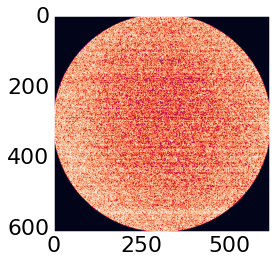

In [41]:
plt.imshow(apply_circular_mask(h5dic['ATP_centCrop'])[10])
#plt.imshow(h5dic['ATP_centCrop'][10])

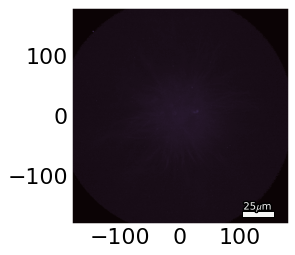

In [56]:
drawFrame(h5dic['mot_centCrop'][100])

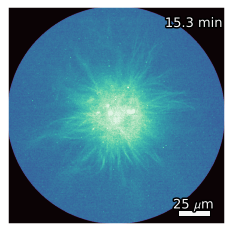

In [86]:
goodMin=min(0, np.min(h5dic['mot_centCrop'].flatten()))
goodMax=np.percentile(h5dic['mot_centCrop'].flatten(), 99.9)
norm=matplotlib.colors.Normalize(goodMin, goodMax)
drawFrame(apply_circular_mask(h5dic['mot_centCrop'])[100], 15.3, norm=norm)

In [ ]:
# def movie2(array, times, cmap=None, titlePrefix='', scaleBarDistInum=25, umPerPixel=0.59, cbarLabel='concentration / $\mu$M', save_path=''):
#     fig, ax=plt.subplots(figsize=(5,4))
#     camera = cell.Camera(fig)
#     if not cmap or not norm:
#         goodMin=min(0, np.min(array.flatten()))
#         goodMax=np.percentile(array.flatten(), 99)
        
#         cmap=sns.color_palette("mako", as_cmap=True)
#         norm=matplotlib.colors.Normalize(goodMin, goodMax)

    
#     t=0
    
#     for t in range(array.shape[0]):
#         im=drawFrame(array[t,:,:], cmap=cmap, ax=ax, norm=norm, title=str(round(times[t]/60, 3))+' min')
#         #ax.axis('off')
#         if t==0:
#             # Add a colorbar to the same axes
#             cbar = plt.colorbar(im, ax=ax)
#             cbar.set_label(cbarLabel)  # Optional: Label for the colorbar
#             cbar.outline.set_visible(False)
#             cbar.ax.tick_params(size=0)
#         plt.tight_layout()
#         camera.snap()  
#     animation=camera.animate()
#     animation.save(save_path+'_TESTmovie.mp4', fps=6)

In [183]:
os.getcwd()

'/home/aduarte/am_atp/analysis/aster'

# APS25 Figures

In [26]:
gname = '../../data/aster/Ncd_Aster_assay_12-12-2023/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2/20sInterval_0.6uM_NCD_dimers_500uMATP_1.3uM_tubulin_2.8uM_A81D_2_MMStack_Pos1.ome.tif'
h5spath=gname.split('data')[0]+'analyzed_data'+gname.split('data')[1]+'/'
h5dic = read_h5py(h5spath)



In [ ]:
plt.